# Cross-platform analysis with HerBERT: Wykop, YouTube, Bluesky

Copy of `notebooks/4_analizy_llm_hate_migrant/cross_platform_hate_analysis.ipynb` (Ola) – **the same sections, methods and charts**,
but with the **hate label from HerBERT** (the best classifier on the gold standard) instead of the LLM labels, and on **all 11
events** available on the three platforms (`events.json`). Hypothesis tests:

| | Hypothesis | Section |
|---|---|---|
| **H1** | Major events related to migrants change the level of hate speech in Polish-language social media. | 1 |
| **H4** | The relationship between events and the level of hate speech differs between YouTube, Wykop and Bluesky. | 1 |
| **H2** | The strength and direction of changes in hate speech depend on the type of event. | 7 |
| H1–H4 with the tests from the README + **H3** (persistence of the effect) | additional analyses | 8 |

**What changes compared with Ola's notebook:**
- label: `hate` = `hate_final` from `data/interim/<platform>/<event>/herbert/comments.csv` (slur dictionary → 1, otherwise:
  HerBERT, p ≥ 0.5) – **general hate**: HerBERT does not distinguish whom it targets,
- comments scored by HerBERT = the team's **topic filter** (`scripts/topic_filter.py`: a slur from the dictionary or a migration
  word in the comment or the post); comments outside the filter are **not treated as 0**,
- two metrics (the equivalent in Ola's notebook in brackets):
  - **`hate/topic`** (main, ≈ `hate_migrant/migrant`) – % of hate among comments on the migration topic,
  - `topic/all` (≈ `migrant/all`) – % of comments on the migration topic among all comments (the filter is applied to every comment),
- 11 events instead of 7 – the types of the 4 new events are assigned in the same way as in Ola's notebook (configuration cell, `EVENT_META`).

Unchanged: the window of **−7..+14 days** (before = −7..−1, after = 0..+14), levels are compared within a platform, platforms are combined
with a meta-analysis, YouTube / Death of the soldier is excluded, at least 30 comments before and after in a cell.
Explanation of the techniques (in Polish): [`docs/METODY_ANALIZY.md`](../../docs/METODY_ANALIZY.md).

*Tables and charts use English event names; folders on disk keep the original ids (`EVENT_IDS` in the configuration cell).
Words in the word charts are Polish lemmas, because the comments are in Polish.*


## 0. Configuration and data

In [1]:
import json
import re
import sys
from collections import Counter
from itertools import combinations
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import simplemma
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import confint_proportions_2indep
from wordcloud import WordCloud

# project root = first directory going up that contains events.json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
sys.path.insert(0, str(ROOT))
from src.lexicon.slurs import find_slurs  # noqa: E402

# ---- configuration ----
PLATFORMS = ["wykop", "youtube", "bluesky"]
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))

# event type (H2) and reach – ASSIGNED MANUALLY (docs/ANALIZA_MIEDZYPLATFORMOWA.md, §2.2)
# keys are the English display names used in all tables and charts
EVENT_META = {
    "EU Pact adopted":      ("political",      "foreign"),
    "Attack on a soldier":  ("criminal",       "domestic"),  # new (not in Ola's analysis)
    "Death of the soldier": ("criminal",       "domestic"),
    "Brawl in Śrem":        ("criminal",       "domestic"),
    "Migration strategy":   ("political",      "domestic"),
    "ICE raids, LA":        ("political",      "foreign"),   # new
    "Kraków murder":        ("disinformation", "domestic"),
    "EU Pact in force":     ("political",      "foreign"),   # new
    "Ceuta mass crossing":  ("border crisis",  "foreign"),
    "Kamienna Góra attack": ("criminal",       "domestic"),
    "Jarosław attack":      ("criminal",       "domestic"),  # new
}
# display name -> event id (folder names on disk and keys of events.json)
EVENT_IDS = {
    "EU Pact adopted": "Pakt_Azyl_PE",
    "Attack on a soldier": "Atak_Zolnierz_Granica",
    "Death of the soldier": "Smierc_Zolnierza",
    "Brawl in Śrem": "Bojka_Srem",
    "Migration strategy": "Strategia_Migracyjna",
    "ICE raids, LA": "Naloty_ICE_Los_Angeles",
    "Kraków murder": "Dezinformacja_Krakow",
    "EU Pact in force": "Pakt_Migracyjny_Wejscie_w_Zycie",
    "Ceuta mass crossing": "Ceuta_Masowe_Przekroczenie",
    "Kamienna Góra attack": "Atak_Kamienna_Gora",
    "Jarosław attack": "Atak_Jaroslaw",
}
EXCLUDE = {("youtube", "Death of the soldier")}  # the whole "before" period is 99 comments under one video

WINDOW = (-7, 14)          # main window (relative_day, comment date)
POST_FROM_DAY = 0          # day 0 belongs to "after"
DAYS_PRE = POST_FROM_DAY - WINDOW[0]
DAYS_POST = WINDOW[1] - POST_FROM_DAY + 1
MIN_LABEL_MATCH = 0.95     # min. share of herbert/ ids present in clean/comments.csv (consistency check)
MIN_N_PERIOD = 30          # min. comments in the before/after period to estimate a cell effect
MIN_K_PRE_TOP = 20         # min. hateful comments "before" for a cell to enter the top 3 ranking
TOP_K = 3
MIN_DAILY_N = 10           # min. comments in a day's denominator to compute a daily share
ROLL_DAYS = 3
TOP_N_WORDS = 30
ALPHA = 0.05

# metric -> (numerator, denominator condition); None = all comments
# columns: "topic" = comment passed the topic filter (has a HerBERT prediction), "hate" = HerBERT hate_final
METRICS = {
    "hate/topic": ("hate", "topic"),
    "topic/all": ("topic", None),
}
MAIN = "hate/topic"
METRIC_NAMES = {
    "hate/topic": "hate (HerBERT) / comments on the migration topic",
    "topic/all": "comments on the migration topic / all comments",
}

CLEAN_COLS = ["comment_id", "relative_day", "thread_id", "author_id", "likes", "text"]

PLATFORM_COLORS = {"wykop": "#2a78d6", "youtube": "#eb6834", "bluesky": "#1baf7a"}
TYPE_ORDER = ["criminal", "political", "disinformation", "border crisis"]
TYPE_COLORS = dict(zip(TYPE_ORDER, ["#c2410c", "#7c3aed", "#0f766e", "#b45309"]))
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#8a8984"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f2f7fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])

plt.rcParams.update({
    "figure.figsize": (13, 4.5), "figure.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)


def fmt_p(t, digits=3):
    # p-value columns as text in scientific notation (round() would turn small p into 0)
    t = t.copy()
    for c in t.columns:
        name = c[0] if isinstance(c, tuple) else c
        if name == "p" or str(name).startswith("p ") or str(name).startswith("p("):
            t[c] = t[c].map(lambda v: "" if pd.isna(v) else f"{v:.3g}")
    return t.round(digits)


def holm(p):
    # Holm correction that lets NaN through
    p = pd.Series(p, dtype=float)
    out = pd.Series(np.nan, index=p.index)
    ok = p.notna()
    if ok.any():
        out[ok] = multipletests(p[ok], method="holm")[1]
    return out


def platform_legend(fig, platforms=None, extra=(), top=0.9, **kw):
    platforms = platforms or PL
    handles = [plt.Line2D([], [], marker="o", ls="", ms=9, color=PLATFORM_COLORS[p]) for p in platforms]
    labels = list(platforms)
    for h, l in extra:
        handles.append(h)
        labels.append(l)
    fig.tight_layout(rect=(0, 0, 1, top))
    fig.legend(handles, labels, loc="upper center", ncol=len(labels), bbox_to_anchor=(0.5, 1.0), **kw)

### Loading and labels

For each platform and event the base is **all comments from `clean/comments.csv`**, to which we attach the HerBERT
predictions from `herbert/comments.csv` (LEFT JOIN on `comment_id`):

| column | meaning |
|---|---|
| `topic` | the comment is in the topic filter (it has a HerBERT prediction) |
| `hate` | `hate_final` = 1 (slur dictionary or HerBERT p ≥ 0.5); computed only within `topic` |

Comments outside the filter have `topic = 0` and do not enter the `hate/topic` metric (they are not treated as "not hateful").


In [2]:
def to_bool(s):
    return s.fillna(False).astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


def flag(d, cols):
    # logical OR over all listed columns that exist in the data
    out = pd.Series(False, index=d.index)
    for c in cols:
        if c in d.columns:
            out |= to_bool(d[c])
    return out


def load_event(platform, event):
    event_id = EVENT_IDS[event]
    event_dir = ROOT / "data" / "interim" / platform / f"{EVENTS[event_id]}_{event_id}"
    herb_file = event_dir / "herbert" / "comments.csv"
    if not (event_dir / "clean" / "comments.csv").exists():
        return None, "missing clean/comments.csv"
    if not herb_file.exists():
        return None, "missing herbert/comments.csv"
    clean = pd.read_csv(event_dir / "clean" / "comments.csv", encoding="utf-8-sig", usecols=CLEAN_COLS,
                        dtype={"comment_id": str, "thread_id": str, "author_id": str}).drop_duplicates("comment_id")
    herb = pd.read_csv(herb_file, encoding="utf-8-sig", usecols=["comment_id", "hate_final"],
                       dtype={"comment_id": str}).drop_duplicates("comment_id")
    match = herb["comment_id"].isin(clean["comment_id"]).mean()
    if match < MIN_LABEL_MATCH:
        return None, f"only {match:.0%} of herbert/ ids are in clean/comments.csv – cell skipped"
    h = herb.set_index("comment_id")["hate_final"]
    d = clean.copy()
    d["topic"] = d["comment_id"].isin(h.index)
    d["hate"] = d["topic"] & d["comment_id"].map(h).fillna(0).astype(int).astype(bool)

    # keep the text only where it is needed (words, groups, slurs) – saves memory on YouTube
    d["text"] = d["text"].fillna("").astype(str).where(d["topic"], "")
    d = d[["comment_id", "relative_day", "thread_id", "author_id", "likes", "text", "topic", "hate"]].copy()
    d["platform"], d["event"] = platform, event
    d["type"], d["reach"] = EVENT_META[event]
    d["cell"] = platform + ":" + event
    d["thread"] = d["cell"] + ":" + d["thread_id"].astype(str)  # threads kept separate between cells
    # comment id unique within a platform: on YouTube and Bluesky pseudonyms (K000001…) are assigned
    # anew for each event; on Wykop the id is global (the same comment can fall in two overlapping windows)
    d["uid"] = d["comment_id"] if platform == "wykop" else event_id + ":" + d["comment_id"]
    return d, None


frames, skipped = [], {}
for platform in PLATFORMS:
    for event in EVENT_META:
        if (platform, event) in EXCLUDE:
            continue
        d, why = load_event(platform, event)
        if d is None:
            skipped[f"{platform}:{event}"] = why
        else:
            frames.append(d)
for cell, why in skipped.items():
    if not why.startswith("missing"):
        print(f"SKIPPED CELL {cell}: {why}")
full = pd.concat(frames, ignore_index=True)

PL = [p for p in PLATFORMS if p in set(full["platform"])]
EVENT_ORDER = [e for e in EVENT_META if e in set(full["event"])]  # chronological
CELLS = [f"{p}:{e}" for p in PL for e in EVENT_ORDER if f"{p}:{e}" in set(full["cell"])]
COMMON_EVENTS = [e for e in EVENT_ORDER if all(f"{p}:{e}" in CELLS for p in PL)]

df = full[full["relative_day"].between(*WINDOW)].copy()
df["post"] = (df["relative_day"] >= POST_FROM_DAY).astype(int)
df["period"] = np.where(df["post"] == 1, "after", "before")

print(f"event × platform cells: {len(CELLS)}  ({', '.join(f'{p}: {sum(c.startswith(p) for c in CELLS)}' for p in PL)})")
print("events common to all platforms:", COMMON_EVENTS)
print(f"comments in window {WINDOW}: {len(df):,} (of {len(full):,} loaded)")

SKIPPED CELL wykop:EU Pact in force: only 42% of herbert/ ids are in clean/comments.csv – cell skipped
SKIPPED CELL wykop:Jarosław attack: only 57% of herbert/ ids are in clean/comments.csv – cell skipped


event × platform cells: 30  (wykop: 9, youtube: 10, bluesky: 11)
events common to all platforms: ['EU Pact adopted', 'Attack on a soldier', 'Brawl in Śrem', 'Migration strategy', 'ICE raids, LA', 'Kraków murder', 'Ceuta mass crossing', 'Kamienna Góra attack']
comments in window (-7, 14): 1,123,270 (of 1,379,353 loaded)


In [3]:
overview = (df.groupby(["platform", "event"], sort=False)
            .agg(comments=("comment_id", "size"),
                 before=("post", lambda s: int((s == 0).sum())), after=("post", "sum"),
                 threads=("thread", "nunique"),
                 topic=("topic", "sum"), hate=("hate", "sum")))
overview.insert(0, "type", [EVENT_META[e][0] for _, e in overview.index])
overview["topic %"] = 100 * overview["topic"] / overview["comments"]
overview["hate %"] = 100 * overview["hate"] / overview["comments"]
overview["hate | topic %"] = 100 * (
    df[df["topic"]].groupby(["platform", "event"], sort=False)["hate"].mean().reindex(overview.index))
display(overview.round(2))
print("Levels (%) are compared only within a platform – differences between platforms mainly reflect how the data were collected.")

type  comments  before  after  threads  topic   hate  topic %  hate %  hate | topic %
platform event                                                                                                                
wykop    EU Pact adopted            political     10412    3458   6954      501   7584   2358    72.84   22.65           31.09
         Attack on a soldier         criminal     10815    2862   7953      279   8705   3115    80.49   28.80           35.78
         Death of the soldier        criminal     10543    2991   7552      234   8752   3157    83.01   29.94           36.07
         Brawl in Śrem               criminal     10473    3408   7065      534   8004   2659    76.43   25.39           33.22
         Migration strategy         political      9551    3227   6324      408   7428   2499    77.77   26.16           33.64
         ICE raids, LA              political      9741    3458   6283      417   7302   2095    74.96   21.51           28.69
         Kraków murder         disinformation      7559    2468   5091      650   6059   1803    80.16   23.85           29.76
         Ceuta mass crossing    border crisis     10266    3579   6687      708   8414   2969    81.96   28.92           35.29
         Kamienna Góra attack        criminal      9058    2924   6134      733   6684   2328    73.79   25.70           34.83
youtube  EU Pact adopted            political     87296   35967  51329      509   9123   3134    10.45    3.59           34.35
         Attack on a soldier         criminal     99842   25795  74047      569  25736  11584    25.78   11.60           45.01
         Brawl in Śrem               criminal    107271   27959  79312      856   9808   4244     9.14    3.96           43.27
         Migration strategy         political    114604   25699  88905      891  14821   6436    12.93    5.62           43.42
         ICE raids, LA              political    110929   40675  70254      619   5606   2573     5.05    2.32           45.90
         Kraków murder         disinformation     54430   17573  36857      662   5853   2684    10.75    4.93           45.86
         EU Pact in force           political     86518   18909  67609      617  22051  10036    25.49   11.60           45.51
         Ceuta mass crossing    border crisis     63939   16961  46978      647  16233   7074    25.39   11.06           43.58
         Kamienna Góra attack        criminal    105881   14833  91048     1000  13686   6251    12.93    5.90           45.67
         Jarosław attack             criminal    133009   34084  98925     1330  22554   9282    16.96    6.98           41.15
bluesky  EU Pact adopted            political        74      16     58       26      4      0     5.41    0.00            0.00
         Attack on a soldier         criminal        39      11     28       17      8      0    20.51    0.00            0.00
         Death of the soldier        criminal        48      16     32       18      7      0    14.58    0.00            0.00
         Brawl in Śrem               criminal        64       7     57       25     14      1    21.88    1.56            7.14
         Migration strategy         political       359      27    332      113     32      1     8.91    0.28            3.12
         ICE raids, LA              political     20562    9206  11356     5417   3571    620    17.37    3.02           17.36
         Kraków murder         disinformation      9236    2976   6260     2733   1924    357    20.83    3.87           18.56
         EU Pact in force           political     13140    3927   9213     3460   5299   1146    40.33    8.72           21.63
         Ceuta mass crossing    border crisis      9715    3061   6654     2663   3046    705    31.35    7.26           23.15
         Kamienna Góra attack        criminal      8871    2780   6091     2365   2228    405    25.12    4.57           18.18
         Jarosław attack             criminal      9025    3046   5979     2487   2571    501    28.49  

Levels (%) are compared only within a platform – differences between platforms mainly reflect how the data were collected.


## 1. Share before and after, number of hateful comments and of comments (H1, H4)

For each event × platform cell and each metric:
- % before and % after, the **difference in pp** with a 95% CI (Newcombe),
- **RR** (relative risk) with a 95% CI,
- **OR from the logistic regression `y ~ post` with standard errors clustered by thread** – the tests and the meta-analysis rely on it,
- p with the **Holm correction** within a metric (all cells),
- counts as a **daily mean** before (7 days) and after (15 days).

Four views: (a) events separately on each platform, (b) events pooled across platforms,
(c) before / after pooled across events, separately per platform, (d) before / after pooled across events and platforms.

In [4]:
def woolf(k1, n1, k2, n2):
    # log OR with a 0.5 correction – fallback when the regression fails (zeros in a cell)
    a, b, c, e = k2 + 0.5, n2 - k2 + 0.5, k1 + 0.5, n1 - k1 + 0.5
    lor, se = np.log(a * e / (b * c)), np.sqrt(1 / a + 1 / b + 1 / c + 1 / e)
    return lor, se, 2 * stats.norm.sf(abs(lor / se))


def logit_cluster(d, col, formula):
    return smf.logit(formula, data=d.assign(y=d[col].astype(int))).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]}, maxiter=200)


def cell_effect(d, col):
    pre, post = d.loc[d["post"] == 0, col], d.loc[d["post"] == 1, col]
    k1, n1, k2, n2 = int(pre.sum()), len(pre), int(post.sum()), len(post)
    out = {"n before": n1, "n after": n2, "k before": k1, "k after": k2,
           "before %": 100 * k1 / n1 if n1 else np.nan, "after %": 100 * k2 / n2 if n2 else np.nan}
    if min(n1, n2) < MIN_N_PERIOD or k1 + k2 == 0:
        return out
    p1, p2 = k1 / n1, k2 / n2
    lo, hi = confint_proportions_2indep(k2, n2, k1, n1, method="newcomb")
    if 0 < k1 < n1 and 0 < k2 < n2:
        try:
            m = logit_cluster(d, col, "y ~ post")
            b, se, p = m.params["post"], m.bse["post"], m.pvalues["post"]
        except Exception:
            b, se, p = woolf(k1, n1, k2, n2)
        rr, se_rr = np.log(p2 / p1), np.sqrt(1 / k2 - 1 / n2 + 1 / k1 - 1 / n1)
    else:
        b, se, p = woolf(k1, n1, k2, n2)
        rr, se_rr = np.nan, np.nan
    return {**out, "diff pp": 100 * (p2 - p1), "CI lo pp": 100 * lo, "CI hi pp": 100 * hi,
            "RR": np.exp(rr), "RR lo": np.exp(rr - 1.96 * se_rr), "RR hi": np.exp(rr + 1.96 * se_rr),
            "log OR": b, "se": se, "OR": np.exp(b), "OR lo": np.exp(b - 1.96 * se), "OR hi": np.exp(b + 1.96 * se),
            "p": p}


def subset(d, metric):
    col, cond = METRICS[metric]
    return (d[d[cond]] if cond else d), col


def effects(data, metrics=METRICS):
    rows = []
    for cell, d in data.groupby("cell", sort=False):
        p, e = cell.split(":")
        for metric in metrics:
            dd, col = subset(d, metric)
            rows.append({"metric": metric, "cell": cell, "platform": p, "event": e,
                         "type": EVENT_META[e][0], "reach": EVENT_META[e][1], **cell_effect(dd, col)})
    out = pd.DataFrame(rows)
    out["p (Holm)"] = out.groupby("metric")["p"].transform(holm)
    out["significant"] = out["p (Holm)"] < ALPHA
    out["direction"] = np.select([out["significant"] & (out["log OR"] > 0), out["significant"] & (out["log OR"] < 0)],
                                ["↑", "↓"], "–")
    return out


eff = effects(df)
eff["cell"] = pd.Categorical(eff["cell"], CELLS, ordered=True)
eff = eff.sort_values(["metric", "cell"]).reset_index(drop=True)
eff["cell"] = eff["cell"].astype(str)


def E(metric):
    return eff[eff["metric"] == metric]

In [5]:
def meta_random(y, se):
    """Random-effects meta-analysis: DerSimonian–Laird + Hartung–Knapp interval (t, k-1 df)."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~(np.isnan(y) | np.isnan(se))
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0, "mu": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan,
                "tau2": np.nan, "I2": np.nan, "Q": np.nan, "p Q": np.nan}
    w = 1 / se ** 2
    fixed = (w * y).sum() / w.sum()
    q = (w * (y - fixed) ** 2).sum()
    if k == 1:
        return {"k": 1, "mu": y[0], "se": se[0], "lo": y[0] - 1.96 * se[0], "hi": y[0] + 1.96 * se[0],
                "p": 2 * stats.norm.sf(abs(y[0] / se[0])), "tau2": 0.0, "I2": np.nan, "Q": np.nan, "p Q": np.nan}
    c = w.sum() - (w ** 2).sum() / w.sum()
    tau2 = max(0.0, (q - (k - 1)) / c)
    ws = 1 / (se ** 2 + tau2)
    mu = (ws * y).sum() / ws.sum()
    se_hk = max(np.sqrt((ws * (y - mu) ** 2).sum() / ((k - 1) * ws.sum())), np.sqrt(1 / ws.sum()))
    t = stats.t.ppf(1 - ALPHA / 2, k - 1)
    return {"k": k, "mu": mu, "se": se_hk, "lo": mu - t * se_hk, "hi": mu + t * se_hk,
            "p": 2 * stats.t.sf(abs(mu / se_hk), k - 1), "tau2": tau2,
            "I2": max(0.0, (q - (k - 1)) / q) if q > 0 else 0.0, "Q": q, "p Q": stats.chi2.sf(q, k - 1)}


def meta_fixed(y, se):
    """Fixed-effect meta-analysis (weights 1/se²) – used per event, when there are 2–3 platforms."""
    y, se = np.asarray(y, float), np.asarray(se, float)
    ok = ~(np.isnan(y) | np.isnan(se))
    y, se = y[ok], se[ok]
    k = len(y)
    if k == 0:
        return {"k": 0, "mu": np.nan, "se": np.nan, "lo": np.nan, "hi": np.nan, "p": np.nan, "I2": np.nan, "p Q": np.nan}
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    s = np.sqrt(1 / w.sum())
    q = (w * (y - mu) ** 2).sum()
    return {"k": k, "mu": mu, "se": s, "lo": mu - 1.96 * s, "hi": mu + 1.96 * s,
            "p": 2 * stats.norm.sf(abs(mu / s)),
            "I2": max(0.0, (q - (k - 1)) / q) if k > 1 and q > 0 else np.nan,
            "p Q": stats.chi2.sf(q, k - 1) if k > 1 else np.nan}


def q_test(y, se):
    # Q test: do the effects (e.g. pooled platform effects) differ more than expected by chance
    y, se = np.asarray(y, float), np.asarray(se, float)
    w = 1 / se ** 2
    mu = (w * y).sum() / w.sum()
    q = (w * (y - mu) ** 2).sum()
    return q, stats.chi2.sf(q, len(y) - 1)


def or_row(m):
    return {"OR": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p": m["p"]}


def dia(m, color):
    # forest-plot diamond from a meta-analysis result
    return {"OR": np.exp(m["mu"]), "lo": np.exp(m["lo"]), "hi": np.exp(m["hi"]), "color": color}


def forest(ax, groups, title="", xlabel="OR after vs before (log scale)"):
    """Forest plot. groups = [{"label", "items": [{"label", "OR", "lo", "hi", "color"}], "diamond": {...} | None}]"""
    y, ticks, labels, bold, xs = 0.0, [], [], [], [1.0]
    for g in groups:
        for it in g["items"]:
            if pd.isna(it["OR"]):
                continue
            ax.hlines(y, it["lo"], it["hi"], color=it["color"], lw=1.6)
            ax.scatter(it["OR"], y, s=44, color=it["color"], edgecolor="white", linewidth=1.1, zorder=3)
            ticks.append(y)
            labels.append(it["label"])
            bold.append(False)
            xs += [it["lo"], it["hi"]]
            y -= 1
        m = g.get("diamond")
        if m is not None and not pd.isna(m["OR"]):
            ax.fill([m["lo"], m["OR"], m["hi"], m["OR"]], [y, y + 0.32, y, y - 0.32], color=m.get("color", INK), zorder=3)
            ax.text(m["hi"], y, f"  {m['OR']:.2f} [{m['lo']:.2f}; {m['hi']:.2f}]", va="center", fontsize=8, color=INK2)
            ticks.append(y)
            labels.append(g["label"])
            bold.append(True)
            xs += [m["lo"], m["hi"]]
            y -= 1
        y -= 0.6
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_xscale("log")
    xmin, xmax = np.nanmin(xs) * 0.85, np.nanmax(xs) * 1.9
    ax.set_xlim(xmin, xmax)
    log_ticks(ax, "x")
    ax.set_yticks(ticks, labels, fontsize=8.5)
    for lab, b in zip(ax.get_yticklabels(), bold):
        if b:
            lab.set_fontweight("bold")
    ax.set_ylim(y + 0.4, 0.8)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel(xlabel)
    ax.set_title(title, fontsize=11)


def log_ticks(ax, axis="x"):
    # readable ticks on a log axis (no overlapping labels)
    lo, hi = ax.get_xlim() if axis == "x" else ax.get_ylim()
    tk = [t for t in [0.05, 0.1, 0.25, 0.5, 1, 2, 4, 10, 20] if lo <= t <= hi]
    if len(tk) < 3:
        tk = [t for t in [0.05, 0.1, 0.2, 0.33, 0.5, 0.67, 1, 1.5, 2, 3, 5, 10, 20] if lo <= t <= hi]
    a = ax.xaxis if axis == "x" else ax.yaxis
    (ax.set_xticks if axis == "x" else ax.set_yticks)(tk, [f"{t:g}" for t in tk])
    a.set_minor_locator(mticker.NullLocator())


def items_from(e, label_col, color_fn):
    return [{"label": r[label_col], "OR": r["OR"], "lo": r["OR lo"], "hi": r["OR hi"], "color": color_fn(r)}
            for _, r in e.iterrows()]

### 1a. Events separately, on each platform

Table of all cells. `direction`: ↑ / ↓ = significant change after the Holm correction, – = no significant change.

In [6]:
show = ["type", "before %", "after %", "diff pp", "CI lo pp", "CI hi pp", "RR", "RR lo", "RR hi",
        "OR", "OR lo", "OR hi", "p (Holm)", "direction"]
for metric in METRICS:
    print(f"\n=== {metric}: {METRIC_NAMES[metric]} ===")
    display(fmt_p(E(metric).set_index(["platform", "event"])[show], 2))


=== hate/topic: hate (HerBERT) / comments on the migration topic ===


type  before %  after %  diff pp  CI lo pp  CI hi pp    RR  RR lo  RR hi    OR  OR lo  OR hi  p (Holm) direction
platform event                                                                                                                                           
wykop    EU Pact adopted            political     27.58    32.30     4.72      2.36      7.02  1.17   1.08   1.27  1.25   1.01   1.55     0.756         –
         Attack on a soldier         criminal     32.21    36.86     4.65      2.28      6.97  1.14   1.07   1.23  1.23   1.01   1.49     0.756         –
         Death of the soldier        criminal     36.80    35.78    -1.03     -3.26      1.18  0.97   0.91   1.03  0.96   0.83   1.11         1         –
         Brawl in Śrem               criminal     34.20    32.81    -1.38     -3.67      0.87  0.96   0.90   1.03  0.94   0.77   1.14         1         –
         Migration strategy         political     33.99    33.47    -0.52     -2.81      1.74  0.98   0.92   1.05  0.98   0.80   1.19         1         –
         ICE raids, LA              political     24.32    31.74     7.42      5.34      9.48  1.31   1.21   1.41  1.45   1.22   1.72  0.000529         ↑
         Kraków murder         disinformation     26.11    31.44     5.33      2.88      7.73  1.20   1.10   1.31  1.30   1.05   1.61      0.38         –
         Ceuta mass crossing    border crisis     35.20    35.34     0.14     -1.98      2.25  1.00   0.95   1.07  1.01   0.87   1.17         1         –
         Kamienna Góra attack        criminal     36.77    33.75    -3.02     -5.42     -0.64  0.92   0.86   0.98  0.88   0.76   1.02         1         –
youtube  EU Pact adopted            political     39.58    33.17    -6.42     -9.00     -3.87  0.84   0.78   0.90  0.76   0.44   1.30         1         –
         Attack on a soldier         criminal     41.36    45.27     3.91      1.49      6.29  1.09   1.03   1.16  1.17   0.73   1.87         1         –
         Brawl in Śrem               criminal     45.01    42.68    -2.33     -4.59     -0.08  0.95   0.90   1.00  0.91   0.59   1.39         1         –
         Migration strategy         political     40.39    44.29     3.90      1.98      5.79  1.10   1.05   1.15  1.17   0.90   1.52         1         –
         ICE raids, LA              political     39.19    52.54    13.35     10.75     15.92  1.34   1.27   1.42  1.72   1.20   2.45    0.0681         –
         Kraków murder         disinformation     47.57    44.64    -2.93     -5.52     -0.34  0.94   0.89   0.99  0.89   0.64   1.24         1         –
         EU Pact in force           political     49.36    44.32    -5.04     -6.59     -3.49  0.90   0.87   0.93  0.82   0.58   1.14         1         –
         Ceuta mass crossing    border crisis     45.88    42.29    -3.59     -5.18     -2.00  0.92   0.89   0.96  0.86   0.71   1.05         1         –
         Kamienna Góra attack        criminal     45.59    45.68     0.09     -2.75      2.91  1.00   0.94   1.07  1.00   0.73   1.37         1         –
         Jarosław attack             criminal     43.39    39.78    -3.61     -4.94     -2.29  0.92   0.89   0.95  0.86   0.66   1.13         1         –
bluesky  EU Pact adopted            political       NaN     0.00      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Attack on a soldier         criminal      0.00     0.00      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Death of the soldier        criminal      0.00      NaN      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Brawl in Śrem               criminal      0.00     7.69      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Migration strategy         political      0.00     3.45      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         ICE raids, LA              p


=== topic/all: comments on the migration topic / all comments ===


type  before %  after %  diff pp  CI lo pp  CI hi pp    RR  RR lo  RR hi    OR  OR lo  OR hi  p (Holm) direction
platform event                                                                                                                                           
wykop    EU Pact adopted            political     56.10    81.16    25.06     23.17     26.95  1.45   1.40   1.49  3.37   1.62   7.02    0.0279         ↑
         Attack on a soldier         criminal     70.41    84.12    13.71     11.88     15.59  1.19   1.16   1.23  2.23   0.93   5.34         1         –
         Death of the soldier        criminal     84.49    82.43    -2.06     -3.59     -0.47  0.98   0.96   0.99  0.86   0.33   2.25         1         –
         Brawl in Śrem               criminal     69.07    79.97    10.90      9.10     12.72  1.16   1.13   1.19  1.79   0.90   3.55         1         –
         Migration strategy         political     77.04    78.15     1.11     -0.65      2.90  1.01   0.99   1.04  1.07   0.45   2.52         1         –
         ICE raids, LA              political     86.70    68.50   -18.20    -19.79    -16.56  0.79   0.77   0.81  0.33   0.15   0.74     0.157         –
         Kraków murder         disinformation     77.59    81.40     3.81      1.87      5.79  1.05   1.02   1.08  1.26   0.62   2.58         1         –
         Ceuta mass crossing    border crisis     87.01    79.26    -7.75     -9.20     -6.26  0.91   0.90   0.93  0.57   0.30   1.10         1         –
         Kamienna Góra attack        criminal     82.05    69.86   -12.19    -13.97    -10.36  0.85   0.83   0.87  0.51   0.26   0.97     0.781         –
youtube  EU Pact adopted            political      4.68    14.49     9.81      9.43     10.18  3.09   2.94   3.26  3.45   1.62   7.32    0.0292         ↑
         Attack on a soldier         criminal      6.71    32.42    25.71     25.25     26.16  4.83   4.61   5.06  6.67   2.78  15.98  0.000519         ↑
         Brawl in Śrem               criminal      8.96     9.21     0.25     -0.14      0.64  1.03   0.98   1.07  1.03   0.51   2.07         1         –
         Migration strategy         political     12.76    12.98     0.23     -0.24      0.69  1.02   0.98   1.06  1.02   0.50   2.07         1         –
         ICE raids, LA              political      6.86     4.01    -2.85     -3.13     -2.56  0.58   0.56   0.62  0.57   0.18   1.76         1         –
         Kraków murder         disinformation     13.82     9.29    -4.52     -5.12     -3.94  0.67   0.64   0.71  0.64   0.28   1.47         1         –
         EU Pact in force           political     27.64    24.88    -2.76     -3.48     -2.05  0.90   0.88   0.92  0.87   0.43   1.74         1         –
         Ceuta mass crossing    border crisis     34.39    22.14   -12.25    -13.06    -11.45  0.64   0.63   0.66  0.54   0.18   1.62         1         –
         Kamienna Góra attack        criminal      8.87    13.59     4.71      4.20      5.21  1.53   1.45   1.62  1.61   0.83   3.13         1         –
         Jarosław attack             criminal     25.14    14.14   -11.00    -11.51    -10.49  0.56   0.55   0.58  0.49   0.18   1.33         1         –
bluesky  EU Pact adopted            political      0.00     6.90      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Attack on a soldier         criminal      9.09    25.00      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Death of the soldier        criminal     43.75     0.00      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Brawl in Śrem               criminal     14.29    22.81      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         Migration strategy         political     11.11     8.73      NaN       NaN       NaN   NaN    NaN    NaN   NaN    NaN    NaN                   –
         ICE raids, LA              p

**Dumbbell chart:** hollow circle = share **before**, filled = **after**. One panel per platform, because platform levels
are not comparable. Line colour: red = significant increase, blue = significant decrease, grey = no significant change.

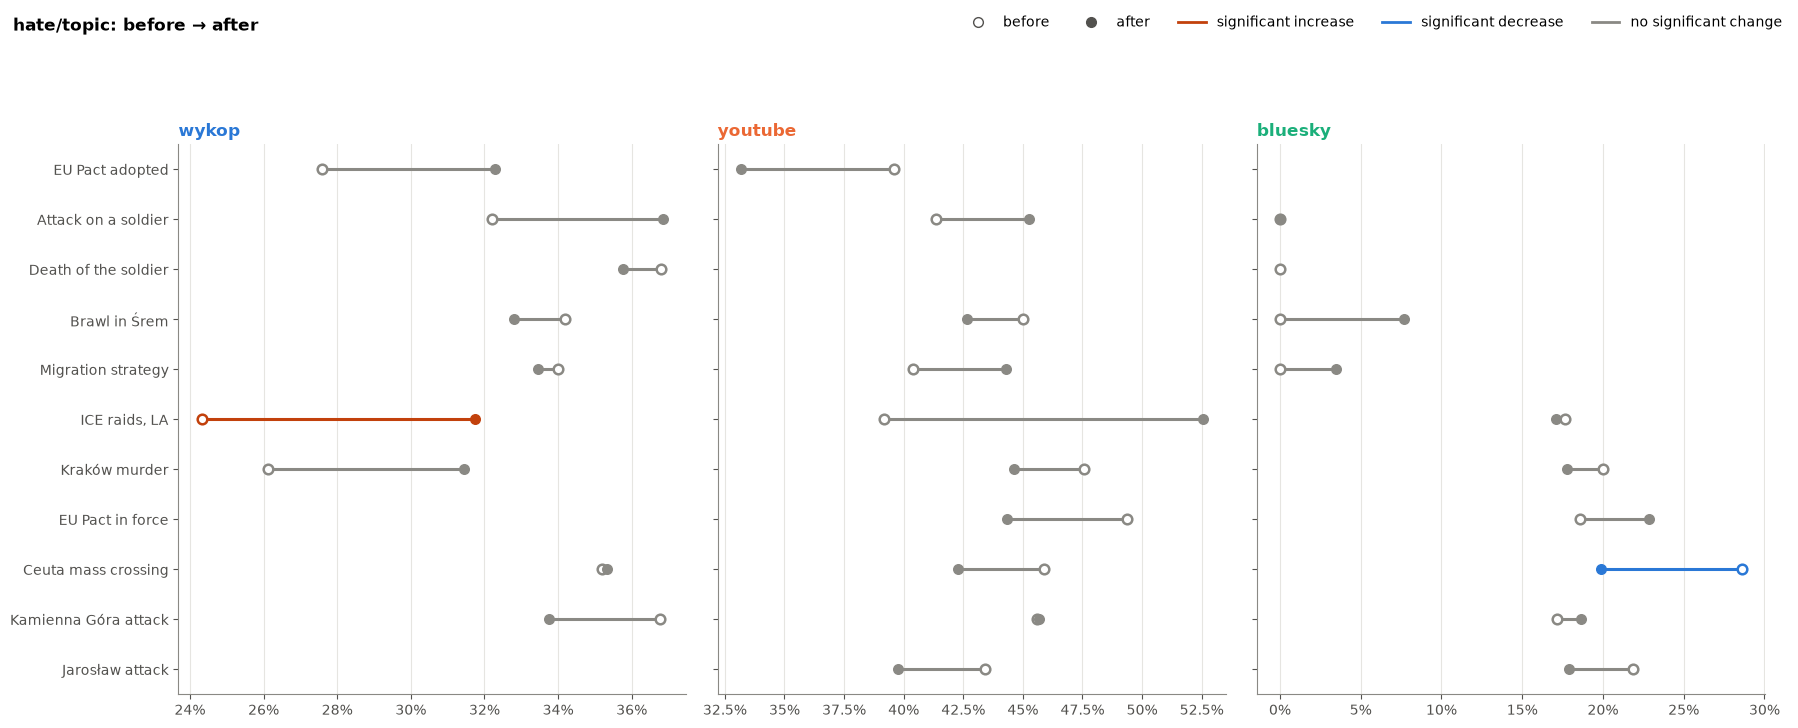

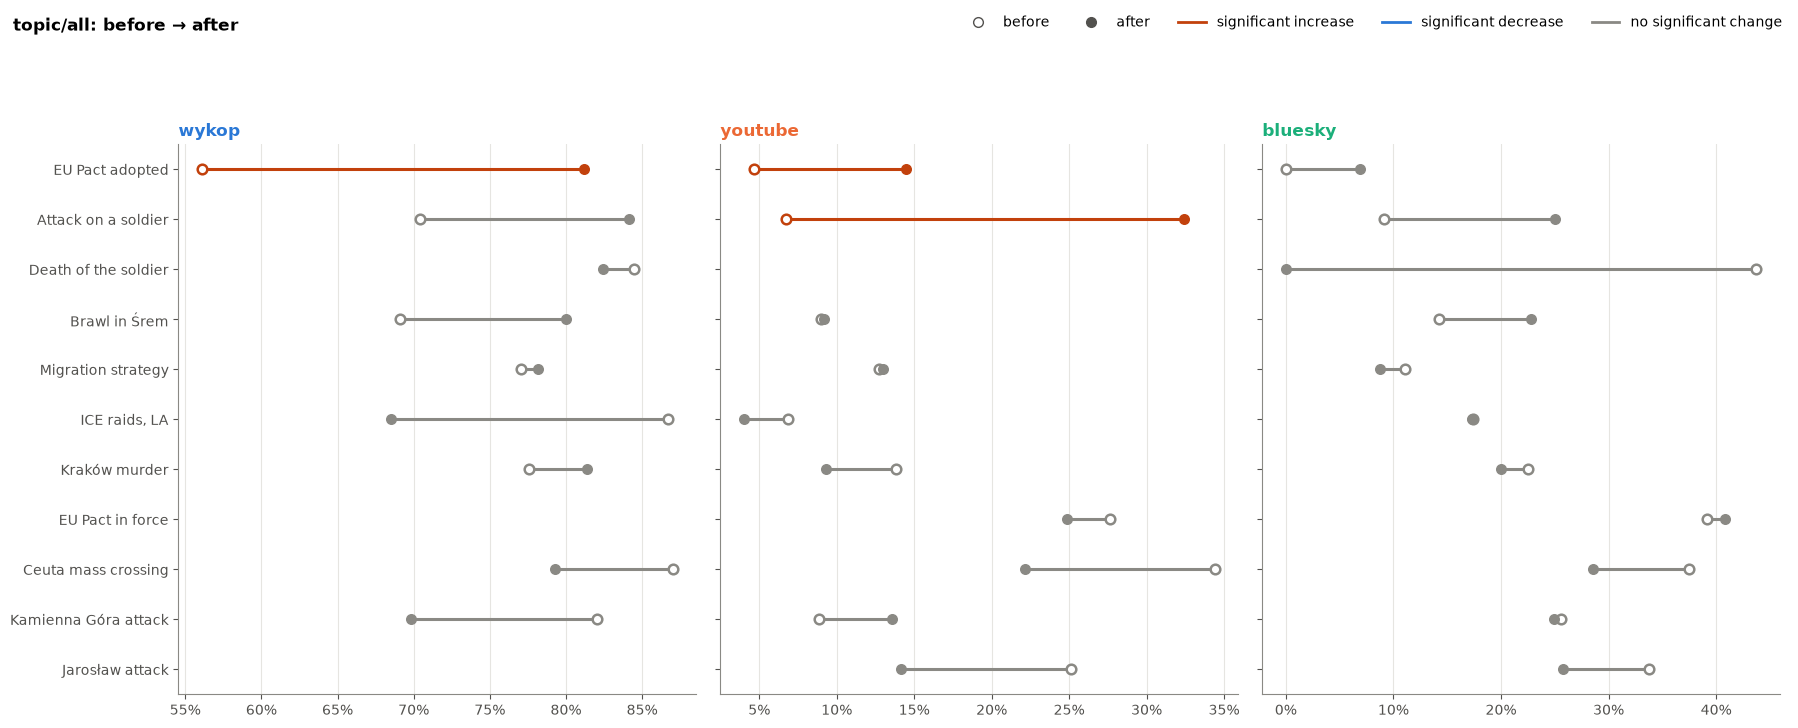

In [7]:
DIR_COLORS = {"↑": "#c2410c", "↓": "#2a78d6", "–": MUTED}
for metric in METRICS:
    fig, axes = plt.subplots(1, len(PL), figsize=(6 * len(PL), 0.5 * len(EVENT_ORDER) + 1.8), sharey=True)
    for ax, p in zip(axes, PL):
        e = E(metric)[E(metric)["platform"] == p].set_index("event").reindex(EVENT_ORDER)
        yy = np.arange(len(EVENT_ORDER))
        for yi, (ev, r) in zip(yy, e.iterrows()):
            if pd.isna(r["before %"]):
                continue
            c = DIR_COLORS[r["direction"]] if isinstance(r["direction"], str) else MUTED
            ax.plot([r["before %"], r["after %"]], [yi, yi], color=c, lw=2.2)
            ax.scatter(r["before %"], yi, s=48, facecolor="white", edgecolor=c, linewidth=1.8, zorder=3)
            ax.scatter(r["after %"], yi, s=48, color=c, zorder=3)
        ax.set_yticks(yy, EVENT_ORDER)
        ax.invert_yaxis()
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}%"))
        ax.grid(axis="x", visible=True)
        ax.grid(axis="y", visible=False)
        ax.set_title(p, color=PLATFORM_COLORS[p])
    fig.suptitle(f"{metric}: before → after", x=0.01, ha="left", fontweight="bold")
    fig.legend([plt.Line2D([], [], marker="o", ls="", ms=7, mfc="white", mec=INK2),
                plt.Line2D([], [], marker="o", ls="", ms=7, color=INK2),
                plt.Line2D([], [], color=DIR_COLORS["↑"]), plt.Line2D([], [], color=DIR_COLORS["↓"]),
                plt.Line2D([], [], color=MUTED)],
               ["before", "after", "significant increase", "significant decrease", "no significant change"],
               loc="upper right", ncol=5, bbox_to_anchor=(1.0, 1.0))
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    plt.show()

**Absolute numbers (daily mean).** Comments and hateful comments per day, before and after.
The bars for an event are **stacked by platform** – the height of the whole bar is the sum over platforms, the colours show
where the comments come from. Shares are not computed from this sum (YouTube dominates the volume).

comments/day before  comments/day after  comments ×  topic/day before  topic/day after  topic ×  hate/day before  hate/day after  hate ×
wykop   EU Pact adopted                     494.0               463.6         0.9             277.1            376.3      1.4             76.4           121.5     1.6
        Attack on a soldier                 408.9               530.2         1.3             287.9            446.0      1.5             92.7           164.4     1.8
        Death of the soldier                427.3               503.5         1.2             361.0            415.0      1.1            132.9           148.5     1.1
        Brawl in Śrem                       486.9               471.0         1.0             336.3            376.7      1.1            115.0           123.6     1.1
        Migration strategy                  461.0               421.6         0.9             355.1            329.5      0.9            120.7           110.3     0.9
        ICE raids, LA                       494.0               418.9         0.8             428.3            286.9      0.7            104.1            91.1     0.9
        Kraków murder                       352.6               339.4         1.0             273.6            276.3      1.0             71.4            86.9     1.2
        Ceuta mass crossing                 511.3               445.8         0.9             444.9            353.3      0.8            156.6           124.9     0.8
        Kamienna Góra attack                417.7               408.9         1.0             342.7            285.7      0.8            126.0            96.4     0.8
youtube EU Pact adopted                    5138.1              3421.9         0.7             240.7            495.9      2.1             95.3           164.5     1.7
        Attack on a soldier                3685.0              4936.5         1.3             247.3           1600.3      6.5            102.3           724.5     7.1
        Brawl in Śrem                      3994.1              5287.5         1.3             357.7            486.9      1.4            161.0           207.8     1.3
        Migration strategy                 3671.3              5927.0         1.6             468.3            769.5      1.6            189.1           340.8     1.8
        ICE raids, LA                      5810.7              4683.6         0.8             398.4            187.8      0.5            156.1            98.7     0.6
        Kraków murder                      2510.4              2457.1         1.0             346.9            228.3      0.7            165.0           101.9     0.6
        EU Pact in force                   2701.3              4507.3         1.7             746.7           1121.6      1.5            368.6           497.1     1.3
        Ceuta mass crossing                2423.0              3131.9         1.3             833.3            693.3      0.8            382.3           293.2     0.8
        Kamienna Góra attack               2119.0              6069.9         2.9             188.0            824.7      4.4             85.7           376.7     4.4
        Jarosław attack                    4869.1              6595.0         1.4            1224.0            932.4      0.8            531.1           370.9     0.7
bluesky EU Pact adopted                       2.3                 3.9         1.7               0.0              0.3      inf              0.0             0.0     NaN
        Attack on a soldier                   1.6                 1.9         1.2               0.1              0.5      3.3              0.0             0.0     NaN
        Death of the soldier                  2.3                 2.1         0.9               1.0              0.0      0.0              0.0             0.0     NaN
        Brawl in Śrem                         1.0                 3.8         3.8               0.1              0.9      6.1              0.0             0.1     inf
        Migration stra

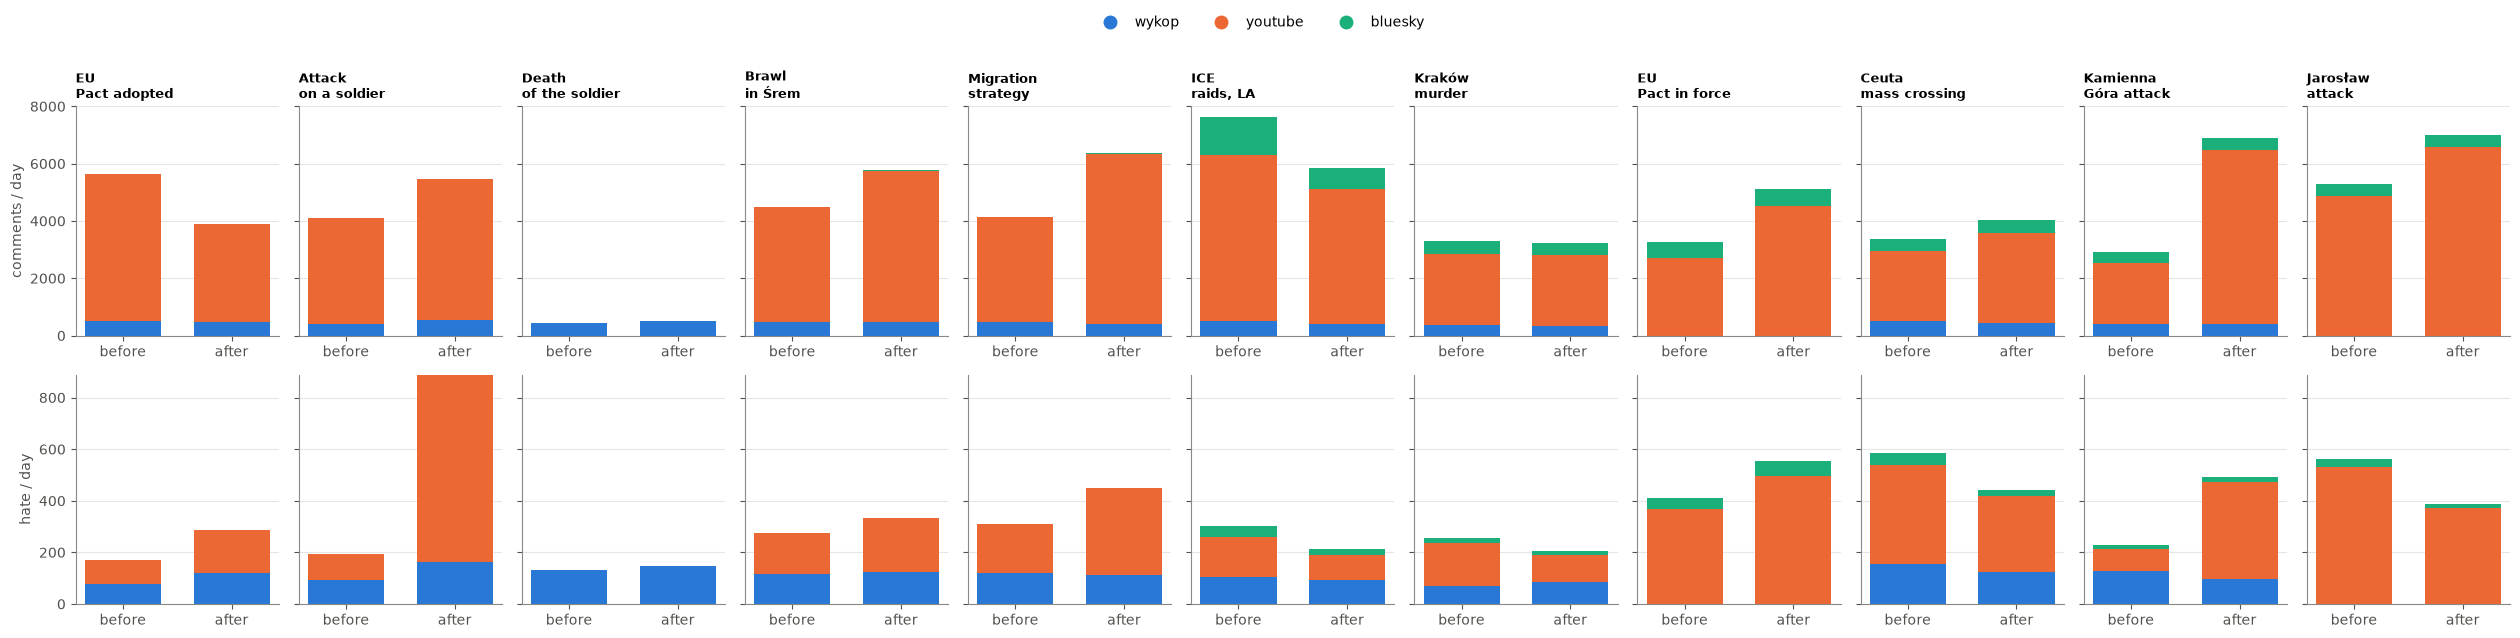

In [8]:
act = (df.groupby(["platform", "event", "period"], sort=False)
       .agg(comments=("comment_id", "size"), hate=("hate", "sum"), topic=("topic", "sum")))
days = pd.Series({"before": DAYS_PRE, "after": DAYS_POST})
per_day = act.div(act.index.get_level_values("period").map(days).values, axis=0).unstack("period")
counts_tab = pd.DataFrame(index=per_day.index)
for c in ["comments", "topic", "hate"]:
    counts_tab[f"{c}/day before"] = per_day[(c, "before")]
    counts_tab[f"{c}/day after"] = per_day[(c, "after")]
    counts_tab[f"{c} ×"] = per_day[(c, "after")] / per_day[(c, "before")]
counts_tab = counts_tab.reindex(pd.MultiIndex.from_tuples([tuple(c.split(":")) for c in CELLS]))
display(counts_tab.round(1))

fig, axes = plt.subplots(2, len(EVENT_ORDER), figsize=(2.3 * len(EVENT_ORDER), 6.4), sharey="row")
for j, ev in enumerate(EVENT_ORDER):
    for i, (c, lab) in enumerate([("comments", "comments / day"), ("hate", "hate / day")]):
        ax = axes[i, j]
        bottom = np.zeros(2)
        for p in PL:
            if (p, ev) not in counts_tab.index:
                continue
            v = counts_tab.loc[(p, ev), [f"{c}/day before", f"{c}/day after"]].values.astype(float)
            ax.bar([0, 1], v, bottom=bottom, color=PLATFORM_COLORS[p], width=0.7)
            bottom += v
        ax.set_xticks([0, 1], ["before", "after"])
        if j == 0:
            ax.set_ylabel(lab)
        if i == 0:
            ax.set_title(ev.replace(" ", "\n", 1), fontsize=9)
platform_legend(fig, top=0.92)
plt.show()

The bottom row is the mean daily number of hateful comments before and after the event, and the top row is the mean daily number of all comments.

### 1b. Events pooled across all platforms

For each event we combine the platform effects with a **fixed-effect meta-analysis** (with 2–3 platforms the random-effects model
is unstable). Diamond = pooled OR of the event, dots = individual platforms.
`p Q` tells whether the platforms reacted differently to that event.


=== hate/topic ===


,type,platforms,k,OR,OR lo,OR hi,p,I²,p Q,p (Holm)
event,,,,,,,,,,
EU Pact adopted,political,"wykop, youtube",2,1.17,0.96,1.43,0.12,0.65,0.0906,0.84
Attack on a soldier,criminal,"wykop, youtube",2,1.22,1.02,1.46,0.0297,0.00,0.857,0.297
Death of the soldier,criminal,wykop,1,0.96,0.83,1.11,0.554,NaN,,1
Brawl in Śrem,criminal,"wykop, youtube",2,0.93,0.78,1.11,0.45,0.00,0.891,1
Migration strategy,political,"wykop, youtube",2,1.04,0.89,1.22,0.585,0.17,0.273,1
"ICE raids, LA",political,"wykop, youtube, bluesky",3,1.30,1.15,1.48,4.85e-05,0.81,0.00521,0.000534
Kraków murder,disinformation,"wykop, youtube, bluesky",3,1.07,0.92,1.25,0.376,0.68,0.0431,1
EU Pact in force,political,"youtube, bluesky",2,1.13,0.94,1.36,0.19,0.81,0.0225,1
Ceuta mass crossing,border crisis,"wykop, youtube, bluesky",3,0.89,0.80,0.99,0.0364,0.79,0.00938,0.328



=== topic/all ===


,type,platforms,k,OR,OR lo,OR hi,p,I²,p Q,p (Holm)
event,,,,,,,,,,
EU Pact adopted,political,"wykop, youtube",2,3.41,2.02,5.76,4.75e-06,0.00,0.967,5.23e-05
Attack on a soldier,criminal,"wykop, youtube",2,3.86,2.08,7.16,1.88e-05,0.67,0.0822,0.000188
Death of the soldier,criminal,wykop,1,0.86,0.33,2.25,0.761,NaN,,1
Brawl in Śrem,criminal,"wykop, youtube",2,1.36,0.84,2.22,0.213,0.18,0.27,1
Migration strategy,political,"wykop, youtube",2,1.04,0.60,1.79,0.892,0.00,0.939,1
"ICE raids, LA",political,"wykop, youtube, bluesky",3,0.90,0.73,1.12,0.351,0.73,0.0255,1
Kraków murder,disinformation,"wykop, youtube, bluesky",3,0.88,0.67,1.17,0.395,0.00,0.459,1
EU Pact in force,political,"youtube, bluesky",2,1.04,0.79,1.36,0.795,0.00,0.587,1
Ceuta mass crossing,border crisis,"wykop, youtube, bluesky",3,0.64,0.49,0.84,0.0011,0.00,0.872,0.00986


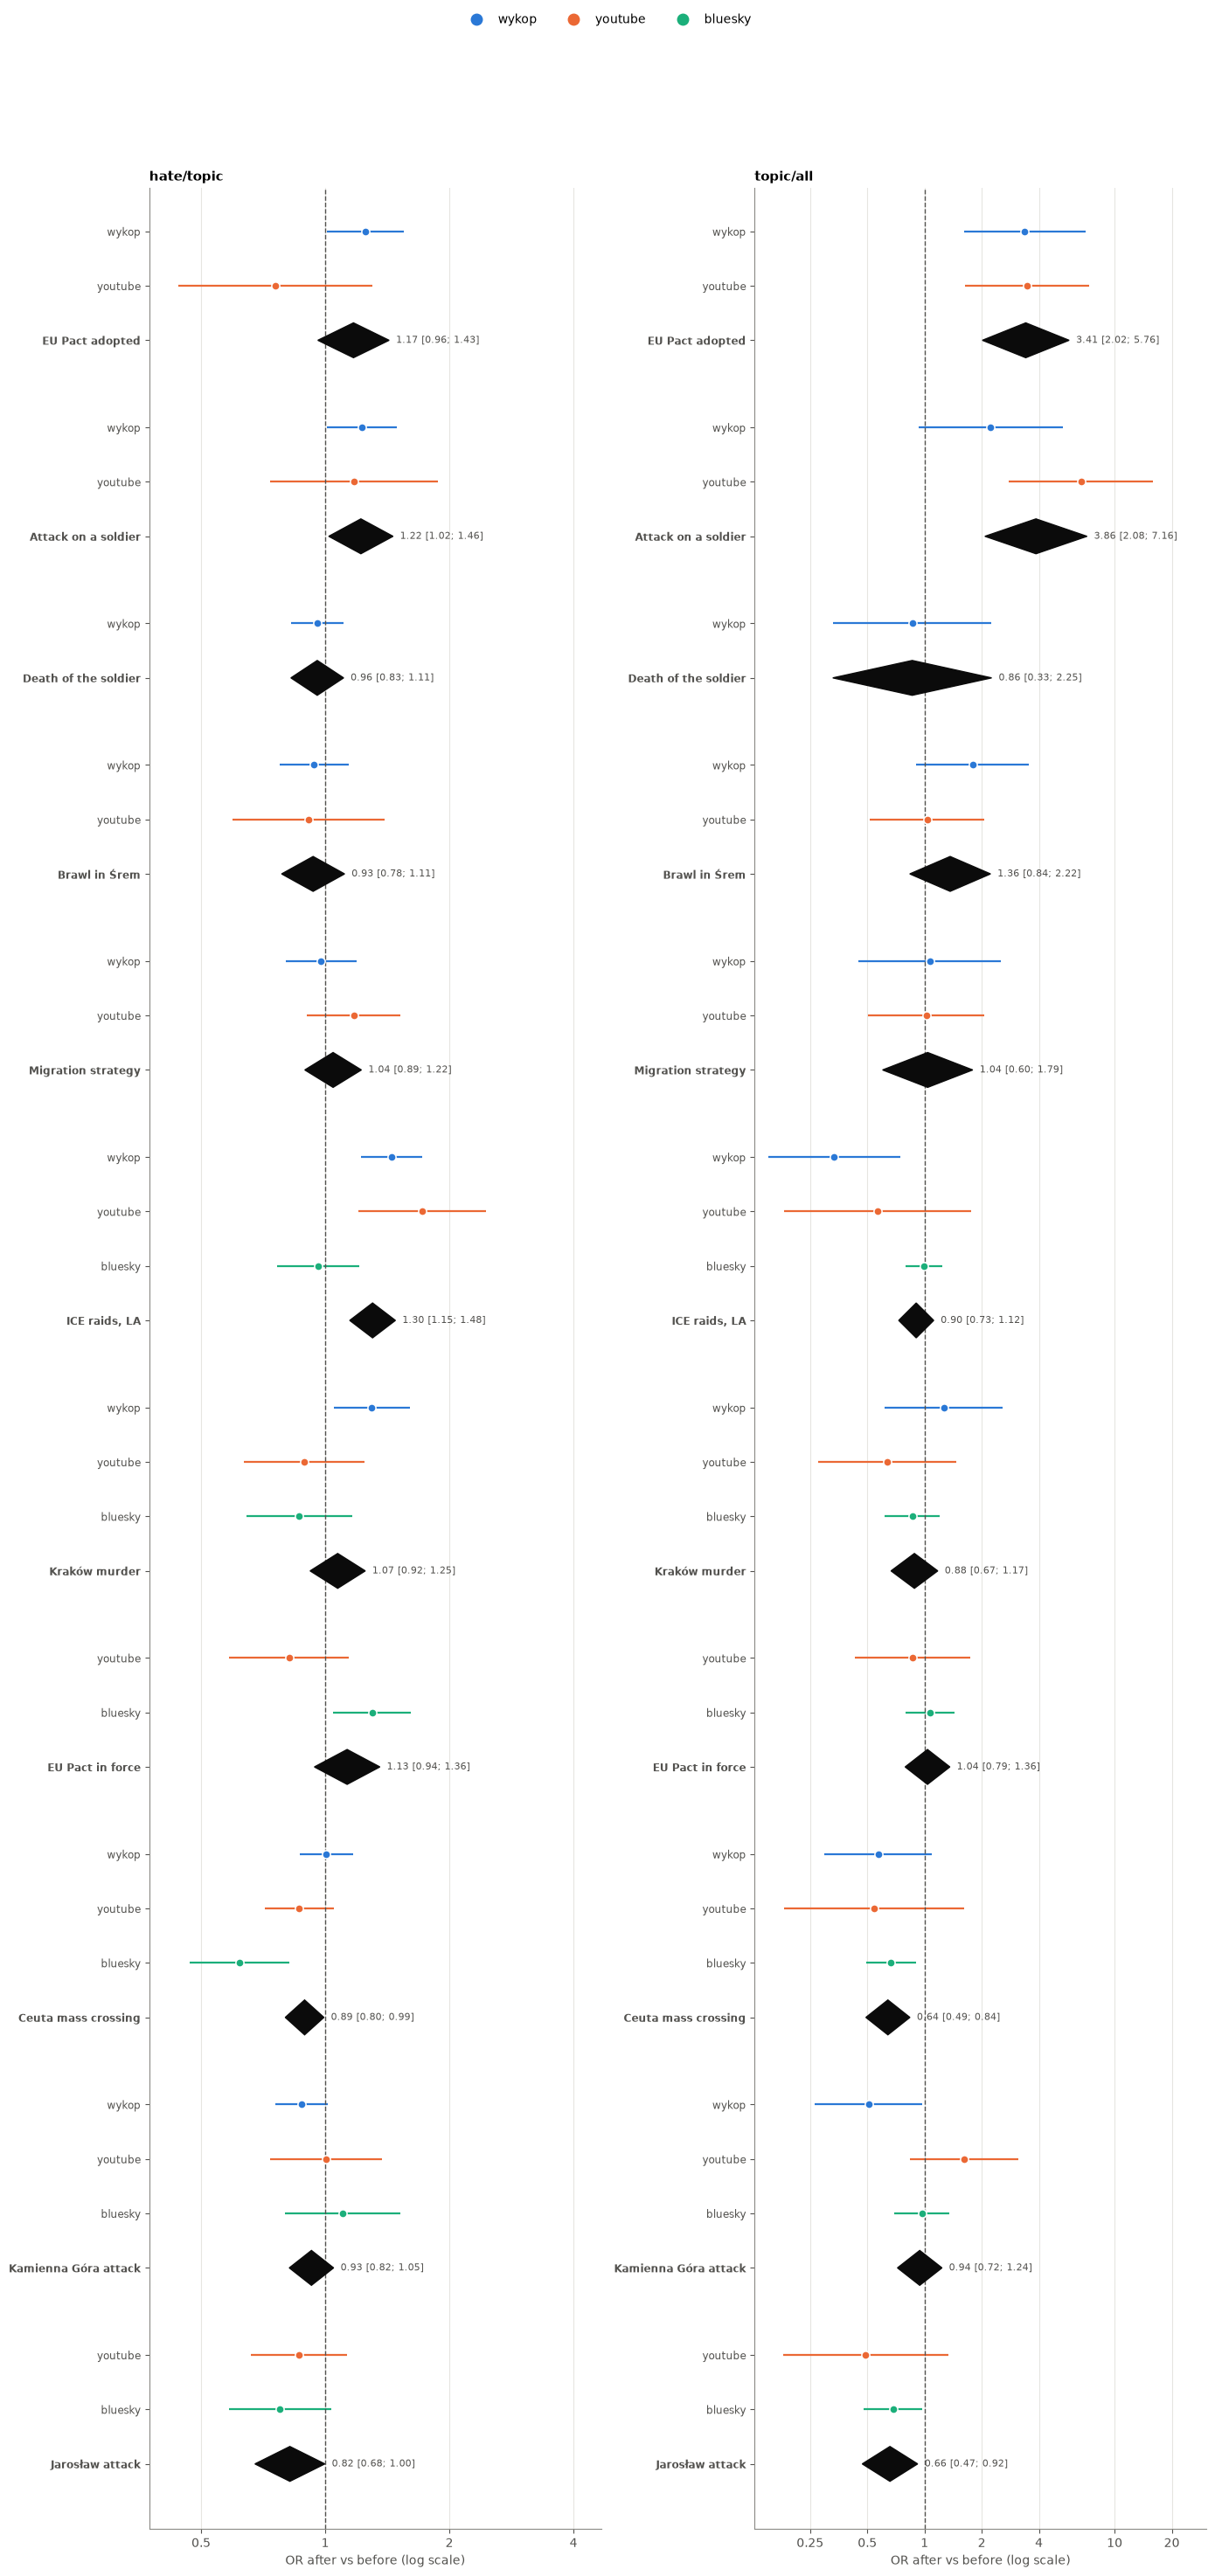

In [9]:
ev_rows = []
for metric in METRICS:
    for ev in EVENT_ORDER:
        e = E(metric)[E(metric)["event"] == ev].dropna(subset=["log OR"])
        m = meta_fixed(e["log OR"], e["se"])
        ev_rows.append({"metric": metric, "event": ev, "type": EVENT_META[ev][0], "platforms": ", ".join(e["platform"]),
                        "k": m["k"], **or_row(m), "I²": m["I2"], "p Q": m["p Q"],
                        "mu": m["mu"], "se_mu": m["se"]})
ev_pool = pd.DataFrame(ev_rows)
ev_pool["p (Holm)"] = ev_pool.groupby("metric")["p"].transform(holm)
for metric in METRICS:
    print(f"\n=== {metric} ===")
    display(fmt_p(ev_pool[ev_pool["metric"] == metric].drop(columns=["metric", "mu", "se_mu"]).set_index("event"), 2))

fig, axes = plt.subplots(1, len(METRICS), figsize=(7 * len(METRICS), 0.62 * len(CELLS) + 0.9 * len(EVENT_ORDER) + 1))
for ax, metric in zip(axes, METRICS):
    groups = []
    for ev in EVENT_ORDER:
        e = E(metric)[E(metric)["event"] == ev].dropna(subset=["log OR"])
        r = ev_pool[(ev_pool["metric"] == metric) & (ev_pool["event"] == ev)].iloc[0]
        groups.append({"label": f"{ev}", "items": items_from(e.assign(lab="   " + e["platform"]), "lab",
                                                             lambda r_: PLATFORM_COLORS[r_["platform"]]),
                       "diamond": {"OR": r["OR"], "lo": r["OR lo"], "hi": r["OR hi"], "color": INK}})
    forest(ax, groups, title=metric)
platform_legend(fig, top=0.94)
plt.show()

How to read it:

- The centre of the diamond (its widest point vertically) is the pooled OR of the event; its value is printed next to it.
- The left and right vertices are the limits of the 95% confidence interval.
- The dashed line at 1 means no change. If the whole diamond lies on one side of this line, the change is significant;
  a diamond that crosses 1 means no significant change.

### 1c. Before / after pooled across events, separately per platform (→ H4)

For each platform we combine its events with a **random-effects meta-analysis** (DerSimonian–Laird + Hartung–Knapp).
I² and `p Q` tell whether events act similarly on that platform.

In [10]:
plat_rows = []
for metric in METRICS:
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        m = meta_random(e["log OR"], e["se"])
        plat_rows.append({"metric": metric, "platform": p, "events": m["k"],
                          "increase in": f"{int((e['log OR'] > 0).sum())}/{len(e)}",
                          "significant ↑ / ↓": f"{int((e['direction'] == '↑').sum())} / {int((e['direction'] == '↓').sum())}",
                          "mean change pp": e["diff pp"].mean(), **or_row(m), "I²": m["I2"], "p Q": m["p Q"],
                          "mu": m["mu"], "se_mu": m["se"]})
plat = pd.DataFrame(plat_rows)
display(fmt_p(plat.drop(columns=["mu", "se_mu"]).set_index(["metric", "platform"]), 2))

# daily levels before/after (mean over the platform's events) – within a platform only
lvl = (counts_tab.groupby(level=0).mean()
       [["comments/day before", "comments/day after", "hate/day before", "hate/day after"]]
       .reindex(PL))
print("Daily mean per event (mean over the platform's events):")
display(lvl.round(1))

events increase in significant ↑ / ↓  mean change pp    OR  OR lo  OR hi      p    I²       p Q
metric     platform                                                                                                 
hate/topic wykop          9         5/9             1 / 0            1.81  1.09   0.95   1.25  0.202  0.75  0.000109
           youtube       10        4/10             0 / 0           -0.27  0.99   0.84   1.16  0.852  0.47    0.0507
           bluesky        6         2/6             0 / 1           -1.63  0.92   0.69   1.22  0.471  0.75   0.00116
topic/all  wykop          9         5/9             1 / 0            1.60  1.04   0.58   1.87  0.879  0.74  0.000126
           youtube       10        5/10             2 / 0            0.73  1.17   0.64   2.14  0.576  0.73  0.000119
           bluesky        6         1/6             0 / 0           -3.07  0.87   0.71   1.08  0.157  0.40     0.137

Daily mean per event (mean over the platform's events):


,comments/day before,comments/day after,hate/day before,hate/day after
wykop,450.4,444.8,110.7,118.6
youtube,3692.2,4701.8,223.7,317.6
bluesky,325.6,279.2,17.9,14.3


### 1d. Before / after pooled across events and platforms (→ H1)

**Main test of H1:** random-effects meta-analysis of **all cells** (H0: pooled log-OR = 0).
**Confirmation:** one model `y ~ post + C(cell)` on all comments with standard errors clustered by thread
(a before / after comparison *within* a cell, but large cells – YouTube – have more weight).

In [11]:
all_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])
    m = meta_random(e["log OR"], e["se"])
    d, col = subset(df, metric)
    mod = logit_cluster(d, col, "y ~ post + C(cell)")
    b, s = mod.params["post"], mod.bse["post"]
    sign = stats.binomtest(int((e["log OR"] > 0).sum()), len(e), 0.5)
    all_rows.append({"metric": metric, "cells": m["k"],
                     "significant ↑ / ↓ / –": f"{int((e['direction'] == '↑').sum())} / {int((e['direction'] == '↓').sum())} / "
                                           f"{int((e['direction'] == '–').sum())}",
                     "OR meta": np.exp(m["mu"]), "OR lo": np.exp(m["lo"]), "OR hi": np.exp(m["hi"]), "p meta": m["p"],
                     "I²": m["I2"], "τ²": m["tau2"],
                     "increase in": f"{int((e['log OR'] > 0).sum())}/{len(e)}", "p sign test": sign.pvalue,
                     "OR model": np.exp(b), "OR model lo": np.exp(b - 1.96 * s), "OR model hi": np.exp(b + 1.96 * s),
                     "p model": mod.pvalues["post"], "mu": m["mu"], "se_mu": m["se"]})
pooled = pd.DataFrame(all_rows).set_index("metric")
display(fmt_p(pooled.drop(columns=["mu", "se_mu"]), 3))

C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,cells,significant ↑ / ↓ / –,OR meta,OR lo,OR hi,p meta,I²,τ²,increase in,p sign test,OR model,OR model lo,OR model hi,p model
metric,,,,,,,,,,,,,,
hate/topic,25,1 / 1 / 23,1.014,0.926,1.110,0.752,0.676,0.028,11/25,0.69,0.985,0.918,1.057,0.675
topic/all,25,3 / 0 / 22,1.016,0.781,1.323,0.901,0.695,0.157,11/25,0.69,1.061,0.793,1.418,0.691


**H1 forest plot:** all cells (colour = platform) grouped by platform, with a diamond for each platform
and a pooled diamond for all cells at the bottom (black).

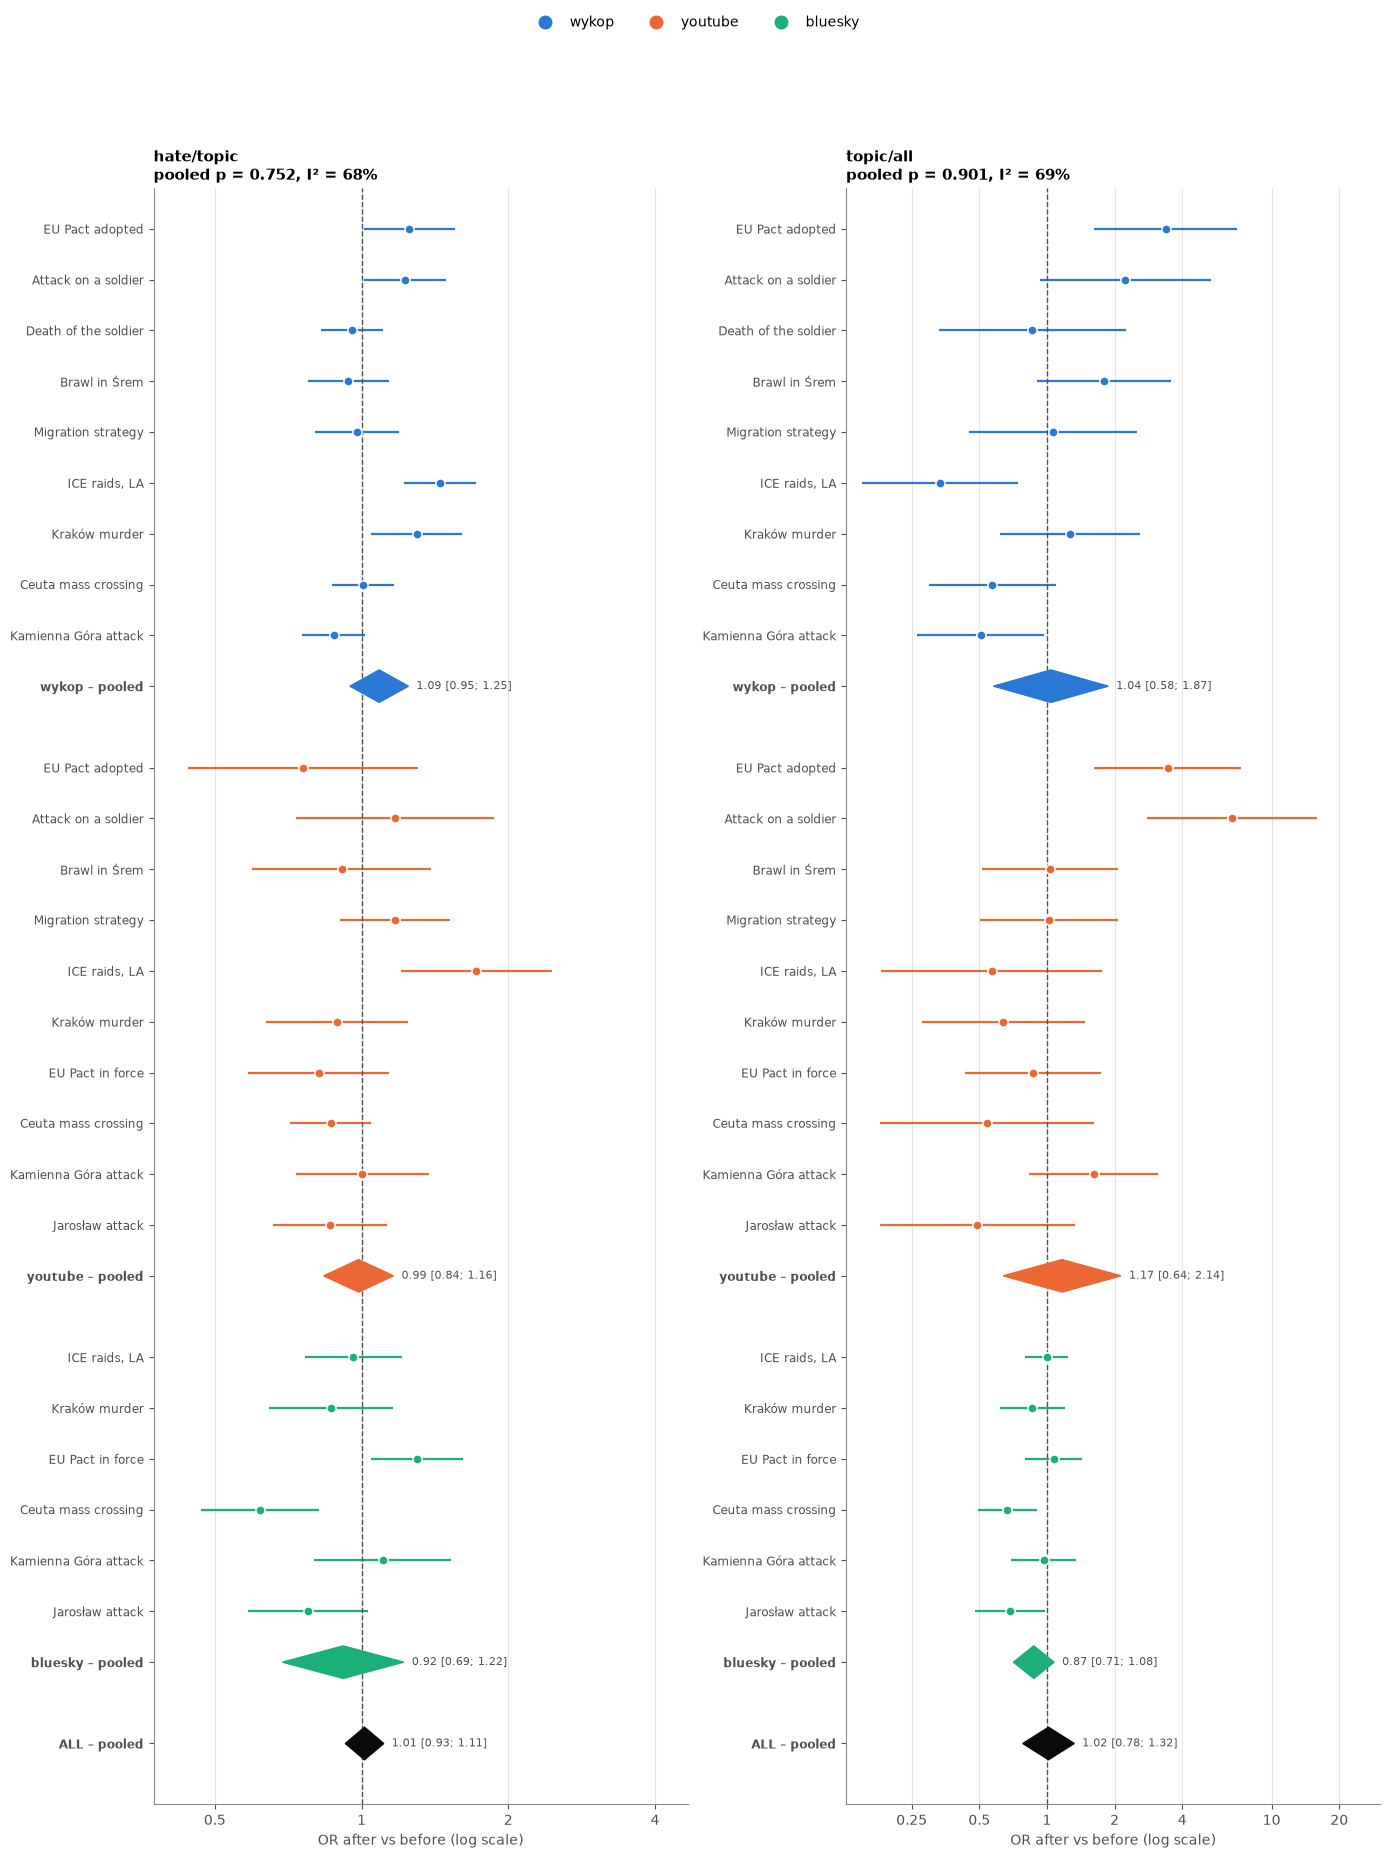

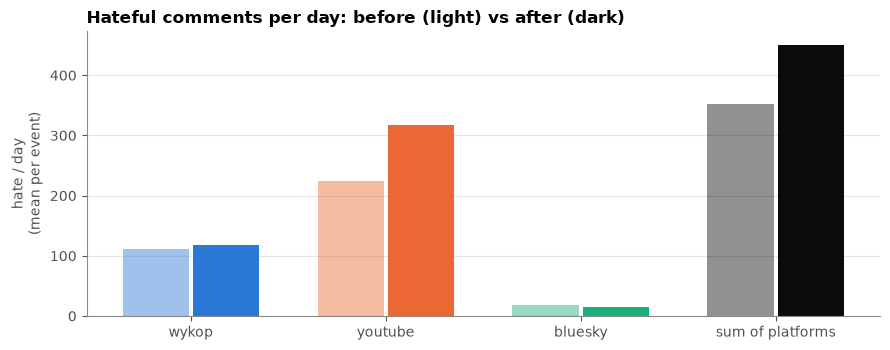

In [12]:
def platform_groups(metric, cells_filter=None):
    groups = []
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        if cells_filter is not None:
            e = e[e["event"].isin(cells_filter)]
        m = meta_random(e["log OR"], e["se"])
        groups.append({"label": f"{p} – pooled", "items": items_from(e, "event", lambda r_: PLATFORM_COLORS[r_["platform"]]),
                       "diamond": dia(m, PLATFORM_COLORS[p])})
    return groups


fig, axes = plt.subplots(1, len(METRICS), figsize=(7 * len(METRICS), 0.5 * len(CELLS) + 3.6))
for ax, metric in zip(axes, METRICS):
    r = pooled.loc[metric]
    groups = platform_groups(metric)
    groups.append({"label": "ALL – pooled", "items": [],
                   "diamond": {"OR": r["OR meta"], "lo": r["OR lo"], "hi": r["OR hi"], "color": INK}})
    forest(ax, groups, title=f"{metric}\npooled p = {r['p meta']:.3g}, I² = {r['I²']:.0%}")
platform_legend(fig, top=0.93)
plt.show()

fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(PL) + 1)
ax.bar(x[:-1] - 0.18, lvl["hate/day before"], width=0.34, color=[PLATFORM_COLORS[p] for p in PL], alpha=0.45, label="before")
ax.bar(x[:-1] + 0.18, lvl["hate/day after"], width=0.34, color=[PLATFORM_COLORS[p] for p in PL], label="after")
tot = lvl[["hate/day before", "hate/day after"]].sum()
ax.bar(x[-1] - 0.18, tot.iloc[0], width=0.34, color=INK, alpha=0.45)
ax.bar(x[-1] + 0.18, tot.iloc[1], width=0.34, color=INK)
ax.set_xticks(x, [*PL, "sum of platforms"])
ax.set_ylabel("hate / day\n(mean per event)")
ax.set_title("Hateful comments per day: before (light) vs after (dark)")
plt.tight_layout()
plt.show()

The platform bars are the mean daily number of hateful comments averaged over the events of a platform. For each event we compute hate per day (before: count / 7, after: count / 15) and then take the mean across events.

### Overall conclusion: do events raise hate?

All events and platforms together. The cell below collects the results from 1d (meta-analysis and comment-level model)
and the absolute numbers from 1a, and prints a verdict for each metric.

**How to read the chart:** one panel per metric.
- **dots** – OR "after vs before" of individual cells (colour = platform) – they show how different the events are,
- **diamond** – pooled OR from the random-effects meta-analysis (width = 95% CI) – the main test,
- **square** – OR from one model on all comments (large YouTube cells weigh more here) – confirmation.

A diamond / square crossing the dashed line at 1 = no systematic change.

,verdict,cells,OR meta,OR lo,OR hi,p meta,I²,increase in,significant ↑ / ↓ / –,OR model,OR model lo,OR model hi,p model
metric,,,,,,,,,,,,,
hate/topic,NO systematic change,25,1.014,0.926,1.110,0.752,0.676,11/25,1 / 1 / 23,0.985,0.918,1.057,0.675
topic/all,NO systematic change,25,1.016,0.781,1.323,0.901,0.695,11/25,3 / 0 / 22,1.061,0.793,1.418,0.691


hate/topic (hate (HerBERT) / comments on the migration topic): NO systematic change
    pooled OR = 1.01 [0.93; 1.11], p = 0.752; increase in 11/25 cells; I² = 68% (variation between events)
    comment-level model: OR = 0.99 [0.92; 1.06], p = 0.675
topic/all (comments on the migration topic / all comments): NO systematic change
    pooled OR = 1.02 [0.78; 1.32], p = 0.901; increase in 11/25 cells; I² = 69% (variation between events)
    comment-level model: OR = 1.06 [0.79; 1.42], p = 0.691

Absolute numbers (sum of 30 cells, per day): comments 44,558 → 54,091 (×1.21), hate 3,429 → 4,401 (×1.28)


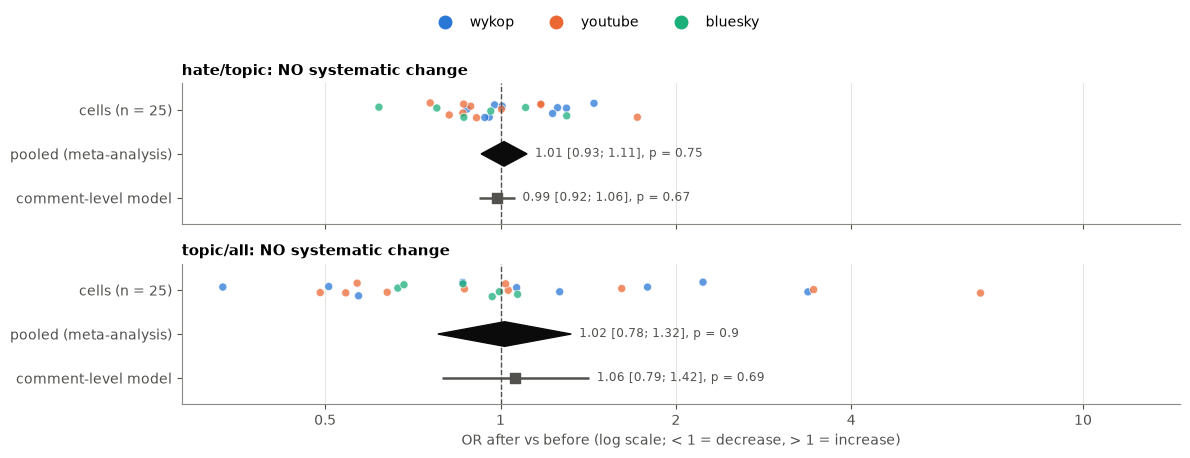

In [13]:
def overall_verdict(r):
    if r["p meta"] >= ALPHA:
        return "NO systematic change"
    return "significant INCREASE" if r["OR meta"] > 1 else "significant DECREASE"


overall = pooled[["cells", "OR meta", "OR lo", "OR hi", "p meta", "I²", "increase in", "significant ↑ / ↓ / –",
                  "OR model", "OR model lo", "OR model hi", "p model"]].copy()
overall.insert(0, "verdict", [overall_verdict(r) for _, r in pooled.iterrows()])
display(fmt_p(overall, 3))

for metric, r in pooled.iterrows():
    model = (f"comment-level model: OR = {r['OR model']:.2f} [{r['OR model lo']:.2f}; {r['OR model hi']:.2f}], "
             f"p = {r['p model']:.3g}" + (" – significant" if r["p model"] < ALPHA else ""))
    print(f"{metric} ({METRIC_NAMES[metric]}): {overall_verdict(r)}\n"
          f"    pooled OR = {r['OR meta']:.2f} [{r['OR lo']:.2f}; {r['OR hi']:.2f}], p = {r['p meta']:.3g}; "
          f"increase in {r['increase in']} cells; I² = {r['I²']:.0%} (variation between events)\n    {model}")

# absolute numbers: sum over all cells, mean per day
tot = counts_tab.sum()
print(f"\nAbsolute numbers (sum of {len(counts_tab)} cells, per day): "
      f"comments {tot['comments/day before']:,.0f} → {tot['comments/day after']:,.0f} "
      f"(×{tot['comments/day after'] / tot['comments/day before']:.2f}), "
      f"hate {tot['hate/day before']:,.0f} → {tot['hate/day after']:,.0f} "
      f"(×{tot['hate/day after'] / tot['hate/day before']:.2f})")

fig, axes = plt.subplots(len(METRICS), 1, figsize=(12, 1.7 * len(METRICS) + 1.2), sharex=True)
rng = np.random.default_rng(0)
xs = []
for ax, metric in zip(axes, METRICS):
    e, r = E(metric).dropna(subset=["OR"]), pooled.loc[metric]
    ax.scatter(e["OR"], 2 + rng.uniform(-0.18, 0.18, len(e)), s=34, color=e["platform"].map(PLATFORM_COLORS).tolist(),
               alpha=0.75, edgecolor="white", linewidth=0.6, zorder=2)
    ax.fill([r["OR lo"], r["OR meta"], r["OR hi"], r["OR meta"]], [1, 1.28, 1, 0.72], color=INK, zorder=3)
    ax.hlines(0, r["OR model lo"], r["OR model hi"], color=INK2, lw=1.8)
    ax.scatter(r["OR model"], 0, marker="s", s=42, color=INK2, zorder=3)
    for y, o, lo, hi, p in [(1, r["OR meta"], r["OR lo"], r["OR hi"], r["p meta"]),
                            (0, r["OR model"], r["OR model lo"], r["OR model hi"], r["p model"])]:
        ax.text(hi, y, f"  {o:.2f} [{lo:.2f}; {hi:.2f}], p = {p:.2g}", va="center", fontsize=8.5, color=INK2)
    ax.axvline(1, color=INK2, ls="--", lw=1)
    ax.set_yticks([2, 1, 0], [f"cells (n = {len(e)})", "pooled (meta-analysis)", "comment-level model"])
    ax.set_ylim(-0.6, 2.6)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_title(f"{metric}: {overall_verdict(r)}", fontsize=10.5)
    xs += [*e["OR"], r["OR lo"], r["OR hi"], r["OR model lo"], r["OR model hi"]]
axes[-1].set_xscale("log")
axes[-1].set_xlim(min(xs) * 0.85, max(xs) * 2.2)
log_ticks(axes[-1], "x")
axes[-1].set_xlabel("OR after vs before (log scale; < 1 = decrease, > 1 = increase)")
platform_legend(fig, top=0.9)
plt.show()

### 1f. Test of H4: does the effect of events differ between platforms?

- **Main test:** subgroup difference in the meta-analysis – do the pooled platform effects (1c) differ more than expected by
  chance (Q statistic between platforms).
- **Interaction model:** `y ~ post + post:C(platform) + C(cell)`, Wald test of all `post:platform` interactions.
- **Platform pairs:** ratio of ORs (ROR = OR A / OR B) from the pooled platform effects, Holm correction for pairs.
  ROR > 1 = after events the share on platform A moves more "upwards" than on B (not: "there is more hate on A").
- **Balanced panel (3 platforms):** Q test and Wald test only on events common to **all** platforms
  (`COMMON_EVENTS`, printed when the data are loaded) – the difference does not come from different sets of events.
- **Events shared by a pair:** each pair of platforms is compared on the events that **both** platforms of the pair have.

We compare the **size of the change**, not the levels.

In [14]:
def wald(d, col, formula, keep):
    """Wald test for coefficients whose names satisfy keep(name); logit clustered by thread."""
    m = logit_cluster(d, col, formula)
    idx = [i for i, n in enumerate(m.params.index) if keep(n)]
    return float(m.wald_test(np.eye(len(m.params))[idx], scalar=True).pvalue), m


def pair_events(a, b):
    # events with a cell on both platforms of the pair
    return [e for e in EVENT_ORDER if f"{a}:{e}" in CELLS and f"{b}:{e}" in CELLS]


def platform_meta(metric, events=None):
    out = {}
    for p in PL:
        e = E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"])
        if events is not None:
            e = e[e["event"].isin(events)]
        out[p] = meta_random(e["log OR"], e["se"])
    return out


h4_rows, ror_rows = [], []
for metric in METRICS:
    pm = platform_meta(metric)
    q, pq = q_test([pm[p]["mu"] for p in PL], [pm[p]["se"] for p in PL])
    pmb = platform_meta(metric, COMMON_EVENTS)
    qb, pqb = q_test([pmb[p]["mu"] for p in PL], [pmb[p]["se"] for p in PL])
    d, col = subset(df, metric)
    pw, mw = wald(d, col, "y ~ post + post:C(platform) + C(cell)", lambda n: n.startswith("post:C(platform)"))
    pwb, _ = wald(d[d["event"].isin(COMMON_EVENTS)], col, "y ~ post + post:C(platform) + C(cell)",
                  lambda n: n.startswith("post:C(platform)"))
    h4_rows.append({"metric": metric, "Q between platforms": q, "p Q (all cells)": pq,
                    "p Q (balanced panel)": pqb, "p Wald after×platform": pw, "p Wald (balanced)": pwb,
                    **{f"OR {p}": np.exp(pm[p]["mu"]) for p in PL},
                    **{f"OR {p} (panel)": np.exp(pmb[p]["mu"]) for p in PL}})
    for a, b in combinations(PL, 2):
        pe = pair_events(a, b)
        pmp = platform_meta(metric, pe)
        for scope, mm in [("all cells", pm), ("events shared by the pair", pmp)]:
            dlt, s = mm[a]["mu"] - mm[b]["mu"], np.hypot(mm[a]["se"], mm[b]["se"])
            ror_rows.append({"metric": metric, "scope": scope, "pair": f"{a} / {b}",
                             "events": f"{mm[a]['k']} / {mm[b]['k']}", "ROR": np.exp(dlt),
                             "ROR lo": np.exp(dlt - 1.96 * s), "ROR hi": np.exp(dlt + 1.96 * s),
                             "p": 2 * stats.norm.sf(abs(dlt / s))})
h4 = pd.DataFrame(h4_rows).set_index("metric")
ror = pd.DataFrame(ror_rows)
ror["p (Holm)"] = ror.groupby(["metric", "scope"])["p"].transform(holm)
print("H4 test:")
display(fmt_p(h4, 3))
print("Platform pairs (ROR > 1 = stronger relative change on the first platform):")
display(fmt_p(ror.set_index(["metric", "scope", "pair"]), 3))

C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


H4 test:


,Q between platforms,p Q (all cells),p Q (balanced panel),p Wald after×platform,p Wald (balanced),OR wykop,OR youtube,OR bluesky,OR wykop (panel),OR youtube (panel),OR bluesky (panel)
metric,,,,,,,,,,,
hate/topic,2.240,0.326,0.21,0.0221,0.00299,1.087,0.986,0.917,1.107,1.033,0.866
topic/all,1.401,0.496,0.367,0.233,0.0521,1.041,1.167,0.873,1.063,1.337,0.872


Platform pairs (ROR > 1 = stronger relative change on the first platform):


events    ROR  ROR lo  ROR hi       p p (Holm)
metric     scope                     pair                                                             
hate/topic all cells                 wykop / youtube    9 / 10  1.102   0.916   1.326   0.303    0.605
           events shared by the pair wykop / youtube     8 / 8  1.071   0.864   1.328   0.532        1
           all cells                 wykop / bluesky     9 / 6  1.186   0.925   1.520   0.179    0.536
           events shared by the pair wykop / bluesky     9 / 4  1.255   0.961   1.640  0.0949    0.285
           all cells                 youtube / bluesky  10 / 6  1.076   0.828   1.397   0.584    0.605
           events shared by the pair youtube / bluesky  10 / 6  1.076   0.828   1.397   0.584        1
topic/all  all cells                 wykop / youtube    9 / 10  0.892   0.432   1.838   0.756        1
           events shared by the pair wykop / youtube     8 / 8  0.795   0.348   1.817   0.587        1
           all cells                 wykop / bluesky     9 / 6  1.192   0.705   2.014   0.512        1
           events shared by the pair wykop / bluesky     9 / 4  1.193   0.701   2.032   0.515        1
           all cells                 youtube / bluesky  10 / 6  1.337   0.773   2.310   0.299    0.896
           events shared by the pair youtube / bluesky  10 / 6  1.337   0.773   2.310   0.299    0.896

**H4 charts:** (left) interaction chart – before → after index for each platform (before = 1, after = pooled OR of the platform
with a 95% CI); (right) ORs of the same events on each platform side by side – all events present on ≥ 2 platforms.

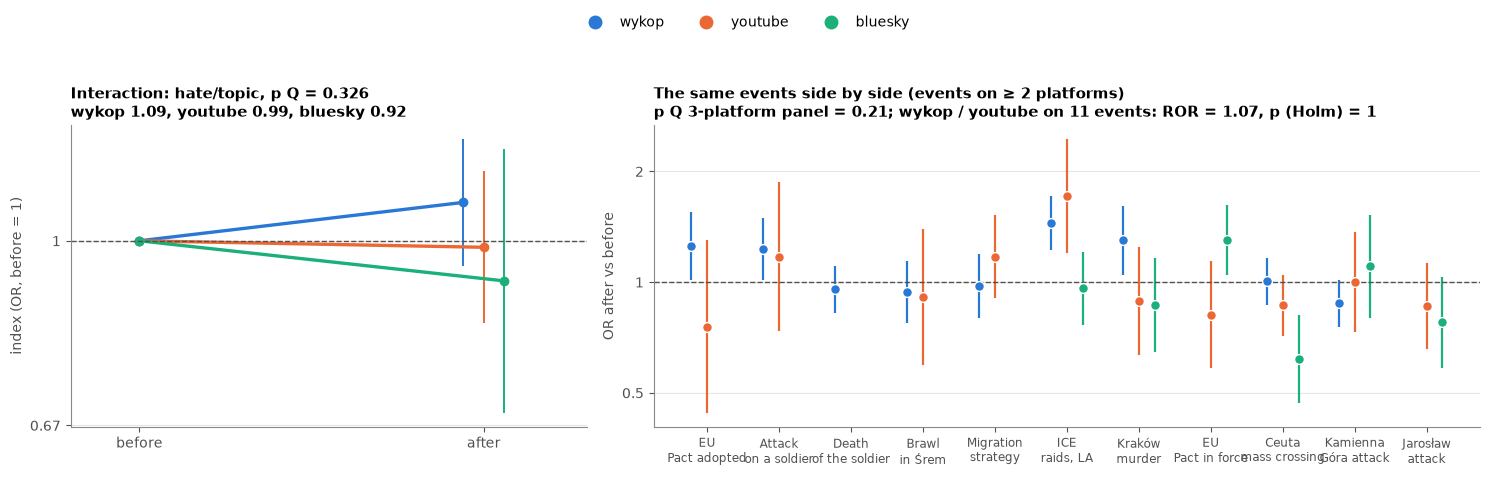

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.6]})
ax = axes[0]
pm = platform_meta(MAIN)
for i, p in enumerate(PL):
    m = pm[p]
    xo = 1 + (i - 1) * 0.06
    ax.plot([0, xo], [1, np.exp(m["mu"])], color=PLATFORM_COLORS[p], lw=2.4, marker="o")
    ax.vlines(xo, np.exp(m["lo"]), np.exp(m["hi"]), color=PLATFORM_COLORS[p], lw=1.4)
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_xticks([0, 1], ["before", "after"])
ax.set_xlim(-0.2, 1.3)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_ylabel("index (OR, before = 1)")
ax.set_title(f"Interaction: {MAIN}, p Q = {h4.loc[MAIN, 'p Q (all cells)']:.3g}\n"
             + ", ".join(f"{p} {np.exp(pm[p]['mu']):.2f}" for p in PL), fontsize=11)

ax = axes[1]
shared = [e for e in EVENT_ORDER if sum(f"{p}:{e}" in CELLS for p in PL) >= 2]  # events on ≥ 2 platforms
pos = {ev: i for i, ev in enumerate(shared)}
offs = np.linspace(-0.22, 0.22, len(PL))
for off, p in zip(offs, PL):
    e = E(MAIN)[(E(MAIN)["platform"] == p) & E(MAIN)["event"].isin(shared)].dropna(subset=["OR"])
    xx = e["event"].map(pos) + off
    ax.vlines(xx, e["OR lo"], e["OR hi"], color=PLATFORM_COLORS[p], lw=1.6)
    ax.scatter(xx, e["OR"], s=50, color=PLATFORM_COLORS[p], zorder=3, edgecolor="white")
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_xticks(range(len(shared)), [ev.replace(" ", "\n", 1) for ev in shared], fontsize=8.5)
ax.set_ylabel("OR after vs before")
r_wy = ror[(ror["metric"] == MAIN) & (ror["scope"] == "events shared by the pair") & (ror["pair"] == "wykop / youtube")].iloc[0]
ax.set_title(f"The same events side by side (events on ≥ 2 platforms)\n"
             f"p Q 3-platform panel = {h4.loc[MAIN, 'p Q (balanced panel)']:.3g}; "
             f"wykop / youtube on {len(shared)} events: ROR = {r_wy['ROR']:.2f}, p (Holm) = {r_wy['p (Holm)']:.3g}",
             fontsize=11)
platform_legend(fig, top=0.86)
plt.show()

**H4 conclusions (27 cells with enough comments):**

- **Platforms react to events similarly:** the pooled platform ORs – Wykop 1.07, YouTube 0.99, Bluesky 0.92 – do not differ
  in the meta-analysis (Q: p = 0.36; balanced panel p = 0.30), and no pair of platforms differs after Holm (p ≥ 0.61).
- The Wald model on all comments gives p = 0.03 (balanced 0.02): on Wykop hate rises slightly after events, on Bluesky it
  falls slightly. This model weights comments, so it is a weak signal, not a difference in the meta-analysis.
- `topic/all`: no differences (Q p = 0.54, Wald p = 0.36).
- **H4 verdict (reaction): not supported**, a weak signal only in the comment-level model. Levels – section 8.

## 2. Top 3 largest changes on a timeline

**Ranking:** |log RR| of the `hate/topic` metric – the largest relative changes in either direction. The ranking includes
only cells **significant after the Holm correction** and with at least `MIN_K_PRE_TOP` hateful comments "before"
(a small base gives absurd RRs). If there are fewer than 3 such cells, the list is filled with further (non-significant)
cells – the chart title then says *not significant*.

**Timeline:** days −7..+14, dashed line = day 0, horizontal dotted line = mean "before". Line = daily %
with a 3-day rolling mean (days with ≥ `MIN_DAILY_N` comments in the denominator). Grey bars in the background = number of
comments per day (right axis) – they show when the % is computed from a small sample.
When several platforms are on one chart, the Y axis is an **index = daily % / mean "before"** (1 = no change).


wykop: top 3


,RR,RR lo,RR hi,diff pp,p (Holm),direction,not_significant
cell,,,,,,,
"wykop:ICE raids, LA",1.31,1.21,1.41,7.42,0.000529,↑,False
wykop:Kraków murder,1.20,1.10,1.31,5.33,0.38,–,True
wykop:EU Pact adopted,1.17,1.08,1.27,4.72,0.756,–,True


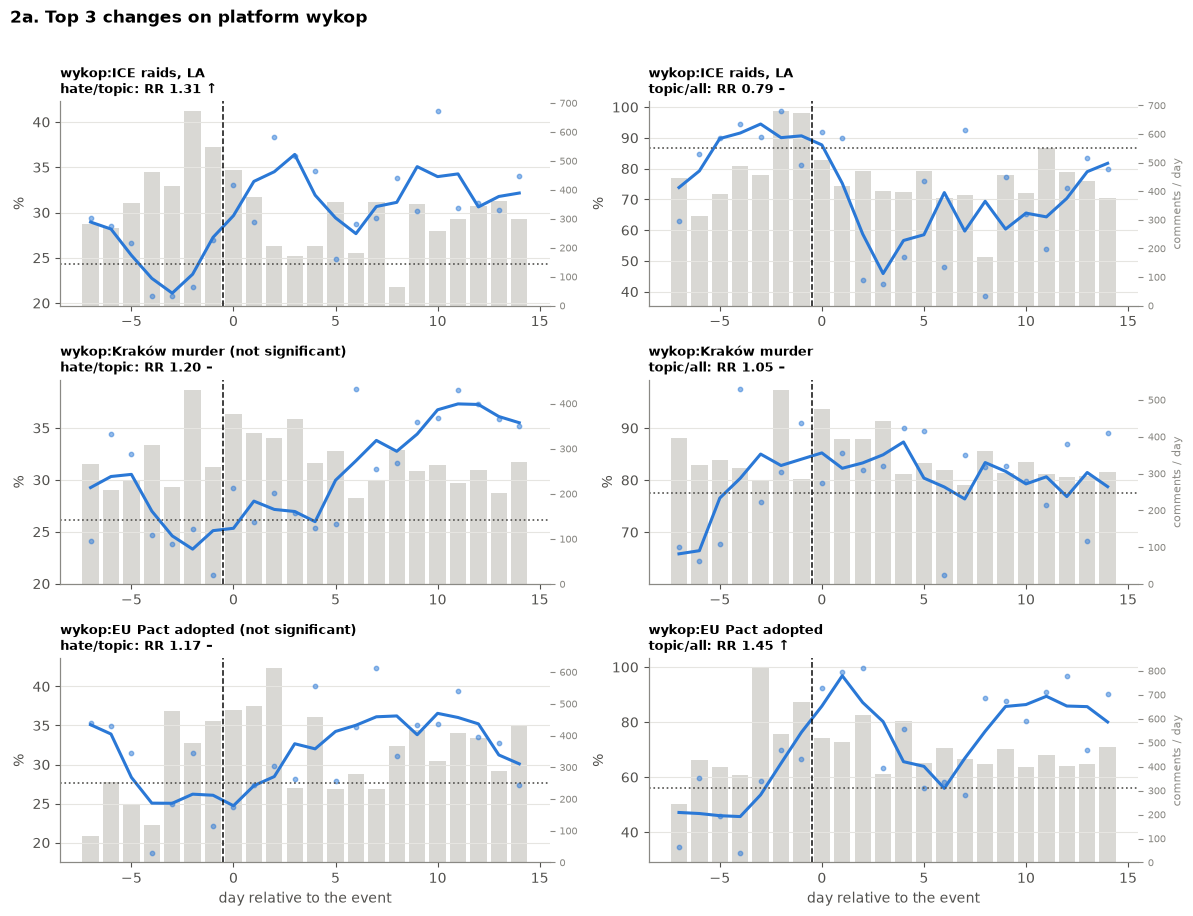


youtube: top 3


,RR,RR lo,RR hi,diff pp,p (Holm),direction,not_significant
cell,,,,,,,
"youtube:ICE raids, LA",1.34,1.27,1.42,13.35,0.0681,–,True
youtube:EU Pact adopted,0.84,0.78,0.90,-6.42,1,–,True
youtube:EU Pact in force,0.90,0.87,0.93,-5.04,1,–,True


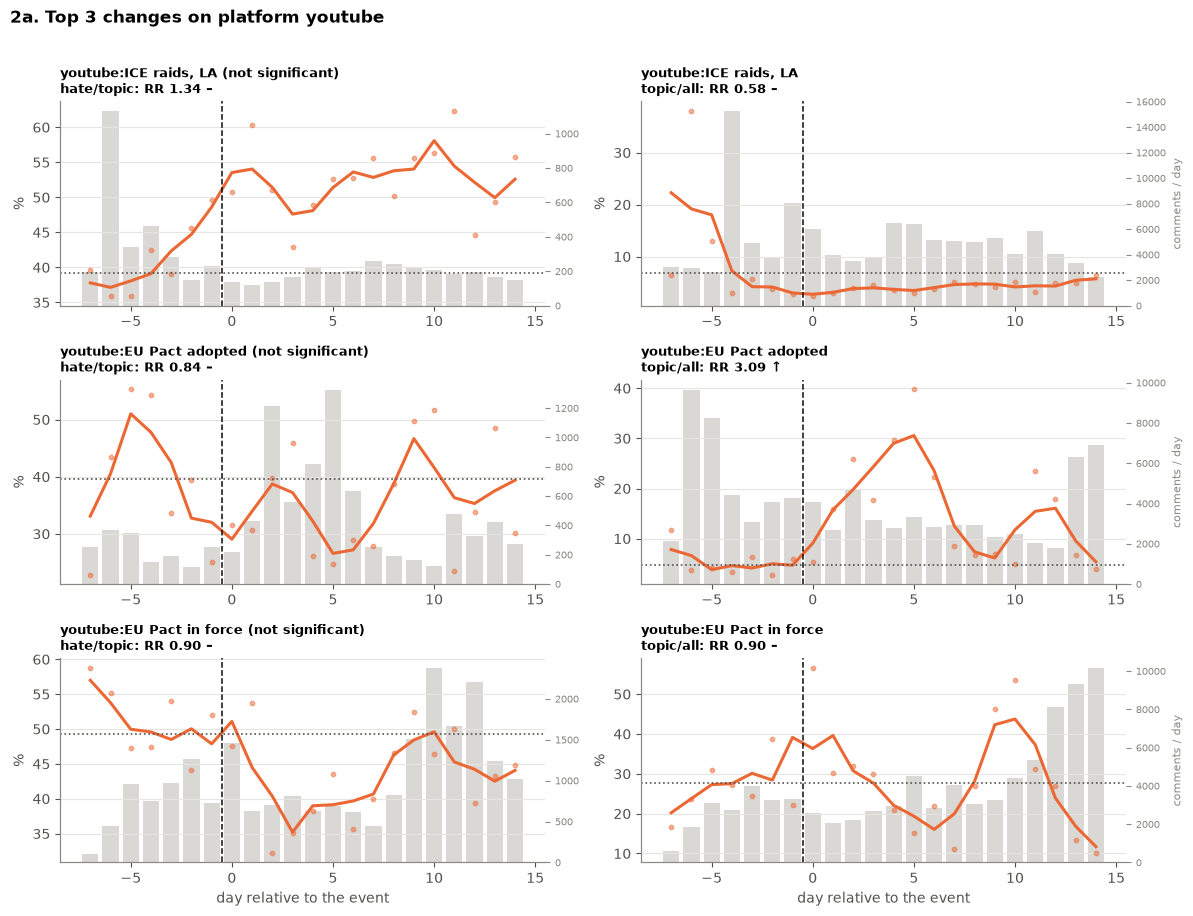


bluesky: top 3


,RR,RR lo,RR hi,diff pp,p (Holm),direction,not_significant
cell,,,,,,,
bluesky:Ceuta mass crossing,0.69,0.61,0.79,-8.74,0.0167,↓,False
bluesky:EU Pact in force,1.23,1.09,1.39,4.29,0.396,–,True
bluesky:Jarosław attack,0.82,0.70,0.96,-4.00,1,–,True


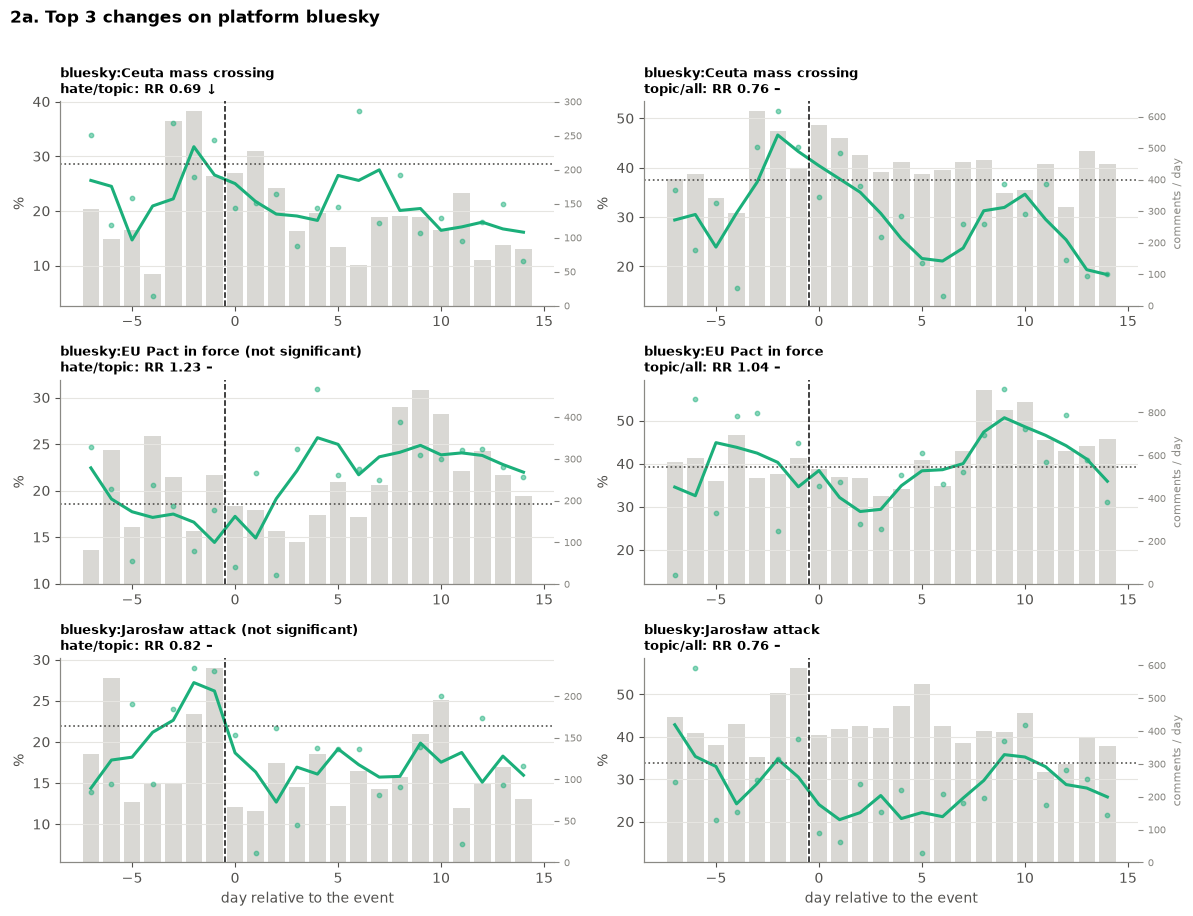

In [16]:
DAYS = range(WINDOW[0], WINDOW[1] + 1)


def daily_cell(cell, metric):
    d, col = subset(df[df["cell"] == cell], metric)
    g = d.groupby("relative_day").agg(num=(col, "sum"), den=(col, "size")).reindex(DAYS, fill_value=0)
    share = (100 * g["num"] / g["den"]).where(g["den"] >= MIN_DAILY_N)
    pre = g.loc[g.index < POST_FROM_DAY]
    base = 100 * pre["num"].sum() / max(pre["den"].sum(), 1)
    return share, base, g["den"]


def rank_cells(e):
    e = e.dropna(subset=["RR"]).assign(abs_lrr=lambda x: np.log(x["RR"]).abs())
    ok = e[e["significant"] & (e["k before"] >= MIN_K_PRE_TOP)].sort_values("abs_lrr", ascending=False)
    rest = e[~e.index.isin(ok.index) & (e["k before"] >= MIN_K_PRE_TOP)].sort_values("abs_lrr", ascending=False)
    top = pd.concat([ok.assign(not_significant=False), rest.assign(not_significant=True)]).head(TOP_K)
    return top


def plot_cells(top, title):
    fig, axes = plt.subplots(len(top), len(METRICS), figsize=(6 * len(METRICS), 3.1 * len(top)), squeeze=False)
    for i, (_, r) in enumerate(top.iterrows()):
        for j, metric in enumerate(METRICS):
            ax = axes[i, j]
            share, base, den = daily_cell(r["cell"], metric)
            ax2 = ax.twinx()
            ax2.bar(list(DAYS), den.values, color="#d9d8d4", width=0.8, zorder=0)
            ax2.set_ylabel("comments / day" if j == len(METRICS) - 1 else "", color=MUTED, fontsize=8)
            ax2.tick_params(axis="y", colors=MUTED, labelsize=7)
            ax2.grid(False)
            ax.set_zorder(ax2.get_zorder() + 1)
            ax.patch.set_visible(False)
            c = PLATFORM_COLORS[r["platform"]]
            ax.plot(list(DAYS), share.rolling(ROLL_DAYS, center=True, min_periods=1).mean(), color=c, lw=2.2)
            ax.scatter(list(DAYS), share.values, s=10, color=c, alpha=0.5)
            ax.axhline(base, color=INK2, ls=":", lw=1.2)
            ax.axvline(POST_FROM_DAY - 0.5, color=INK, ls="--", lw=1.1)
            ax.set_ylabel("%")
            em = E(metric).set_index("cell").loc[r["cell"]]
            tag = " (not significant)" if r["not_significant"] else ""
            ax.set_title(f"{r['cell']}{tag if j == 0 else ''}\n{metric}: RR {em['RR']:.2f} {em['direction']}", fontsize=9.5)
            if i == len(top) - 1:
                ax.set_xlabel("day relative to the event")
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


rank_all = rank_cells(E(MAIN))
for p in PL:
    top = rank_cells(E(MAIN)[E(MAIN)["platform"] == p])
    print(f"\n{p}: top {TOP_K}")
    display(fmt_p(top.set_index("cell")[["RR", "RR lo", "RR hi", "diff pp", "p (Holm)", "direction", "not_significant"]], 2))
    plot_cells(top, f"2a. Top {TOP_K} changes on platform {p}")

2b. Top 3 cells across all platforms (not pooled):


,RR,RR lo,RR hi,diff pp,p (Holm),direction,not_significant
cell,,,,,,,
bluesky:Ceuta mass crossing,0.69,0.61,0.79,-8.74,0.0167,↓,False
"wykop:ICE raids, LA",1.31,1.21,1.41,7.42,0.000529,↑,False
"youtube:ICE raids, LA",1.34,1.27,1.42,13.35,0.0681,–,True


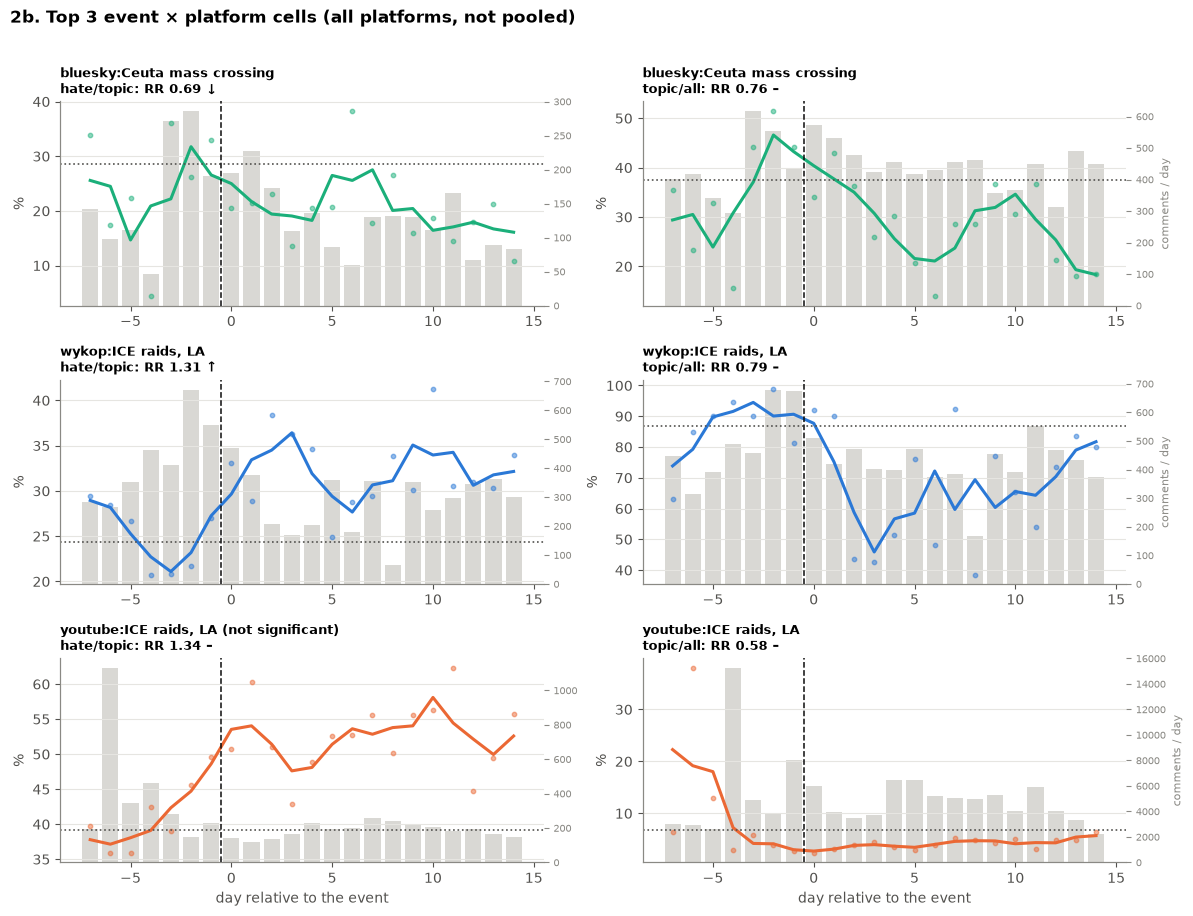

In [17]:
print(f"2b. Top {TOP_K} cells across all platforms (not pooled):")
display(fmt_p(rank_all.set_index("cell")[["RR", "RR lo", "RR hi", "diff pp", "p (Holm)", "direction", "not_significant"]], 2))
plot_cells(rank_all, f"2b. Top {TOP_K} event × platform cells (all platforms, not pooled)")

**2c. Top 3 events pooling platforms:** ranked by |pooled log-OR| from view 1b (fixed effects across platforms),
only events with at least 2 platforms. Lines = platforms, Y axis = index relative to the mean "before".

,platforms,OR,OR lo,OR hi,p (Holm),not_significant
event,,,,,,
"ICE raids, LA","wykop, youtube, bluesky",1.30,1.15,1.48,0.000534,False
Attack on a soldier,"wykop, youtube",1.22,1.02,1.46,0.297,True
Jarosław attack,"youtube, bluesky",0.82,0.68,1.00,0.381,True


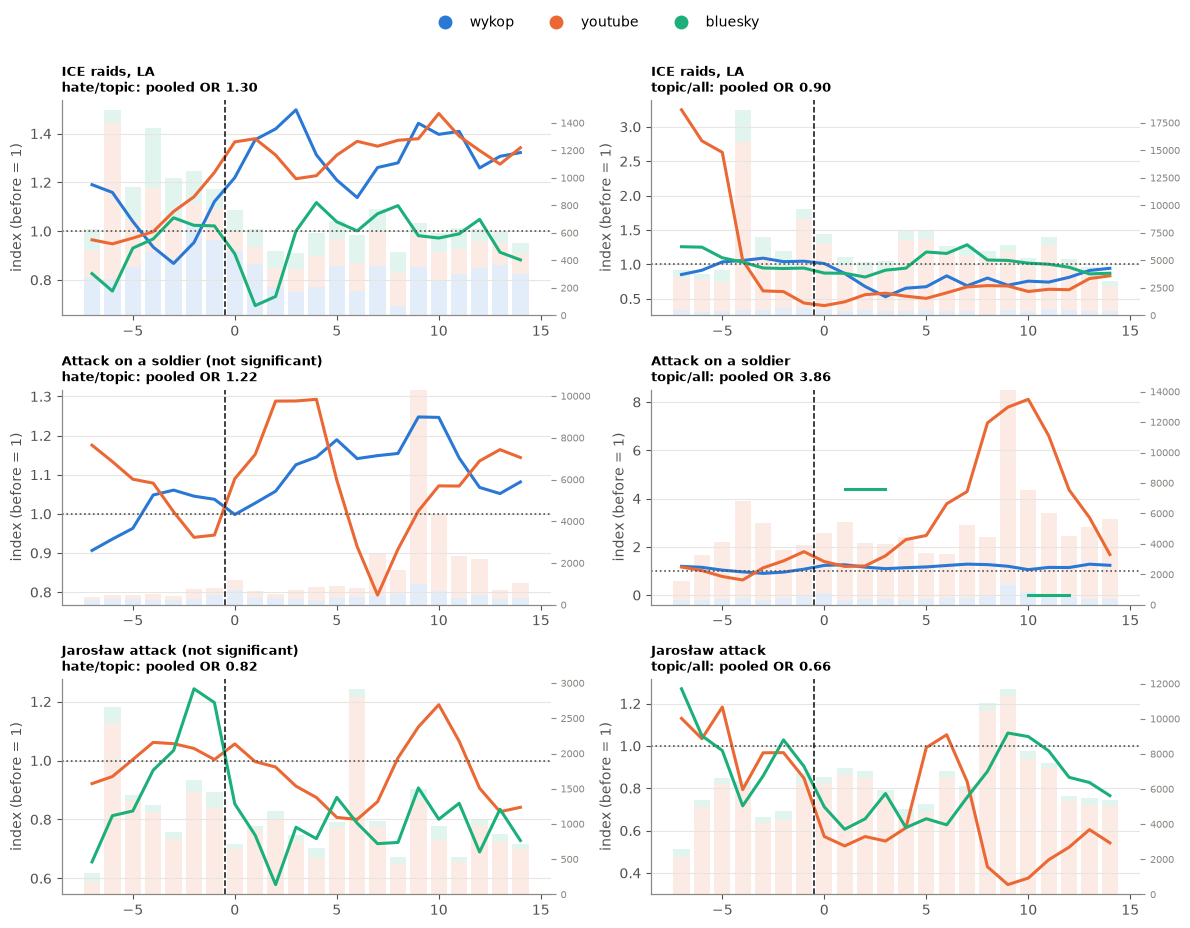

In [18]:
evp = ev_pool[(ev_pool["metric"] == MAIN) & (ev_pool["k"] >= 2)].assign(abs_mu=lambda x: x["mu"].abs())
top_ev = pd.concat([evp[evp["p (Holm)"] < ALPHA].sort_values("abs_mu", ascending=False).assign(not_significant=False),
                    evp[evp["p (Holm)"] >= ALPHA].sort_values("abs_mu", ascending=False).assign(not_significant=True)]).head(TOP_K)
display(fmt_p(top_ev.set_index("event")[["platforms", "OR", "OR lo", "OR hi", "p (Holm)", "not_significant"]], 2))

fig, axes = plt.subplots(len(top_ev), len(METRICS), figsize=(6 * len(METRICS), 3.1 * len(top_ev)), squeeze=False)
for i, (_, r) in enumerate(top_ev.iterrows()):
    for j, metric in enumerate(METRICS):
        ax = axes[i, j]
        ax2 = ax.twinx()
        bottom = np.zeros(len(DAYS))
        for p in PL:
            cell = f"{p}:{r['event']}"
            if cell not in CELLS:
                continue
            share, base, den = daily_cell(cell, metric)
            idx = (share / base) if base > 0 else share * np.nan
            ax.plot(list(DAYS), idx.rolling(ROLL_DAYS, center=True, min_periods=1).mean(), color=PLATFORM_COLORS[p], lw=2.2)
            ax2.bar(list(DAYS), den.values, bottom=bottom, color=PLATFORM_COLORS[p], alpha=0.13, width=0.8)
            bottom += den.values
        ax2.grid(False)
        ax2.tick_params(axis="y", colors=MUTED, labelsize=7)
        ax.set_zorder(ax2.get_zorder() + 1)
        ax.patch.set_visible(False)
        ax.axhline(1, color=INK2, ls=":", lw=1.2)
        ax.axvline(POST_FROM_DAY - 0.5, color=INK, ls="--", lw=1.1)
        ax.set_ylabel("index (before = 1)")
        em = ev_pool[(ev_pool["metric"] == metric) & (ev_pool["event"] == r["event"])].iloc[0]
        tag = " (not significant)" if (r["not_significant"] and j == 0) else ""
        ax.set_title(f"{r['event']}{tag}\n{metric}: pooled OR {em['OR']:.2f}", fontsize=9.5)
platform_legend(fig, top=0.95)
plt.show()

## 3. Most frequent words in hate (all platforms together)

- Material: comments with `hate = 1` from all platforms (without duplicates from overlapping Wykop windows).
- Processing: lower case, no links or mentions, tokens ≥ 3 letters, **`simplemma` lemmatisation**, no stop words.
- **Frequency:** the most frequent lemmas and bigrams in hate.
- **Distinctive words:** log-odds with a Dirichlet prior (Monroe et al. 2008) – hate vs comments on the migration topic
  **without** hate; `z` > 2 ≈ clearly more frequent in hate.
- The per-platform panels show whether a result comes from one platform only.
- **Word cloud:** one cloud from the lemmas of hate from **all platforms together** (size = number of occurrences).
  YouTube gives about 2/3 of the tokens, so it shapes the cloud the most.

In [19]:
STOPWORDS_PL = set("""
a aby ach acz aczkolwiek aj albo ale ależ ani aż bardziej bardzo bez bo bowiem by byli bym bynajmniej być był była było były będzie będą
cali cała cały chce chcą ci cię ciebie co cokolwiek coraz coś czasami czasem czemu czy czyli często daleko dla dlaczego dlatego do dobrze
dokąd dość dużo dwa dwaj dwie dwoje dziś dzisiaj gdy gdyby gdyż gdzie gdziekolwiek gdzieś go i ich ile im inna inne inny innych iż ja ją
jak jakaś jakby jaki jakichś jakie jakiś jakiż jakkolwiek jako jakoś je jeden jedna jedno jednak jednakże jego jej jemu jest jestem jeszcze
jeśli jeżeli już ją każdy kiedy kilka kimś kto ktokolwiek ktoś która które którego której który których którym którzy ku lat lecz lub
ma mają mam mamy mało mi mimo między mną mnie mogą moi moim moja moje może możliwe można mój mu musi my na nad nam nami nas nasi nasz nasza
nasze naszego naszych natomiast natychmiast nawet nic nich nie niech niego niej niemu nigdy nim nimi niż no o obok od około on ona one oni
ono oraz oto owszem pan pana pani po pod podczas pomimo ponad ponieważ powinien powinna powinni powinno poza prawie przecież przed przede
przedtem przez przy roku również sam sama są się skąd sobie sobą sposób swoje ta tak taka taki takie także tam te tego tej temu ten teraz
też to tobą tobie toteż trzeba tu tutaj twoi twoim twoja twoje twym twój ty tych tylko tym u w wam wami was wasz wasza wasze we według
wiele wielu więc więcej wszyscy wszystkich wszystkie wszystkim wszystko wtedy wy właśnie z za zapewne zawsze ze zł znowu znów został żaden
żadna żadne żadnych że żeby tez juz sie jak ktory ktora ktore bylo byl beda bedzie moze takze zeby ze tylko wiec niz przez tego tym jeszcze
tych tej mnie mieć mają ma mial miał było będą bylo były jakis jakies cos nikt nikogo niczego wszystkiego swój swoją swojej swoich swoim
naszym tymi takich takiej takim tamtych coś ktoś kogoś czegoś bym byś byście byśmy będę będziesz będziemy jestes jesteś jesteśmy
http https www com html pdf amp quot xd xdd xddd lenny bo tam tu oni ich sa sā też dla gdzie potem teraz chyba raczej
link user email phone mieć móc chcieć wiedzieć mówić czas rok raz ten taki który swój wszystek inny jakiś cały sam też
""".split())

URL_RE = re.compile(r"https?://\S+|www\.\S+|@\w+|\[\w+\]")
TOKEN_RE = re.compile(r"[a-ząćęłńóśźż]{3,}")
_LEMMA = {}


def lemma(t):
    if t not in _LEMMA:
        _LEMMA[t] = simplemma.lemmatize(t, lang="pl").lower()
    return _LEMMA[t]


STOP = STOPWORDS_PL | {lemma(w) for w in STOPWORDS_PL}


def tokens(text):
    toks = [lemma(t) for t in TOKEN_RE.findall(URL_RE.sub(" ", text.lower()))]
    return [t for t in toks if t not in STOP and len(t) >= 3]


def count_terms(texts):
    uni, bi = Counter(), Counter()
    for txt in texts:
        t = tokens(txt)
        uni.update(t)
        bi.update(f"{a} {b}" for a, b in zip(t, t[1:]))
    return uni, bi


def log_odds(c1, c2, prior, min_count=10):
    """Weighted log-odds ratio with an informative Dirichlet prior (Monroe et al. 2008); z > 0 = more frequent in c1."""
    n1, n2, a0 = sum(c1.values()), sum(c2.values()), sum(prior.values())
    rows = []
    for w, y1 in c1.items():
        if y1 < min_count:
            continue
        a, y2 = prior[w], c2.get(w, 0)
        delta = np.log((y1 + a) / (n1 + a0 - y1 - a)) - np.log((y2 + a) / (n2 + a0 - y2 - a))
        rows.append((w, y1, y2, delta / np.sqrt(1 / (y1 + a) + 1 / (y2 + a))))
    return pd.DataFrame(rows, columns=["word", "n hate", "n non-hate", "z"]).sort_values("z", ascending=False)


# no duplicates: the same Wykop comment can belong to two overlapping events
uniq = df.drop_duplicates(["platform", "uid"])
hm = uniq[uniq["hate"]]
nh = uniq[uniq["topic"] & ~uniq["hate"]]
print("hateful comments:", hm.groupby("platform").size().reindex(PL).to_dict())
print("on-topic comments without hate:", nh.groupby("platform").size().reindex(PL).to_dict())

terms = {}
for p in PL:
    terms[(p, "hate")] = count_terms(hm.loc[hm["platform"] == p, "text"])
    terms[(p, "non")] = count_terms(nh.loc[nh["platform"] == p, "text"])
uni_h = sum((terms[(p, "hate")][0] for p in PL), Counter())
bi_h = sum((terms[(p, "hate")][1] for p in PL), Counter())
uni_n = sum((terms[(p, "non")][0] for p in PL), Counter())
bi_n = sum((terms[(p, "non")][1] for p in PL), Counter())

hateful comments: {'wykop': 20068, 'youtube': 63298, 'bluesky': 3736}
on-topic comments without hate: {'wykop': 41103, 'youtube': 82173, 'bluesky': 14968}


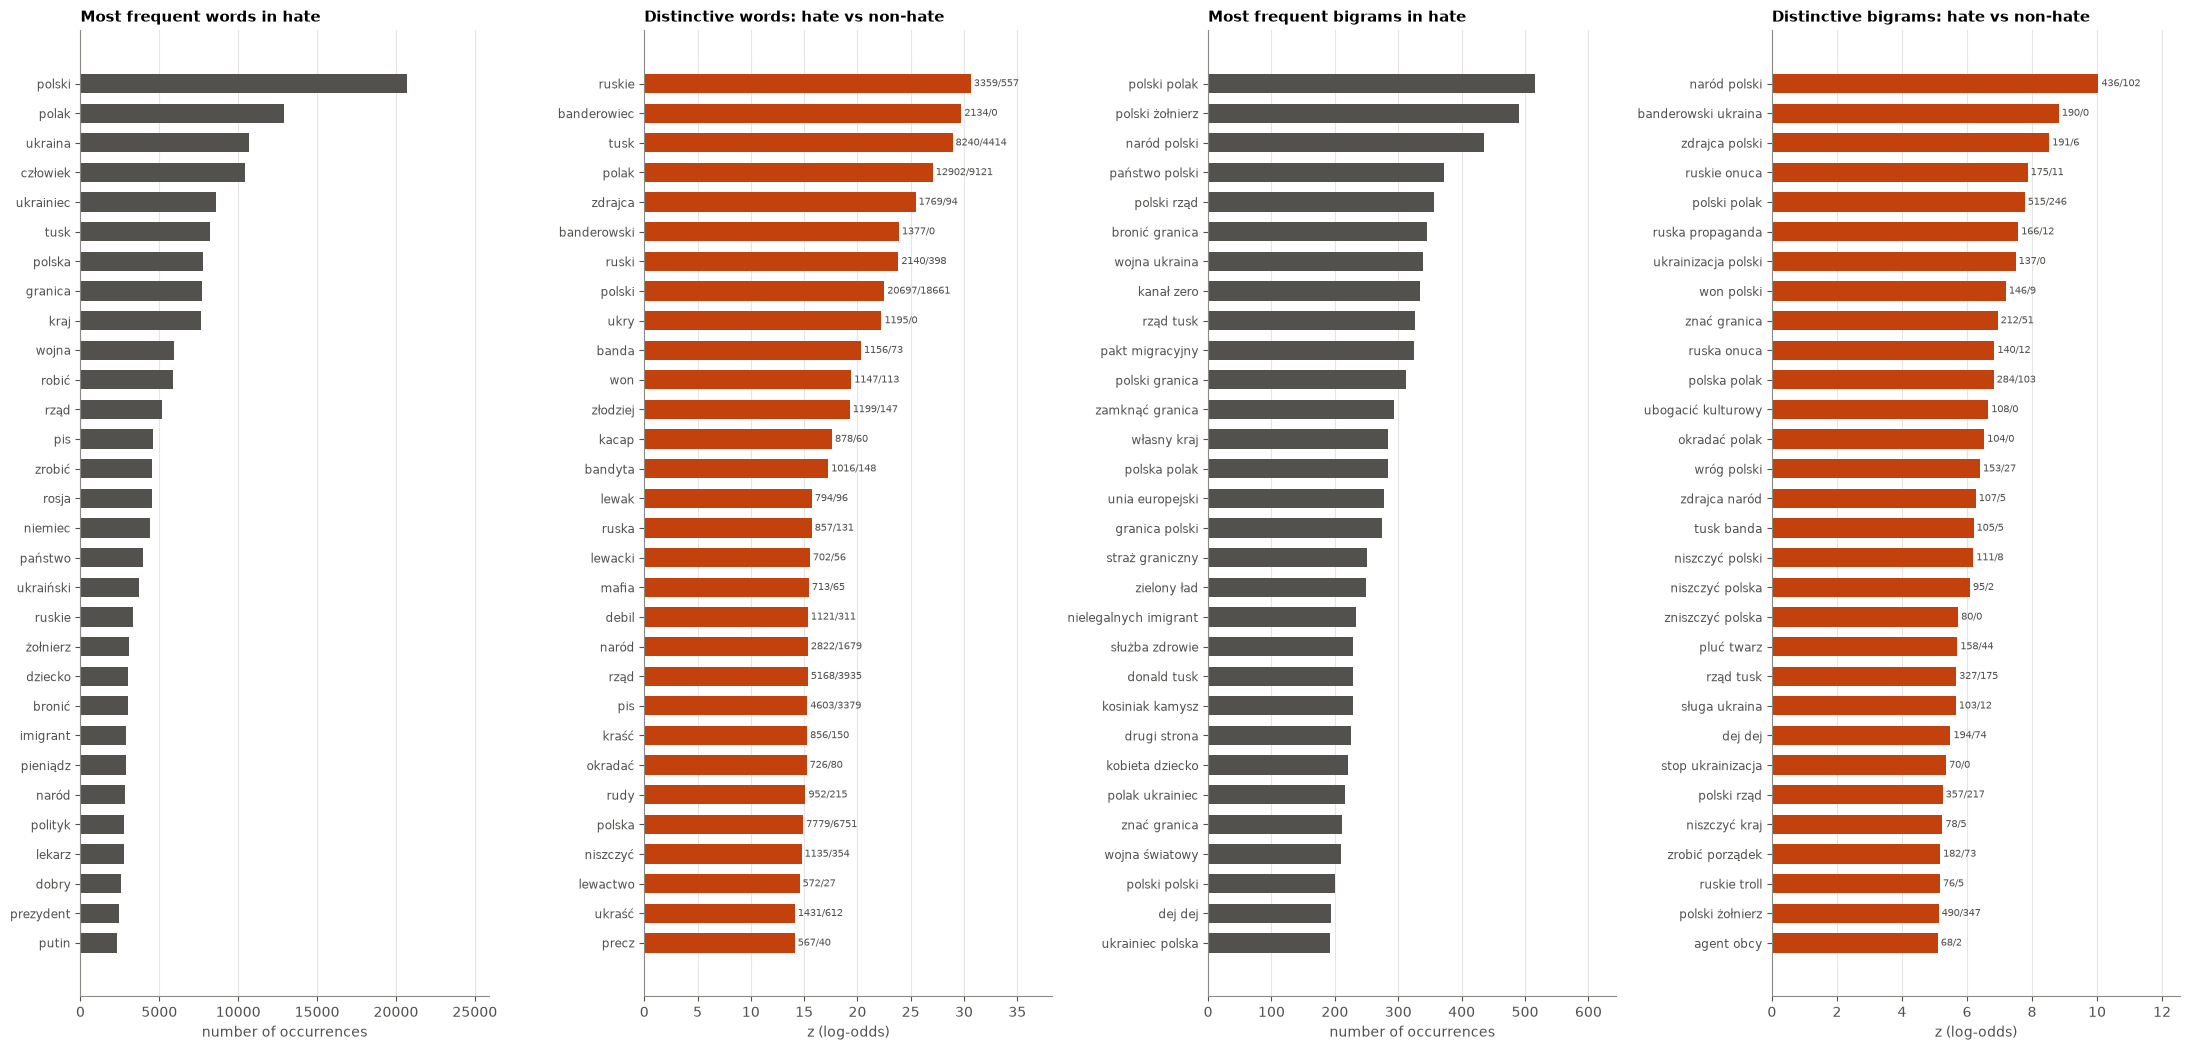

In [20]:
def barh(ax, labels, values, color, title, xlabel, notes=None):
    ax.barh(labels[::-1], values[::-1], color=color, height=0.65)
    if notes is not None:
        for yi, (v, n) in enumerate(zip(values[::-1], notes[::-1])):
            ax.text(v, yi, f" {n}", va="center", color=INK2, fontsize=7.5)
    ax.margins(x=0.25)
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel(xlabel)


fig, axes = plt.subplots(1, 4, figsize=(22, 0.3 * TOP_N_WORDS + 1.6))
for ax, (c_h, c_n, kind) in zip([axes[:2], axes[2:]], [(uni_h, uni_n, "words"), (bi_h, bi_n, "bigrams")]):
    top = c_h.most_common(TOP_N_WORDS)
    barh(ax[0], [w for w, _ in top], [n for _, n in top], INK2, f"Most frequent {kind} in hate", "number of occurrences")
    lo_ = log_odds(c_h, c_n, c_h + c_n, min_count=10 if kind == "words" else 5).head(TOP_N_WORDS)
    barh(ax[1], lo_["word"].tolist(), lo_["z"].tolist(), "#c2410c", f"Distinctive {kind}: hate vs non-hate",
         "z (log-odds)", notes=[f"{a}/{b}" for a, b in zip(lo_["n hate"], lo_["n non-hate"])])
plt.tight_layout()
plt.show()

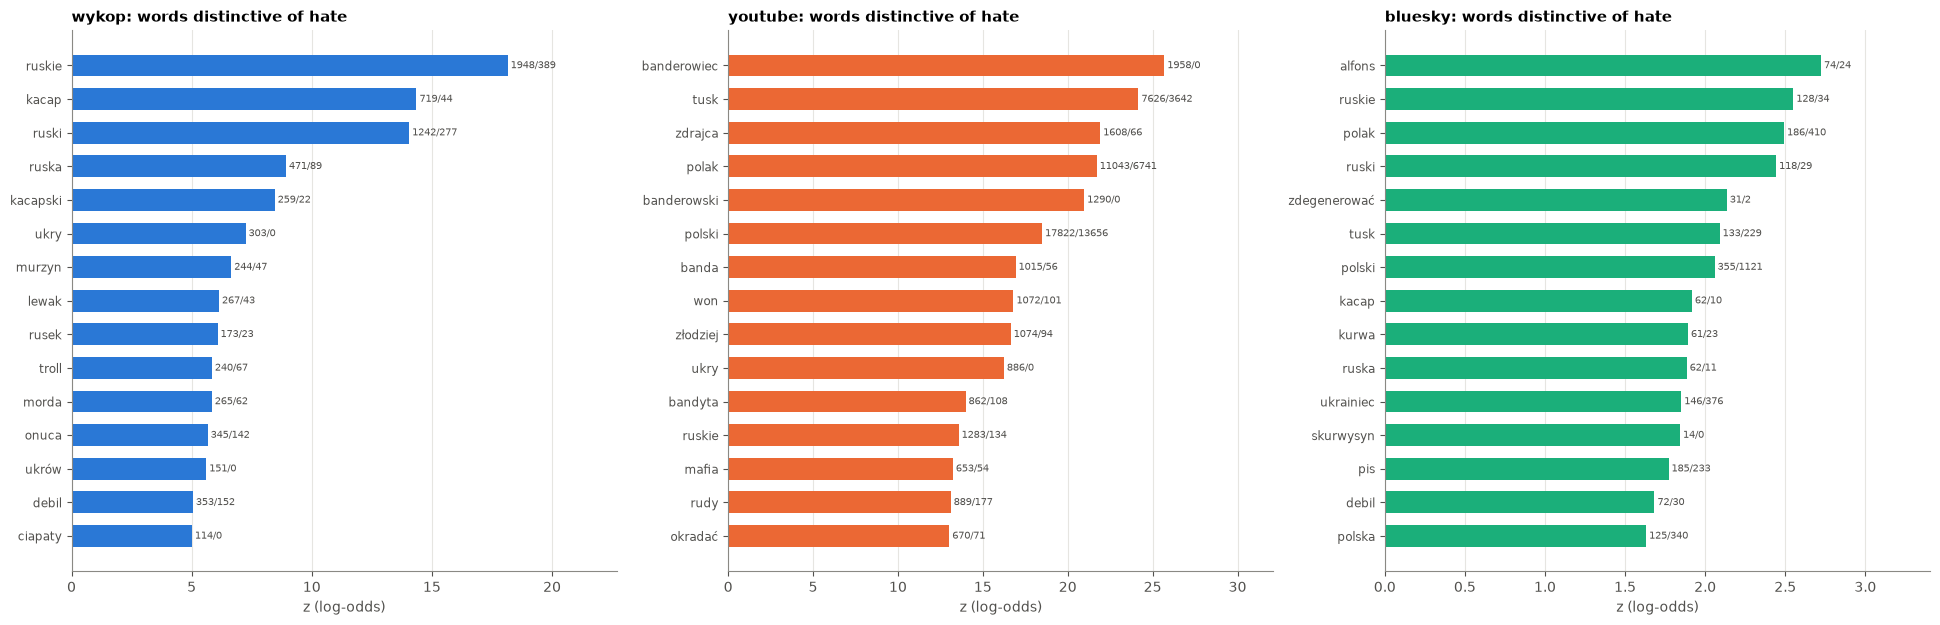

Platform share of the hate word pool (tokens): {'wykop': '22%', 'youtube': '75%', 'bluesky': '3%'}


In [21]:
TOP_PER_PL = 15
fig, axes = plt.subplots(1, len(PL), figsize=(6.5 * len(PL), 0.33 * TOP_PER_PL + 1.4))
for ax, p in zip(axes, PL):
    c_h, c_n = terms[(p, "hate")][0], terms[(p, "non")][0]
    lo_ = log_odds(c_h, c_n, uni_h + uni_n, min_count=5).head(TOP_PER_PL)
    barh(ax, lo_["word"].tolist(), lo_["z"].tolist(), PLATFORM_COLORS[p],
         f"{p}: words distinctive of hate", "z (log-odds)", notes=[f"{a}/{b}" for a, b in zip(lo_["n hate"], lo_["n non-hate"])])
plt.tight_layout()
plt.show()

print("Platform share of the hate word pool (tokens):",
      {p: f"{100 * sum(terms[(p, 'hate')][0].values()) / sum(uni_h.values()):.0f}%" for p in PL})

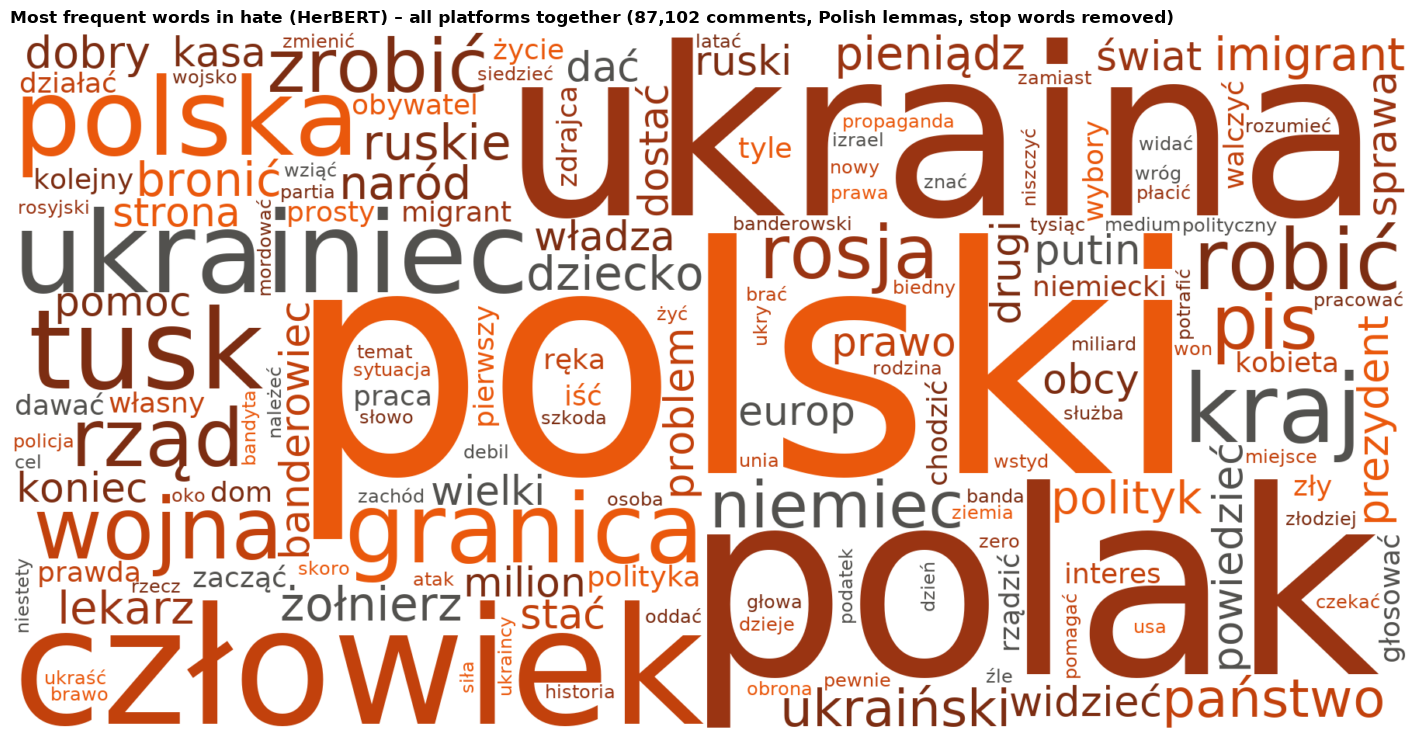

In [22]:
HATE_SHADES = ["#7c2d12", "#9a3412", "#c2410c", "#ea580c", "#52514e"]


def hate_color(word, font_size, position, orientation, random_state=None, **kw):
    return random_state.choice(HATE_SHADES)


wc = WordCloud(width=1800, height=900, background_color="white", max_words=150, prefer_horizontal=0.95,
               font_path=font_manager.findfont("DejaVu Sans"), color_func=hate_color, random_state=0,
               margin=4).generate_from_frequencies(dict(uni_h.most_common(400)))
fig, ax = plt.subplots(figsize=(15, 7.5))
ax.imshow(wc, interpolation="bilinear")
ax.axis("off")
ax.set_title(f"Most frequent words in hate (HerBERT) – all platforms together "
             f"({len(hm):,} comments, Polish lemmas, stop words removed)")
plt.tight_layout()
plt.show()

## 4. Who was targeted and with which slurs

**Target groups:** keywords (`TARGET_GROUPS`, as in the previous notebooks) in comments with `hate = 1`.
A comment can fall into several groups; we show separately how many comments name no group.

**Slur categories:** the lexicon `src/lexicon/slurs.py` run on `hate = 1` texts from all platforms
(YouTube has no `slurs/` stage, so we compute it here). 15 categories collapsed into 6 groups. The lexicon catches only part of
hate – **coverage** (printed above the chart) tells what % of hateful comments contain **any** term
from the lexicon. Categories on the map are % of **all** hateful comments (not only the covered ones), so none can
exceed coverage, and the rest is hate without dictionary slurs (e.g. "let them go back home", sarcasm, descriptive
threats). Coverage differs between platforms, so when comparing categories between platforms it is better to look at their
proportions relative to coverage than at the raw percentages.

Values = % of hateful comments (the whole period −7..+14). The per-event rows pool platforms
(computed on comments, so a larger platform weighs more – `n` is given in the label).

Lexicon coverage (% of hateful comments with ≥ 1 lexicon term): wykop 12%, youtube 17%, bluesky 5%


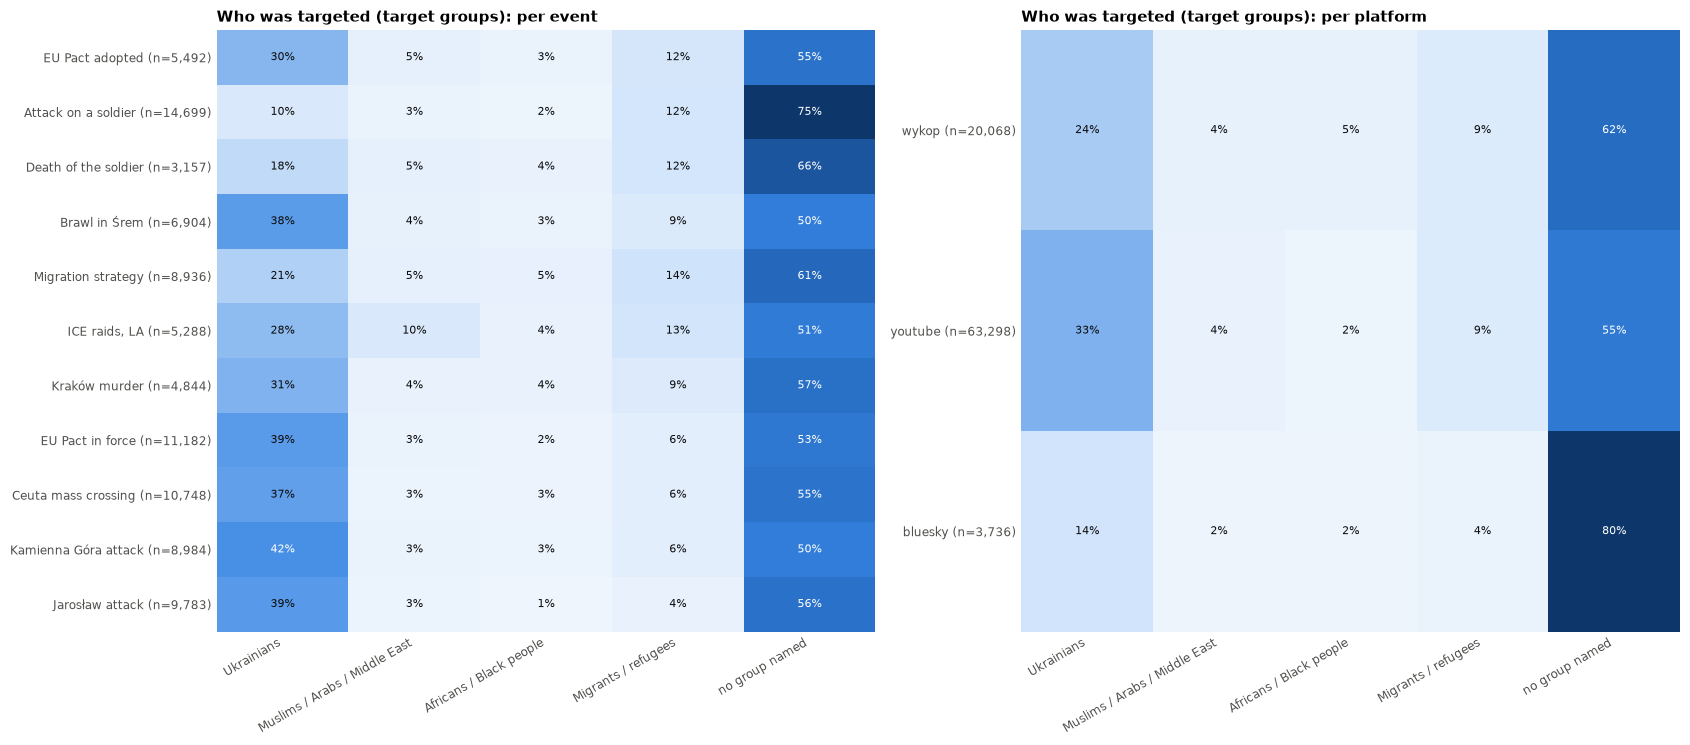

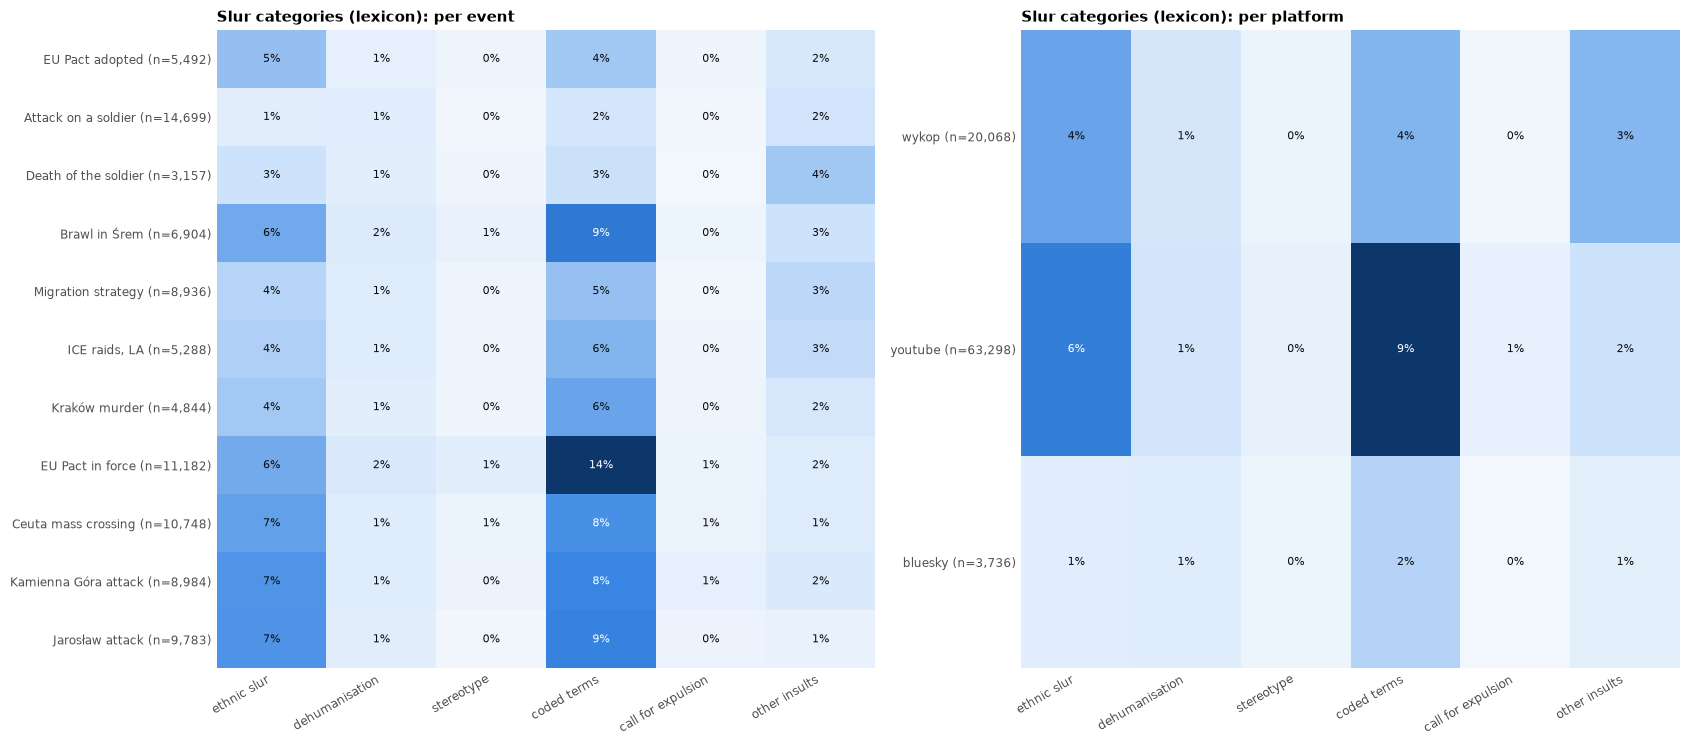

In [23]:
TARGET_GROUPS = {
    "Ukrainians": r"ukrai|ukraiń|\bukr|ukrop|bander|\bupa\b|upain|upowc|slava|sława|chachoł|chochoł",
    "Muslims / Arabs / Middle East": r"muzu?ł?m|muslim|islam|arab|allah|ciap|kozoj|talib|afga|syryj|syri|irak|turk|turc|pakist|czeczen|kebab|szariat|meczet",
    "Africans / Black people": r"murzyn|afryk|czarn|bambus|asfalt|nigeri|somal|erytre|małp|malp",
    "Migrants / refugees (general)": r"migran|imigran|uchodź|uchodz|nachodź|nachodz|najeźdź|najezdz|relokac|azyl|ubogac|nielegal|przybysz|inwazj",
}
SLUR_GROUPS = {
    "ethnic slur": ["obelga_etniczna", "obelga_etniczna_zlozenie", "obelga_historyczna"],
    "dehumanisation": ["dehumanizacja"],
    "stereotype": ["stereotyp", "stereotyp_swiadczenia", "stereotyp_seksistowski"],
    "coded terms": ["kod", "kod_historyczny", "kod_ironiczny", "kod_spiskowy", "kod_inwazji", "kod_prorosyjski"],
    "call for expulsion": ["wezwanie_do_wydalenia"],
    "other insults": ["obelga"],
}
CAT2GROUP = {c: g for g, cs in SLUR_GROUPS.items() for c in cs}

hm_ev = df[df["hate"]].copy()  # per event (possibly with duplicates between events)
low = hm_ev["text"].str.lower()
tg = pd.DataFrame({g: low.str.contains(rx, regex=True) for g, rx in TARGET_GROUPS.items()}, index=hm_ev.index)
tg["no group named"] = ~tg.any(axis=1)

found = hm_ev["text"].map(find_slurs)
sg = pd.DataFrame({g: found.map(lambda ts, g=g: any(CAT2GROUP.get(t.category) == g for t in ts)) for g in SLUR_GROUPS},
                  index=hm_ev.index)
unknown = {t.category for ts in found for t in ts} - set(CAT2GROUP)
if unknown:
    print("categories outside the mapping:", unknown)
for t in [tg, sg]:
    t[["platform", "event", "uid"]] = hm_ev[["platform", "event", "uid"]]

coverage = (hm_ev.assign(covered=found.map(bool)).drop_duplicates(["platform", "uid"])
            .groupby("platform")["covered"].mean().reindex(PL))
print("Lexicon coverage (% of hateful comments with ≥ 1 lexicon term):",
      ", ".join(f"{p} {100 * v:.0f}%" for p, v in coverage.items()))


def share_tab(t, by, order):
    cols = [c for c in t.columns if c not in ("platform", "event", "uid")]
    if by == "platform":  # per platform, without duplicates from overlapping windows
        t = t.drop_duplicates(["platform", "uid"])
    tab = 100 * t.groupby(by)[cols].mean().reindex(order)
    n = t.groupby(by).size().reindex(order)
    tab.index = [f"{i} (n={int(k):,})" for i, k in zip(tab.index, n)]
    return tab


def heat(ax, tab, title):
    vmax = np.nanmax(tab.values)
    ax.imshow(tab.values, cmap=BLUES, aspect="auto", vmin=0, vmax=vmax)
    for (i, j), v in np.ndenumerate(tab.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 0.55 * vmax else INK)
    ax.set_xticks(range(tab.shape[1]), [c.split(" (")[0] for c in tab.columns], rotation=30, ha="right", fontsize=8.5)
    ax.set_yticks(range(len(tab)), tab.index, fontsize=8.5)
    ax.grid(False)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, fontsize=11)


for t, name in [(tg, "Who was targeted (target groups)"), (sg, "Slur categories (lexicon)")]:
    fig, axes = plt.subplots(1, 2, figsize=(17, 0.45 * len(EVENT_ORDER) + 2.6), gridspec_kw={"width_ratios": [1, 1]})
    heat(axes[0], share_tab(t, "event", EVENT_ORDER), f"{name}: per event")
    heat(axes[1], share_tab(t, "platform", PL), f"{name}: per platform")
    plt.tight_layout()
    plt.show()

In [24]:
# most frequent lexicon terms and the change in target groups before → after
uniq_found = hm_ev.assign(found=found).drop_duplicates(["platform", "uid"])
term_tabs = {}
for p in PL:
    c = Counter(t.name for ts in uniq_found.loc[uniq_found["platform"] == p, "found"] for t in ts)
    n = (uniq_found["platform"] == p).sum()
    term_tabs[p] = [f"{w} ({100 * k / n:.1f}%)" for w, k in c.most_common(10)]
print("Most frequent lexicon terms (% of hateful comments on the platform):")
display(pd.DataFrame({p: v + [""] * (10 - len(v)) for p, v in term_tabs.items()}, index=range(1, 11)))

tg_u = tg.assign(period=hm_ev["period"]).drop_duplicates(["platform", "uid"])
cols = list(TARGET_GROUPS) + ["no group named"]
chg = (100 * tg_u.groupby(["platform", "period"])[cols].mean()).unstack("period")
print("Target groups before → after (% of hateful comments):")
display(pd.concat({c: chg[c][["before", "after"]].assign(**{"change pp": chg[c]["after"] - chg[c]["before"]}) for c in cols},
                  axis=1).reindex(PL).round(1))

Most frequent lexicon terms (% of hateful comments on the platform):


,wykop,youtube,bluesky
1,ukry (2.6%),banderowiec (5.0%),bydlo_holota (0.8%)
2,murzyni (1.3%),ukry (2.4%),banderowiec (0.7%)
3,bydlo_holota (1.2%),upadlina (1.9%),upa (0.6%)
4,banderowiec (1.1%),bydlo_holota (1.2%),ukry (0.5%)
5,ciapaci (1.0%),upa (1.0%),bandera (0.3%)
6,ukro-* (0.7%),banderyzm (0.9%),banderyzm (0.3%)
7,ubogacacze (0.7%),nachodzcy (0.6%),ciapaci (0.2%)
8,nachodzcy (0.7%),bandera (0.6%),ukro-* (0.2%)
9,bandera (0.4%),ukrainizacja (0.5%),murzyni (0.2%)
10,najezdzcy_inwazja (0.4%),ukro-* (0.5%),ss_galizien (0.2%)


Target groups before → after (% of hateful comments):


Ukrainians                 Muslims / Arabs / Middle East                 Africans / Black people                 Migrants / refugees (general)                 no group named                
period       before after change pp                        before after change pp                  before after change pp                        before after change pp         before after change pp
platform                                                                                                                                                                                              
wykop          27.4  23.1      -4.3                           4.1   4.6       0.6                     4.5   4.6       0.1                           6.0  10.2       4.2           62.0  62.6       0.6
youtube        38.6  31.7      -7.0                           4.6   3.5      -1.0                     2.4   2.4      -0.0                           7.7   9.5       1.8           50.5  56.2       5.7
bluesky        13.6  14.5       0.9                           2.5   1.7      -0.7                     2.1   1.9      -0.2                           4.0   3.4      -0.6           79.3  79.8       0.5

## 5. Concentration of authors of hate

Only **Wykop and Bluesky** – on YouTube authors are empty already in the raw data.
On Bluesky pseudonyms are assigned anew for each event, so author = (event, pseudonym);
on Wykop the author hash is stable, so an author is counted jointly across all events.

- **share of the top 1% / top 10%** of authors of hate in all hate, **Gini**, **Lorenz curve**,
- reference point: the same concentration for **all comments** – is hate more concentrated than ordinary writing?
- **% of authors who wrote at least one hateful comment**,
- (Wykop) authors writing hate at **several events**.

authors  comments  top 1% authors [% content]  top 10% authors [% content]  Gini  mean per author  % authors with ≥1 hate
platform what                                                                                                                                     
wykop    all comments      12446     79012                       16.66                        54.83  0.66             6.35                     NaN
         hate (HerBERT)     6250     20068                       11.05                        43.68  0.53             3.21                   50.22
bluesky  all comments       6163     71133                       15.77                        56.56  0.70            11.54                     NaN
         hate (HerBERT)     1471      3736                       13.52                        41.62  0.48             2.54                   23.87

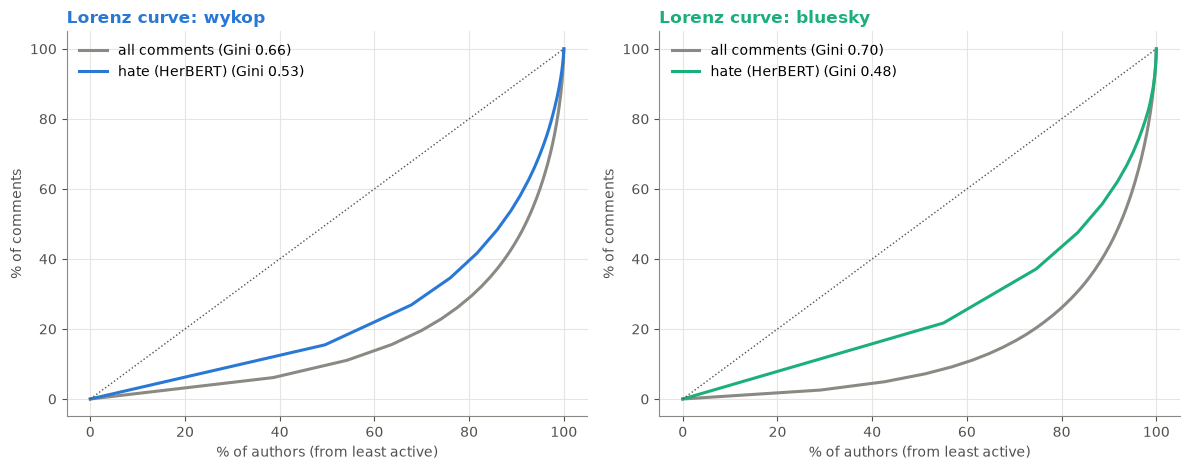

In [25]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    return 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n


def top_share(x, q):
    x = np.sort(np.asarray(x, float))[::-1]
    k = max(1, int(np.ceil(q * len(x))))
    return 100 * x[:k].sum() / x.sum()


def lorenz(x):
    x = np.sort(np.asarray(x, float))
    return np.r_[0, np.arange(1, len(x) + 1) / len(x)], np.r_[0, np.cumsum(x) / x.sum()]


AUTH_PL = [p for p in ["wykop", "bluesky"] if p in PL]
conc_rows, curves = [], {}
for p in AUTH_PL:
    d = uniq[(uniq["platform"] == p) & uniq["author_id"].notna()].copy()
    d["author"] = d["author_id"] if p == "wykop" else d["event"] + ":" + d["author_id"]
    per_author = d.groupby("author").agg(all=("comment_id", "size"), hate=("hate", "sum"))
    haters = per_author.loc[per_author["hate"] > 0, "hate"]
    curves[p] = {"all comments": lorenz(per_author["all"]), "hate (HerBERT)": lorenz(haters)}
    for name, x in [("all comments", per_author["all"]), ("hate (HerBERT)", haters)]:
        conc_rows.append({"platform": p, "what": name, "authors": len(x), "comments": int(x.sum()),
                          "top 1% authors [% content]": top_share(x, 0.01), "top 10% authors [% content]": top_share(x, 0.10),
                          "Gini": gini(x), "mean per author": x.mean()})
    conc_rows[-1]["% authors with ≥1 hate"] = 100 * len(haters) / len(per_author)
conc = pd.DataFrame(conc_rows).set_index(["platform", "what"])
display(conc.round(2))

fig, axes = plt.subplots(1, len(AUTH_PL), figsize=(6 * len(AUTH_PL), 4.8), squeeze=False)
for ax, p in zip(axes[0], AUTH_PL):
    for (name, (x, y)), ls in zip(curves[p].items(), ["-", "-"]):
        c = MUTED if name == "all comments" else PLATFORM_COLORS[p]
        ax.plot(x * 100, y * 100, color=c, ls=ls, lw=2.2,
                label=f"{name} (Gini {conc.loc[(p, name), 'Gini']:.2f})")
    ax.plot([0, 100], [0, 100], color=INK2, ls=":", lw=1)
    ax.set_xlabel("% of authors (from least active)")
    ax.set_ylabel("% of comments")
    ax.grid(axis="x", visible=True)
    ax.legend(loc="upper left")
    ax.set_title(f"Lorenz curve: {p}", color=PLATFORM_COLORS[p])
plt.tight_layout()
plt.show()

In [26]:
if "wykop" in AUTH_PL:
    d = df[(df["platform"] == "wykop") & df["hate"] & df["author_id"].notna()]
    ev_per_author = d.groupby("author_id")["event"].nunique()
    hate_per_author = d.drop_duplicates("comment_id").groupby("author_id").size()
    rep = pd.DataFrame({"events": ev_per_author, "hateful comments": hate_per_author})
    tab = rep.groupby(rep["events"].clip(upper=4)).agg(**{"authors": ("hateful comments", "size"), "hateful comments": ("hateful comments", "sum")})
    tab.index = [f"{i}" if i < 4 else "4+" for i in tab.index]
    tab["% authors"] = 100 * tab["authors"] / tab["authors"].sum()
    tab["% hate"] = 100 * tab["hateful comments"] / tab["hateful comments"].sum()
    print("Wykop: at how many events an author wrote hate (HerBERT)")
    display(tab.round(1))
    print("Note: the Śrem brawl / Migration strategy and Ceuta / Kamienna Góra have close windows – the same period of activity can count towards two events.")

Wykop: at how many events an author wrote hate (HerBERT)


,authors,hateful comments,% authors,% hate
1,3248,4427,52.0,22.1
2,1551,4014,24.8,20.0
3,654,2890,10.5,14.4
4+,797,8737,12.8,43.5


Note: the Śrem brawl / Migration strategy and Ceuta / Kamienna Góra have close windows – the same period of activity can count towards two events.


**How to read it:** *Gini* (0 = every author writes the same amount, 1 = one person writes everything) and the *share of the top 1% / 10%*
tell whether content is produced by a narrow group. Lorenz curve: the further from the diagonal, the greater the concentration.
The reference point is all comments – if hate were the work of a few "trolls", it would be more concentrated than
ordinary writing.

**Conclusions:**
- **Hate is less concentrated than ordinary activity:** Wykop – Gini 0.56 for hate vs 0.68 for all comments
  (the top 10% of authors write 46% of hate and 57% of all comments); Bluesky – 0.48 vs 0.70.
- **Hate is written by a broad group:** on Wykop 52% of authors wrote at least one hateful comment on the migration topic
  (3.7 on average), on Bluesky 24% (2.5).
- **Wykop has a stable core:** 15% of authors wrote hate at 4+ events and wrote half of the hate (50%) – with 11
  events (and close windows) returning authors weigh more than in Ola's analysis of 7 events.

## 6. Does hate collect more likes?

We compare comments **on the migration topic** (`topic = 1`): hateful vs non-hateful, separately on each
platform (the same topic, so the difference does not come from migration attracting more attention in general).

- median, mean, % of comments with ≥ 1 like,
- **Mann–Whitney test** (ranks; robust to single comments with thousands of likes) and the probability of superiority
  P(hate > non-hate),
- **negative binomial model** `likes ~ hate + C(event)` with standard errors clustered by thread →
  **ratio of means** (how many times more likes hate gets on average within the same event).

Wykop: `likes` are votes (ups − downs) and can be negative – they stay in the rank tests and are clipped to 0 in the model.

C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3709: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3709: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)


C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3709: RuntimeWarning: divide by zero encountered in log
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)
C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:3709: RuntimeWarning: invalid value encountered in multiply
  llf = coeff + size * np.log(prob) + endog * np.log(1 - prob)


C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  mlefit = super().fit(
C:\Users\aleks\projects\Social_Media_Hate_Speech\venv\Lib\site-packages\statsmodels\discrete\discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,n hate,n non-hate,median hate,median non-hate,mean hate,mean non-hate,% ≥1 hate,% ≥1 non-hate,P(hate > non-hate),p Mann-Whitney,ratio of means (NB),lo,hi,p NB,p NB (Holm)
platform,,,,,,,,,,,,,,,
wykop,20068,41103,1.0,1.0,13.537,10.740,59.019,54.689,0.527,1.05e-27,1.273,1.184,1.368,5.09e-11,1.02e-10
youtube,63298,82173,0.0,1.0,8.834,13.591,49.305,55.118,0.452,1.04e-242,0.648,0.610,0.688,4.17e-46,1.25e-45
bluesky,3736,14968,1.0,1.0,2.090,1.722,73.207,67.958,0.553,7.15e-25,1.218,1.137,1.305,1.95e-08,1.95e-08


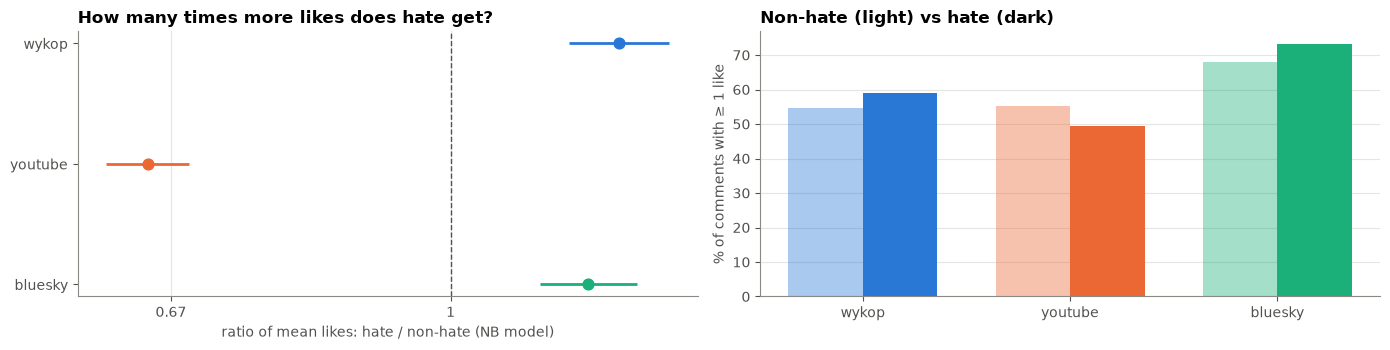

In [27]:
like_rows = []
for p in PL:
    d = uniq[(uniq["platform"] == p) & uniq["topic"]].dropna(subset=["likes"]).copy()
    h, n = d.loc[d["hate"], "likes"], d.loc[~d["hate"], "likes"]
    mw = stats.mannwhitneyu(h, n, alternative="two-sided")
    d["likes0"] = d["likes"].clip(lower=0).astype(int)
    d["hate01"] = d["hate"].astype(int)
    formula = "likes0 ~ hate01 + C(event)" if d["event"].nunique() > 1 else "likes0 ~ hate01"
    try:
        m = smf.negativebinomial(formula, data=d).fit(
            disp=0, maxiter=300, cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
        b, s, pv = m.params["hate01"], m.bse["hate01"], m.pvalues["hate01"]
    except Exception as ex:
        print(p, "NB model did not converge:", str(ex)[:80])
        b, s, pv = np.nan, np.nan, np.nan
    like_rows.append({"platform": p, "n hate": len(h), "n non-hate": len(n),
                      "median hate": h.median(), "median non-hate": n.median(),
                      "mean hate": h.mean(), "mean non-hate": n.mean(),
                      "% ≥1 hate": 100 * (h >= 1).mean(), "% ≥1 non-hate": 100 * (n >= 1).mean(),
                      "P(hate > non-hate)": mw.statistic / (len(h) * len(n)), "p Mann-Whitney": mw.pvalue,
                      "ratio of means (NB)": np.exp(b), "lo": np.exp(b - 1.96 * s), "hi": np.exp(b + 1.96 * s),
                      "p NB": pv})
likes = pd.DataFrame(like_rows).set_index("platform")
likes["p NB (Holm)"] = holm(likes["p NB"]).values
display(fmt_p(likes, 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.6))
ax = axes[0]
y = np.arange(len(PL))
for yi, p in zip(y, PL):
    r = likes.loc[p]
    ax.hlines(yi, r["lo"], r["hi"], color=PLATFORM_COLORS[p], lw=2)
    ax.scatter(r["ratio of means (NB)"], yi, s=60, color=PLATFORM_COLORS[p], zorder=3)
ax.axvline(1, color=INK2, ls="--", lw=1)
ax.set_xscale("log")
log_ticks(ax, "x")
ax.set_yticks(y, PL)
ax.invert_yaxis()
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
ax.set_xlabel("ratio of mean likes: hate / non-hate (NB model)")
ax.set_title("How many times more likes does hate get?")
ax = axes[1]
w = 0.36
ax.bar(y - w / 2, likes["% ≥1 non-hate"], width=w, color=[PLATFORM_COLORS[p] for p in PL], alpha=0.4, label="non-hate")
ax.bar(y + w / 2, likes["% ≥1 hate"], width=w, color=[PLATFORM_COLORS[p] for p in PL], label="hate")
ax.set_xticks(y, PL)
ax.set_ylabel("% of comments with ≥ 1 like")
ax.set_title("Non-hate (light) vs hate (dark)")
plt.tight_layout()
plt.show()

**How to read it:** *P(hate > non-hate)* = the chance that a random hateful comment has more likes than a random comment about
migration without hate (0.5 = no difference). *Ratio of means (NB)* = how many times more likes hate gets on average within the
same event (1 = the same).

**Conclusions:**
- **Wykop and Bluesky: hate collects more likes** than on-topic comments without hate – Wykop ×1.29 [1.21; 1.37],
  Bluesky ×1.22 [1.14; 1.31], both significant after Holm; a small effect (P(hate > non-hate) = 0.53 and 0.55, equal medians).
- **YouTube: the opposite** – hate has fewer likes on average (×0.65; P(hate > non-hate) = 0.45, Mann–Whitney p < 0.001);
  the confidence interval from the NB model could not be computed (a convergence problem), so we rely on Mann–Whitney.
- The same picture as in Ola's LLM analysis: no universal "rewarding of hate", the result depends on the platform.

## 7. Event type and size of the change (H2)

**Types:** criminal (violence / incident; 5 events), political (4), disinformation (1), border crisis (1).
**Reach:** domestic (7) vs foreign (4).

- **Main test:** meta-regression of log-OR (all cells) with the moderator `type` and a control for platform;
  omnibus test of the moderator (F, Knapp–Hartung adjustment).
- **Contrast:** criminal vs the rest; **reach:** domestic vs foreign (the same meta-regression).
- **Permutation test:** we shuffle type labels between **events** (all possible assignments) and
  count how often the statistic is at least as large as the real one – an exact p without assuming normality.
- **Direction:** how many cells of each type have a significant increase / decrease.
- **Per platform:** Wykop and YouTube – the criminal vs rest contrast; Bluesky – description only.

⚠️ An exploratory result: 11 events, and disinformation and border crisis have one each – a "type effect" there
cannot be distinguished from the effect of that particular event.

In [28]:
def meta_reg(y, se, X):
    """Mixed-effects meta-regression: τ² by the method of moments (DerSimonian–Laird), Knapp–Hartung errors."""
    y, v, X = np.asarray(y, float), np.asarray(se, float) ** 2, np.asarray(X, float)
    k, p = X.shape
    W = np.diag(1 / v)
    XtWX_inv = np.linalg.pinv(X.T @ W @ X)
    P = W - W @ X @ XtWX_inv @ X.T @ W
    q_e = float(y @ P @ y)
    tau2 = max(0.0, (q_e - (k - p)) / np.trace(P))
    Ws = np.diag(1 / (v + tau2))
    cov = np.linalg.pinv(X.T @ Ws @ X)
    b = cov @ X.T @ Ws @ y
    s2 = max(1.0, float((y - X @ b) @ Ws @ (y - X @ b)) / (k - p))
    return b, cov * s2, tau2, k - p


def moderator_test(e, mod_cols, control_platform=True):
    """Omnibus (F) test for moderator columns; returns (F, p, moderator coefficients, df)."""
    X = pd.DataFrame({"const": 1.0}, index=e.index)
    for c in mod_cols:
        X[c] = e[c].astype(float)
    if control_platform:
        for p in PL[1:]:
            X[f"pl_{p}"] = (e["platform"] == p).astype(float)
    X = X.loc[:, X.std().fillna(0).gt(0) | (X.columns == "const")]
    keep = [c for c in mod_cols if c in X.columns]
    if not keep:
        return np.nan, np.nan, {}, 0
    b, cov, tau2, dfr = meta_reg(e["log OR"], e["se"], X.values)
    idx = [list(X.columns).index(c) for c in keep]
    bm, cm = b[idx], cov[np.ix_(idx, idx)]
    F = float(bm @ np.linalg.pinv(cm) @ bm) / len(idx)
    return F, stats.f.sf(F, len(idx), dfr), dict(zip(keep, bm)), dfr


def type_dummies(e, type_of_event):
    t = e["event"].map(type_of_event)
    return e.assign(**{f"type_{x}": (t == x).astype(float) for x in TYPE_ORDER[1:]},
                    criminal=(t == "criminal").astype(float),
                    foreign=e["event"].map(lambda ev: EVENT_META[ev][1] == "foreign").astype(float))


TYPE_COLS = [f"type_{x}" for x in TYPE_ORDER[1:]]
true_type = {ev: EVENT_META[ev][0] for ev in EVENT_ORDER}


def perm_test(e, kind):
    """All assignments of type labels to events with the same counts; statistic = moderator F."""
    events = list(dict.fromkeys(e["event"]))
    labels = [true_type[ev] for ev in events]
    obs = moderator_test(type_dummies(e, true_type), TYPE_COLS if kind == "type" else ["criminal"])[0]
    from itertools import permutations
    stats_ = []
    for perm in set(permutations(labels)):
        tp = dict(zip(events, perm))
        F = moderator_test(type_dummies(e, tp), TYPE_COLS if kind == "type" else ["criminal"])[0]
        if not np.isnan(F):
            stats_.append(F)
    stats_ = np.array(stats_)
    return obs, np.mean(stats_ >= obs - 1e-12), stats_


h2_rows, perm_dist = [], {}
for metric in METRICS:
    e = type_dummies(E(metric).dropna(subset=["log OR"]), true_type)
    F, p, coef, dfr = moderator_test(e, TYPE_COLS)
    Fk, pk, ck, _ = moderator_test(e, ["criminal"])
    Fz, pz, cz, _ = moderator_test(e, ["foreign"])
    obs, pperm, dist = perm_test(e, "type")
    obs_k, pperm_k, dist_k = perm_test(e, "criminal")
    perm_dist[metric] = (obs, dist, obs_k, dist_k)
    h2_rows.append({"metric": metric, "cells": len(e), "F type": F, "p type (meta-regression)": p,
                    "p type (permutation)": pperm, "assignments (type)": len(dist),
                    "OR criminal vs rest": np.exp(ck.get("criminal", np.nan)), "p criminal": pk,
                    "p criminal (permutation)": pperm_k, "assignments (contrast)": len(dist_k),
                    "OR foreign vs domestic": np.exp(cz.get("foreign", np.nan)), "p reach": pz,
                    **{f"OR {t} vs criminal": np.exp(coef.get(f"type_{t}", np.nan)) for t in TYPE_ORDER[1:]}})
h2 = pd.DataFrame(h2_rows).set_index("metric")
display(fmt_p(h2, 3))

,cells,F type,p type (meta-regression),p type (permutation),assignments (type),OR criminal vs rest,p criminal,p criminal (permutation),assignments (contrast),OR foreign vs domestic,p reach,OR political vs criminal,OR disinformation vs criminal,OR border crisis vs criminal
metric,,,,,,,,,,,,,,
hate/topic,25,2.778,0.0693,0.0994,13860,0.906,0.28,0.403,13860,1.083,0.387,1.219,1.096,0.893
topic/all,25,0.675,0.578,0.685,13860,1.189,0.535,0.578,13860,0.908,0.729,0.975,0.804,0.551


In [29]:
dir_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])
    for t in TYPE_ORDER:
        g = e[e["type"] == t]
        m = meta_random(g["log OR"], g["se"])
        dir_rows.append({"metric": metric, "type": t, "events": g["event"].nunique(), "cells": len(g),
                         "increase": int((g["log OR"] > 0).sum()), "decrease": int((g["log OR"] < 0).sum()),
                         "significant ↑": int((g["direction"] == "↑").sum()), "significant ↓": int((g["direction"] == "↓").sum()),
                         **or_row(m)})
dirs = pd.DataFrame(dir_rows).set_index(["metric", "type"])
print("Direction and strength of changes per type (OR = random-effects meta-analysis of the cells of that type):")
display(fmt_p(dirs, 2))

pp_rows = []
for metric in METRICS:
    for p in PL:
        e = type_dummies(E(metric)[E(metric)["platform"] == p].dropna(subset=["log OR"]), true_type)
        row = {"metric": metric, "platform": p, "events": len(e)}
        if p != "bluesky" and e["criminal"].nunique() > 1:
            Fk, pk, ck, _ = moderator_test(e, ["criminal"], control_platform=False)
            Fz, pz, cz, _ = moderator_test(e, ["foreign"], control_platform=False)
            row.update({"OR criminal vs rest": np.exp(ck.get("criminal", np.nan)), "p criminal": pk,
                        "OR foreign vs domestic": np.exp(cz.get("foreign", np.nan)), "p reach": pz})
        pp_rows.append(row)
print("Per platform (contrast not computed for Bluesky):")
display(fmt_p(pd.DataFrame(pp_rows).set_index(["metric", "platform"]), 3))

Direction and strength of changes per type (OR = random-effects meta-analysis of the cells of that type):


events  cells  increase  decrease  significant ↑  significant ↓    OR  OR lo  OR hi       p
metric     type                                                                                                       
hate/topic criminal             5     10         4         6              0              0  0.96   0.87   1.06   0.415
           political            4      9         5         4              1              0  1.15   0.95   1.38   0.123
           disinformation       1      3         1         2              0              0  1.02   0.55   1.91   0.908
           border crisis        1      3         1         2              0              1  0.83   0.46   1.52    0.32
topic/all  criminal             5     10         5         5              1              0  1.16   0.68   1.99   0.537
           political            4      9         5         4              2              0  1.12   0.65   1.91   0.644
           disinformation       1      3         1         2              0              0  0.88   0.48   1.65   0.485
           border crisis        1      3         0         3              0              0  0.64   0.36   1.15  0.0824

Per platform (contrast not computed for Bluesky):


events  OR criminal vs rest p criminal  OR foreign vs domestic p reach
metric     platform                                                                        
hate/topic wykop          9                0.836      0.141                   1.184   0.198
           youtube       10                0.961      0.809                   0.993   0.966
           bluesky        6                  NaN                                NaN        
topic/all  wykop          9                1.166      0.788                   0.758   0.641
           youtube       10                1.615       0.41                   0.837   0.768
           bluesky        6                  NaN                                NaN

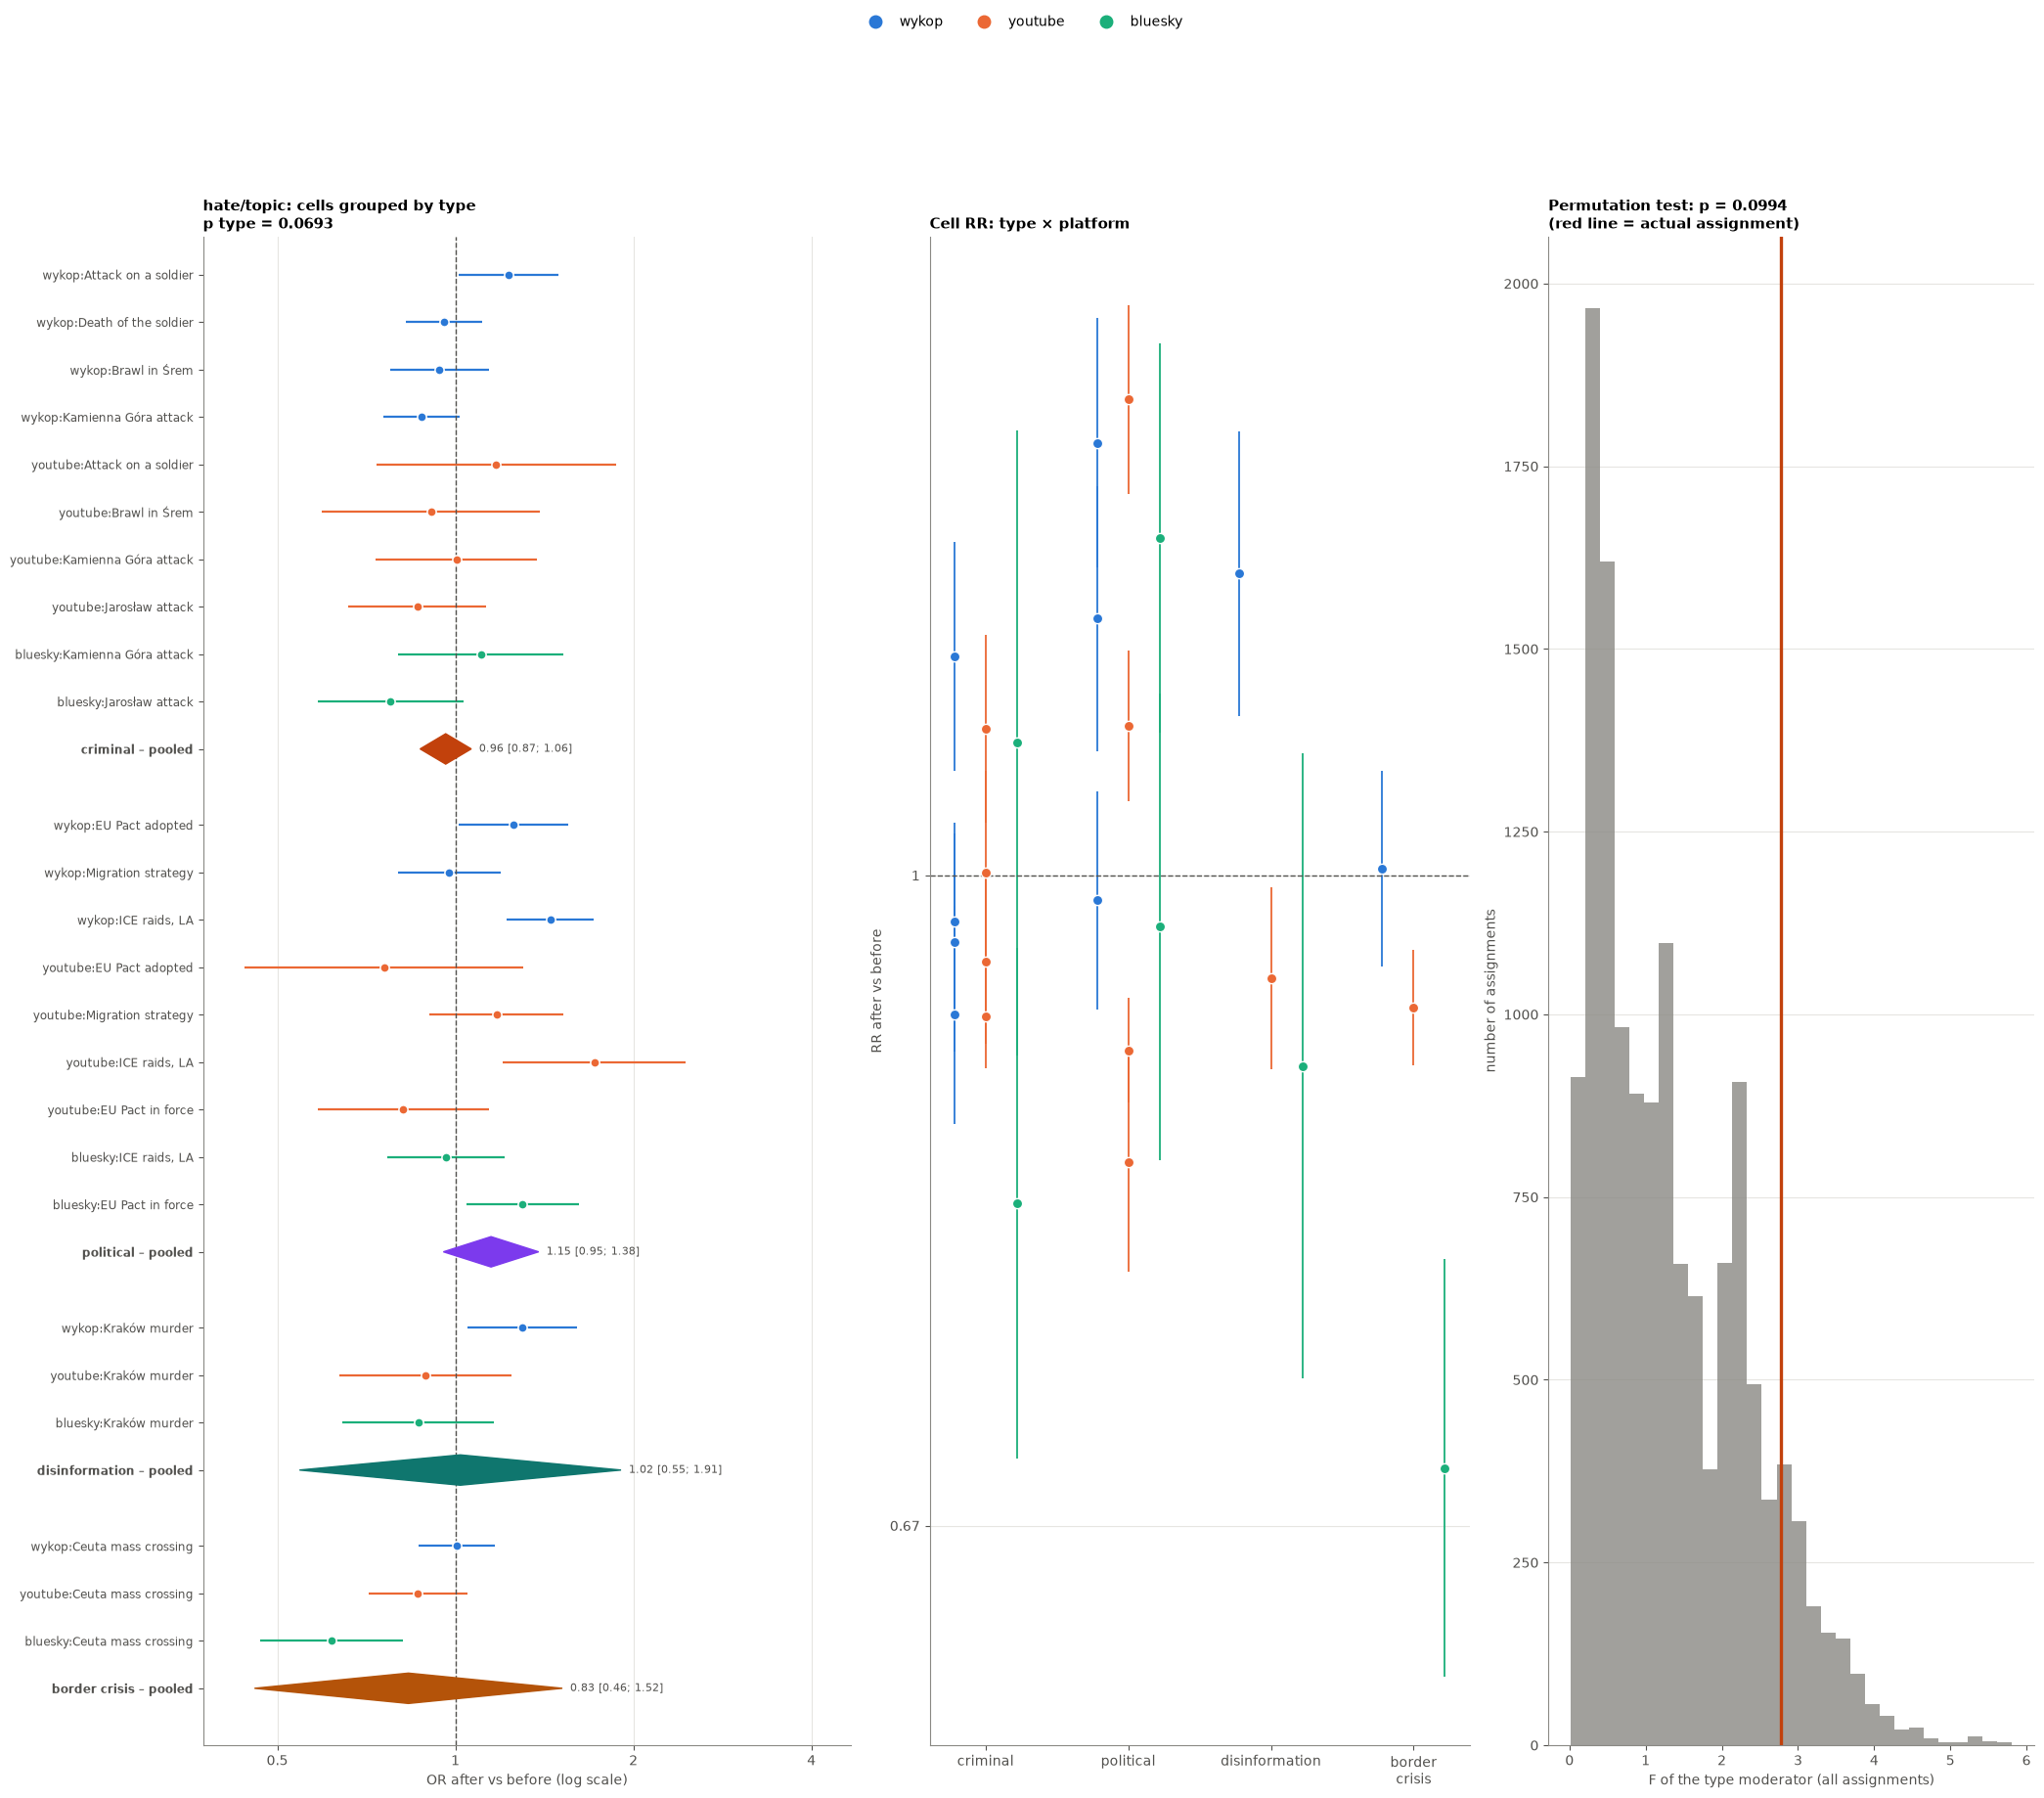

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(21, 0.5 * len(CELLS) + 3.4), gridspec_kw={"width_ratios": [1.2, 1, 0.9]})
groups = []
for t in TYPE_ORDER:
    g = E(MAIN)[E(MAIN)["type"] == t].dropna(subset=["log OR"])
    m = meta_random(g["log OR"], g["se"])
    groups.append({"label": f"{t} – pooled", "items": items_from(g.assign(lab=g["cell"]), "lab",
                                                                   lambda r_: PLATFORM_COLORS[r_["platform"]]),
                   "diamond": dia(m, TYPE_COLORS[t])})
forest(axes[0], groups, title=f"{MAIN}: cells grouped by type\np type = {h2.loc[MAIN, 'p type (meta-regression)']:.3g}")

ax = axes[1]
offs = np.linspace(-0.22, 0.22, len(PL))
for off, p in zip(offs, PL):
    e = E(MAIN)[E(MAIN)["platform"] == p].dropna(subset=["RR"])
    xx = e["type"].map({t: i for i, t in enumerate(TYPE_ORDER)}) + off
    ax.vlines(xx, e["RR lo"], e["RR hi"], color=PLATFORM_COLORS[p], lw=1.3)
    ax.scatter(xx, e["RR"], s=55, color=PLATFORM_COLORS[p], edgecolor="white", zorder=3)
ax.axhline(1, color=INK2, ls="--", lw=1)
ax.set_yscale("log")
log_ticks(ax, "y")
ax.set_xticks(range(len(TYPE_ORDER)), [t.replace(" ", "\n") for t in TYPE_ORDER])
ax.set_ylabel("RR after vs before")
ax.set_title("Cell RR: type × platform", fontsize=11)

ax = axes[2]
obs, dist, obs_k, dist_k = perm_dist[MAIN]
ax.hist(dist, bins=30, color=MUTED, alpha=0.8)
ax.axvline(obs, color="#c2410c", lw=2.4)
ax.set_xlabel("F of the type moderator (all assignments)")
ax.set_ylabel("number of assignments")
ax.set_title(f"Permutation test: p = {h2.loc[MAIN, 'p type (permutation)']:.3g}\n"
             f"(red line = actual assignment)", fontsize=11)
platform_legend(fig, top=0.9)
plt.show()

**How to read it:** the meta-regression checks whether the log-OR of cells differs by event type (controlling for
platform). The permutation test swaps type labels between events – p tells how often a random assignment of
types gives differences this large. Left chart: cells grouped by type, diamond = pooled OR of the type.

**Conclusions:**
- **H2 not supported:** event type does not significantly explain the change in hate – meta-regression p = 0.06 (permutation 0.13);
  criminal vs rest OR 0.90 (p = 0.20); foreign vs domestic OR 1.09 (p = 0.33). `topic/all`: p = 0.60.
- **Descriptively:** **political** events have the largest pooled increase (OR 1.14, p = 0.09; the only significant ↑ cell is the ICE
  raids on Wykop), **border crisis** (Ceuta) – a decrease (OR 0.83), criminal and disinformation – around zero.
- With 11 events (one each for disinformation and border crisis) this is an exploratory result.

---
---

## 8. Additional analyses (beyond Ola's analysis)

Everything above is Ola's analysis 1:1 on HerBERT. Here we add:

- **the tests from the README** for H1, H2 and H4 (on the cell effects from section 1a, with ≥ 30 comments before and after): Wilcoxon + rank-biserial r, Kruskal–Wallis → Dunn + Holm,
- **H3 – persistence of the effect** (not in Ola's analysis): is the change largest on days 0–3 and does it weaken afterwards.
  Windows 0–3, 4–7, 8–14 days are compared with the baseline −7..−1: Friedman (the same cells in 3 windows), then Wilcoxon for each window
  vs baseline with the Holm correction,
- a table of verdicts for all hypotheses.

In [31]:
from scipy.stats import friedmanchisquare, kruskal, wilcoxon

H3_WINDOWS = {"days 0–3": (0, 3), "days 4–7": (4, 7), "days 8–14": (8, 14)}
BASELINE = (-7, -1)


def rank_biserial(x, y):
    d = np.asarray(y, float) - np.asarray(x, float)
    d = d[d != 0]
    if len(d) == 0:
        return 0.0
    r = stats.rankdata(np.abs(d))
    return (r[d > 0].sum() - r[d < 0].sum()) / r.sum()


def dunn_holm(groups):
    """Dunn post-hoc (pooled ranks, tie correction) + Holm."""
    names = list(groups)
    allv = np.concatenate([groups[n] for n in names])
    ranks = stats.rankdata(allv)
    N = len(allv)
    _, cnt = np.unique(allv, return_counts=True)
    tie = 1 - (cnt ** 3 - cnt).sum() / (N ** 3 - N)
    pos, mean_r = 0, {}
    for n in names:
        k = len(groups[n])
        mean_r[n] = ranks[pos:pos + k].mean()
        pos += k
    rows = []
    for a, b in combinations(names, 2):
        se = np.sqrt(tie * N * (N + 1) / 12 * (1 / len(groups[a]) + 1 / len(groups[b])))
        z = (mean_r[a] - mean_r[b]) / se
        rows.append({"pair": f"{a} vs {b}", "z": z, "p": 2 * stats.norm.sf(abs(z))})
    out = pd.DataFrame(rows)
    if len(out):
        out["p (Holm)"] = holm(out["p"]).values
    return out


readme_rows = []
for metric in METRICS:
    e = E(metric).dropna(subset=["log OR"])   # cells with enough comments (as in the meta-analysis)
    # H1: Wilcoxon before vs after (pairs = cells)
    w = wilcoxon(e["before %"], e["after %"])
    readme_rows.append({"hypothesis": "H1", "metric": metric, "test": "Wilcoxon before vs after", "cells": len(e),
                        "statistic": w.statistic, "p": w.pvalue, "effect size": rank_biserial(e["before %"], e["after %"]),
                        "description": f"median change {e['diff pp'].median():+.2f} pp; increase in {(e['diff pp'] > 0).sum()}/{len(e)}"})
    # H2: Kruskal–Wallis of the change between types
    g = {t: e.loc[e["type"] == t, "diff pp"].values for t in TYPE_ORDER if (e["type"] == t).any()}
    kw = kruskal(*g.values())
    eps = (kw.statistic - len(g) + 1) / (len(e) - len(g))
    readme_rows.append({"hypothesis": "H2", "metric": metric, "test": "Kruskal–Wallis: pp change by type", "cells": len(e),
                        "statistic": kw.statistic, "p": kw.pvalue, "effect size": eps,
                        "description": "; ".join(f"{t} {np.median(v):+.2f} pp" for t, v in g.items())})
    # H4: Kruskal–Wallis between platforms – reaction (change) and level (before %)
    for what, col in [("reaction (pp change)", "diff pp"), ("level (before %)", "before %")]:
        gp = {p: e.loc[e["platform"] == p, col].values for p in PL if (e["platform"] == p).any()}
        kw = kruskal(*gp.values())
        readme_rows.append({"hypothesis": "H4", "metric": metric, "test": f"Kruskal–Wallis: {what}", "cells": len(e),
                            "statistic": kw.statistic, "p": kw.pvalue,
                            "effect size": (kw.statistic - len(gp) + 1) / (len(e) - len(gp)),
                            "description": "; ".join(f"{p} {np.median(v):.1f}" for p, v in gp.items())})
readme = pd.DataFrame(readme_rows)
display(fmt_p(readme.set_index(["hypothesis", "metric", "test"]), 3))

print("Post-hoc Dunn + Holm (H2, main metric):")
e = E(MAIN).dropna(subset=["log OR"])
display(fmt_p(dunn_holm({t: e.loc[e["type"] == t, "diff pp"].values for t in TYPE_ORDER if (e["type"] == t).any()}), 3))
print("Post-hoc Dunn + Holm (H4 level, main metric):")
display(fmt_p(dunn_holm({p: e.loc[e["platform"] == p, "before %"].values for p in PL if (e["platform"] == p).any()}), 3))

cells  statistic         p  effect size                                                                             description
hypothesis metric     test                                                                                                                                                                 
H1         hate/topic Wilcoxon before vs after                 25    162.000         1       -0.003                                               median change -0.55 pp; increase in 11/25
H2         hate/topic Kruskal–Wallis: pp change by type        25      2.966     0.397       -0.002  criminal -1.21 pp; political +3.90 pp; disinformation -2.22 pp; border crisis -3.59 pp
H4         hate/topic Kruskal–Wallis: reaction (pp change)     25      3.492     0.174        0.068                                                   wykop 0.1; youtube -2.6; bluesky -1.4
                      Kruskal–Wallis: level (before %)         25     20.262  3.98e-05        0.830                                                  wykop 34.0; youtube 44.2; bluesky 19.3
H1         topic/all  Wilcoxon before vs after                 25    146.000     0.672       -0.102                                               median change -0.62 pp; increase in 11/25
H2         topic/all  Kruskal–Wallis: pp change by type        25      4.510     0.211        0.072  criminal -0.18 pp; political +0.23 pp; disinformation -2.48 pp; border crisis -8.93 pp
H4         topic/all  Kruskal–Wallis: reaction (pp change)     25      0.621     0.733       -0.063                                                   wykop 1.1; youtube -1.3; bluesky -1.5
                      Kruskal–Wallis: level (before %)         25     18.786  8.33e-05        0.763                                                  wykop 77.6; youtube 10.9; bluesky 29.6

Post-hoc Dunn + Holm (H2, main metric):


,pair,z,p,p (Holm)
0,criminal vs political,-1.084,0.278,1
1,criminal vs disinformation,-0.344,0.731,1
2,criminal vs border crisis,0.894,0.371,1
3,political vs disinformation,0.408,0.684,1
4,political vs border crisis,1.630,0.103,0.618
5,disinformation vs border crisis,0.998,0.318,1


Post-hoc Dunn + Holm (H4 level, main metric):


,pair,z,p,p (Holm)
0,wykop vs youtube,-2.908,0.00364,0.00728
1,wykop vs bluesky,1.719,0.0857,0.0857
2,youtube vs bluesky,4.341,1.42e-05,4.25e-05


### 8b. H3 – is the change largest right after the event, and does it weaken afterwards?

For each cell: % in the baseline (−7..−1) and in the windows 0–3, 4–7, 8–14; change = window − baseline (pp). A cell is included if
in each window it has at least `MIN_DAILY_N` × number of days comments in the denominator.

,cells,p Friedman,days 0–3: mean pp,days 4–7: mean pp,days 8–14: mean pp,p (Holm) days 0–3 vs baseline,p (Holm) days 4–7 vs baseline,p (Holm) days 8–14 vs baseline
metric,,,,,,,,
hate/topic,25,0.326,-0.063,-0.965,0.921,1,1,1
topic/all,25,0.289,-0.354,-1.235,1.298,1,1,1


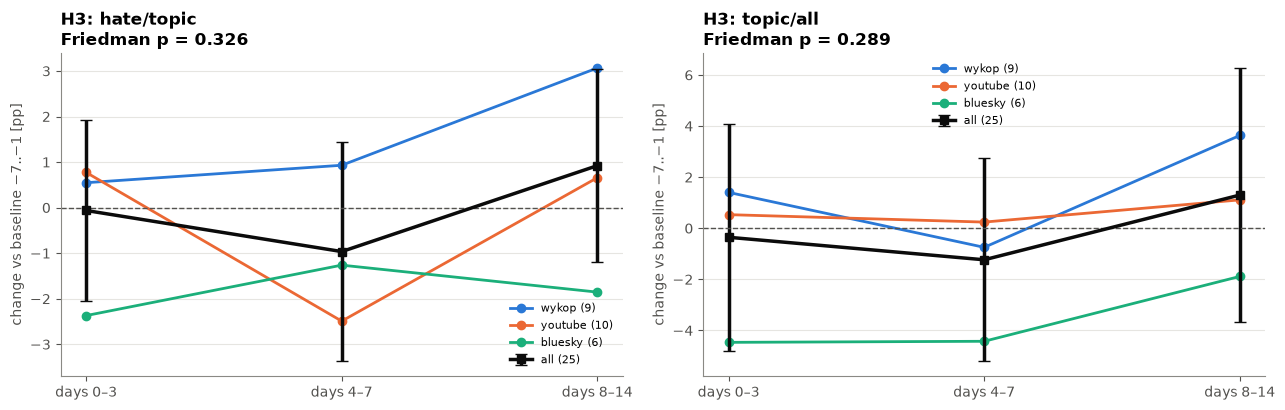

In [32]:
def window_pct(d, col, lo, hi):
    w = d[d["relative_day"].between(lo, hi)]
    return (100 * w[col].mean() if len(w) >= MIN_DAILY_N * (hi - lo + 1) else np.nan), len(w)


h3_rows = []
for metric in METRICS:
    for cell in E(metric).dropna(subset=["log OR"])["cell"]:
        d, col = subset(df[df["cell"] == cell], metric)
        base, nb_ = window_pct(d, col, *BASELINE)
        row = {"metric": metric, "cell": cell, "platform": cell.split(":")[0], "baseline %": base}
        for name, (lo, hi) in H3_WINDOWS.items():
            v, _ = window_pct(d, col, lo, hi)
            row[name] = v - base if pd.notna(v) and pd.notna(base) else np.nan
        h3_rows.append(row)
h3 = pd.DataFrame(h3_rows)

h3_tests = []
for metric in METRICS:
    t = h3[h3["metric"] == metric].dropna(subset=list(H3_WINDOWS))
    fr = friedmanchisquare(*[t[w] for w in H3_WINDOWS]) if len(t) >= 3 else None
    ps = [wilcoxon(t[w]).pvalue if (t[w] != 0).any() else 1.0 for w in H3_WINDOWS]
    h3_tests.append({"metric": metric, "cells": len(t), "p Friedman": fr.pvalue if fr else np.nan,
                     **{f"{w}: mean pp": t[w].mean() for w in H3_WINDOWS},
                     **{f"p (Holm) {w} vs baseline": p for w, p in zip(H3_WINDOWS, holm(pd.Series(ps)).values)}})
h3_tests = pd.DataFrame(h3_tests).set_index("metric")
display(fmt_p(h3_tests, 3))

fig, axes = plt.subplots(1, len(METRICS), figsize=(6.5 * len(METRICS), 4.2), squeeze=False)
for ax, metric in zip(axes[0], METRICS):
    t = h3[h3["metric"] == metric].dropna(subset=list(H3_WINDOWS))
    for p in PL:
        tp = t[t["platform"] == p]
        if len(tp):
            ax.plot(list(H3_WINDOWS), tp[list(H3_WINDOWS)].mean(), marker="o", color=PLATFORM_COLORS[p], label=f"{p} ({len(tp)})")
    m, s = t[list(H3_WINDOWS)].mean(), t[list(H3_WINDOWS)].std() / np.sqrt(max(len(t), 1))
    ax.errorbar(list(H3_WINDOWS), m, yerr=1.96 * s, color=INK, lw=2.5, marker="s", capsize=4, label=f"all ({len(t)})")
    ax.axhline(0, color=INK2, ls="--", lw=1)
    ax.set_ylabel("change vs baseline −7..−1 [pp]")
    ax.set_title(f"H3: {metric}\nFriedman p = {h3_tests.loc[metric, 'p Friedman']:.3g}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 8c. Hypothesis verdicts

In [33]:
def verdict_h1(metric):
    r = readme[(readme["hypothesis"] == "H1") & (readme["metric"] == metric)].iloc[0]
    sig = (E(metric)["direction"] != "–").sum()
    if r["p"] < ALPHA:
        return "supported" if sig else "partially", f"Wilcoxon p = {r['p']:.3g}; significant cells: {sig}"
    return ("partially" if sig else "no evidence"), f"Wilcoxon p = {r['p']:.3g}; significant cells: {sig}/{E(metric)['log OR'].notna().sum()}"


def verdict_simple(h, metric, test_contains):
    r = readme[(readme["hypothesis"] == h) & (readme["metric"] == metric) & readme["test"].str.contains(test_contains, regex=False)].iloc[0]
    return ("supported" if r["p"] < ALPHA else "no evidence"), f"{r['test']}: p = {r['p']:.3g}"


rows = []
for metric in METRICS:
    v, why = verdict_h1(metric)
    rows.append({"hypothesis": "H1", "metric": metric, "verdict": v, "reason": why})
    v, why = verdict_simple("H2", metric, "by type")
    rows.append({"hypothesis": "H2", "metric": metric, "verdict": v, "reason": why})
    p3 = h3_tests.loc[metric, "p Friedman"]
    rows.append({"hypothesis": "H3", "metric": metric, "verdict": "supported" if p3 < ALPHA else "no evidence",
                 "reason": f"Friedman p = {p3:.3g}"})
    vr, wr = verdict_simple("H4", metric, "reaction")
    vl, wl = verdict_simple("H4", metric, "level")
    v = "supported" if vr == "supported" else ("partially" if vl == "supported" else "no evidence")
    rows.append({"hypothesis": "H4", "metric": metric, "verdict": v, "reason": f"{wr}; {wl}"})
verdicts = pd.DataFrame(rows).set_index(["hypothesis", "metric"])
display(verdicts)

,,verdict,reason
hypothesis,metric,,
H1,hate/topic,partially,Wilcoxon p = 1; significant cells: 2/25
H2,hate/topic,no evidence,Kruskal–Wallis: pp change by type: p = 0.397
H3,hate/topic,no evidence,Friedman p = 0.326
H4,hate/topic,partially,Kruskal–Wallis: reaction (pp change): p = 0.174; Kruskal–Wallis: level (before %): p = 3.98e-05
H1,topic/all,partially,Wilcoxon p = 0.672; significant cells: 3/25
H2,topic/all,no evidence,Kruskal–Wallis: pp change by type: p = 0.211
H3,topic/all,no evidence,Friedman p = 0.289
H4,topic/all,partially,Kruskal–Wallis: reaction (pp change): p = 0.733; Kruskal–Wallis: level (before %): p = 8.33e-05


### Conclusions from the additional analyses

- **H1 (Wilcoxon):** no change before → after: p = 0.99, r ≈ 0; increase in 12 of 27 cells, median change −0.6 pp.
  Only 2 cells are significant after Holm: the ICE raids on Wykop (24% → 32%, ↑) and Ceuta on Bluesky (↓). → **partially**
  (individual events, no general effect; likewise the meta-analysis in section 1d: OR 1.01, p = 0.72).
- **H2 (Kruskal–Wallis):** p = 0.30, Dunn with no significant pairs. → **no evidence.**
- **H3 (Friedman):** p = 0.24; mean change +0.0 / −1.0 / +0.9 pp on days 0–3 / 4–7 / 8–14, no window differs from
  the baseline. There is no peak right after the event and no fading. → **no evidence** (the same answer as in the LLM analysis).
- **H4 (Kruskal–Wallis):** the **level** of hate on the migration topic differs between platforms (p < 0.001): YouTube 44% >
  Wykop 34% > Bluesky 19% (Dunn: YouTube differs from both, Wykop vs Bluesky p = 0.06); the **reaction** to events does not
  (p = 0.17). → **partially: different level, same reaction.**
- **Summary:** on 11 events and HerBERT hate the picture is the same as in Ola's LLM analysis: events do not
  systematically raise hate, the effects are isolated and go in different directions, platforms differ in level, not in reaction.